# Week 9 on top of week 6  — DX 799 Mod C3 — Deb Halder — Fall 2026
## Phishing Email Detection: Dataset 1 — Week9(gradient Boost) and week6(Decision Tree, Random Forest and AdaBoost)

**Objective week 9:** On the same dataset as we worked on week 6 (Dataset 1) I want to use gradient Boost so as I can compare the results and  have a better understanding. Since my computer got changed I re-executed the week6 as well for this flow . Week6 will not be featureing the Milestone 2 report and only Week6 will be.

**Execution status:** Saved outputs record the completed data preparation and
analysis in **Sections 1–8**, manual gradient boosting in **Sections 20–27**,
scikit-learn regularization and discussion in **Sections 30–36 and 38–39**,
grouped early stopping and discussion in **Sections 40–45**, leaf-limit
tuning in **Sections 50–54**, and **50 Ray Tune/Optuna trials** with final
evaluation and discussion in **Sections 60–68**. The learning-rate search is
restricted to **0.1–0.3**. These are development results, not proof that
overfitting is absent.

**Data preparation and analysis**

- **Sections 1–4 — Prepare the data:** Read the dataset, inspect missing text
  and email lengths, clean and deduplicate emails, create grouped training/holdout
  splits, and prepare TF-IDF features.
- **Sections 5–6 — Analyze the features:** Perform univariate and bivariate
  analysis using `corpus_eda`. Its nine count features use `log1p`, and the EDA
  includes the full prepared corpus. Model inputs retain raw counts.

**Week 9 execution flow**

- **Sections 7–8 — Reuse the prepared inputs:** Use the TF-IDF plus nine raw
  count features assembled here as inputs to the Week 9 experiments.
- **Sections 20–24 — Explore manual gradient boosting:** Introduce the sample's
  residual-fitting approach, set aside grouped validation rows, define the small-tree
  helpers, search tree counts/learning rates/leaf limits, and inspect error curves.
- **Sections 25–27 — Strengthen validation and evaluate:** Compare minimum leaf
  sizes across three grouped folds, apply the one-standard-error selection rule,
  refit the selected model, evaluate the filtered holdout, and display the first
  small tree. The following unnumbered comments interpret these results.
- **Sections 30–36 — Compare scikit-learn regularization:** Define shrinkage,
  row-sampling, and feature-sampling cases; measure performance by boosting stage;
  run grouped validation; inspect tuning and overfitting curves; then refit and
  evaluate the selected classifier.
- **Sections 38–39 — Interpret the regularization results:** Discuss classification
  performance and the actions taken to assess and control overfitting.
- **Sections 40–43 — Apply grouped early stopping:** Stop adding trees when
  grouped validation improvement stalls, inspect fold curves, and refit the
  selected count for the holdout comparison.
- **Sections 44–45 — Assess early stopping:** Discuss classification performance,
  validation loss, accuracy gaps, and whether the stopping rule improved the
  measured results.
- **Sections 50–54 — Tune leaf limits:** Reuse fitted paths, compare eight
  maximum-leaf/minimum-leaf-size combinations, select using validation loss and
  leaf restrictions, and inspect tuning performance and accuracy gaps.
- **Sections 60–63 — Run Ray Tune with Optuna:** Reserve audit rows, learn the
  text-length cap and TF-IDF only from fitting rows, define the hyperparameter
  space with learning rates **0.1–0.3**, and run 50 trials using grouped validation
  and early stopping to choose each trial's tree count.
- **Section 64 — Freeze the selection:** Apply the one-standard-error and
  phishing-recall rule using inner validation only.
- **Sections 65–66 — Audit and evaluate:** Assess the frozen selection on reserved
  audit rows, then refit on all original training rows and evaluate the filtered
  holdout. Recompute the previous 990-tree baseline with the same corrected
  preprocessing for comparison.
- **Sections 67–68 — Discuss performance and overfitting:** Compare validation,
  audit, and holdout results, accuracy gaps, phishing precision/recall, and error
  counts. Earlier experiments inherit the corpus-wide text cap; Section 61
  corrects it. Repeated holdout use limits claims about future email performance.

Safe=0 and Phishing=1. Vocabulary and IDF are refitted inside each CV training
fold; raw count features need no scaling for these tree-based methods. Labels,
group hashes, and source metadata are excluded from predictors. No threshold
optimization is implemented. Each method documents its inputs and return types.

Dataset: https://www.kaggle.com/datasets/subhajournal/phishingemails.


## 1. Imports and configuration

`MAX_FEATURES_TFIDF=5000` caps the vocabulary; it does not guarantee exactly
5,000 features. Unigrams represent individual words, and bigrams represent
adjacent pairs after tokenization and stopword filtering. `MIN_DF=5` requires
a term to occur in at least five emails in the data used to fit that vectorizer.


In [179]:
# Load text-processing, sparse-matrix, plotting, and splitting dependencies.
# Keep dataset/feature settings in one place so preparation and modeling agree.

import hashlib
import html
import re
from collections import Counter
from html.parser import HTMLParser
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedGroupKFold
from IPython.display import display

# Reuse one seed for split and sample reproducibility; max_features is a vocabulary cap.
# min_df removes very rare terms; (1, 2) includes individual words and two-word phrases.
RANDOM_STATE = 42
DATA_PATH = Path('./dataset/phishing_email_1_dataset/Phishing_Email.csv')
TEXT_COLUMN = 'word_text'  # TF-IDF filters the shared NLTK stopwords from this text view.
TARGET_COLUMN = 'label'
MAX_FEATURES_TFIDF = 5000
MIN_DF = 5
NGRAM_RANGE = (1, 2)  # use 1 and 2 word phrases for TF-IDF features; (1, 1) would be single words only

sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 70)

# Reuse installed NLTK data; download only a missing resource.
for resource, package in [
    ('corpora/stopwords', 'stopwords'),
    ('tokenizers/punkt_tab/english/', 'punkt_tab'),
]:
    try:
        nltk.data.find(resource)
    except LookupError:
        if not nltk.download(package, quiet=True):
            raise RuntimeError(f'Could not install the NLTK resource: {package}')


## 2. Download and read the original data

Download `subhajournal/phishingemails` with KaggleHub and save `Phishing_Email.csv`
to `DATA_PATH`: `./dataset/phishing_email_1_dataset/Phishing_Email.csv`.
The download cell uses a temporary folder, copies the CSV to the project folder,
loads it into `df_phishing_email`, and automatically removes the temporary files.
Running it again downloads the dataset and replaces the local CSV.

The notebook environment needs `kagglehub` with `output_dir` support. If needed,
install or update it with `%pip install -U kagglehub` in a separate cell.

Keep the original email text available for URL counts and text cleaning. Do not
remove stopwords or delete raw text in place. The reused corpus method below
handles empty records, exact duplicates, and conflicting labels.


In [180]:
import shutil
from tempfile import TemporaryDirectory

import kagglehub

destination_dir = DATA_PATH.parent
destination_dir.mkdir(parents=True, exist_ok=True)
saved_file = DATA_PATH

# Download into a temporary folder and remove it automatically after copying/loading.
with TemporaryDirectory(prefix="phishingemails-") as temporary_dir:
    download_path = Path(
        kagglehub.dataset_download(
            "subhajournal/phishingemails",
            output_dir=temporary_dir,
        )
    )

    # Select the expected CSV so an unrelated file cannot become the training data.
    csv_files = sorted(download_path.rglob("*.csv"))
    if not csv_files:
        raise FileNotFoundError("No CSV file was found in the Kaggle download.")
    matching_files = [file for file in csv_files if file.name == DATA_PATH.name]
    if len(matching_files) != 1:
        raise FileNotFoundError(
            f"Expected exactly one {DATA_PATH.name} in the Kaggle download; "
            f"found {[str(file.relative_to(download_path)) for file in csv_files]}."
        )
    csv_file = matching_files[0]

    shutil.copy2(csv_file, saved_file)
    df_phishing_email = pd.read_csv(saved_file)
    print("Loaded df_phishing_email from:", saved_file)
    print("Shape:", df_phishing_email.shape)

print("Deleted temporary download folder:", temporary_dir)


100%|██████████| 18.0M/18.0M [00:00<00:00, 33.1MB/s]

Extracting files...


Loaded df_phishing_email from: dataset/phishing_email_1_dataset/Phishing_Email.csv
Shape: (18650, 3)
Deleted temporary download folder: /var/folders/bm/9gklnwns2kxcypy3sp68vlc80000gn/T/phishingemails-kasyy77t


In [181]:
# Validate the file schema before cleaning. Encode Phishing as the positive class.

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f'Expected {DATA_PATH.resolve()}. Run this notebook from the project '
        'folder and run the Kaggle download cell above.'
    )

required_columns = {'Email Text', 'Email Type'}
if not required_columns.issubset(df_phishing_email.columns):
    raise ValueError(f'The CSV must contain {sorted(required_columns)}.')

df_phishing_email = df_phishing_email.rename(
    columns={'Email Text': 'text_combined', 'Email Type': 'label'}
)
# drop Unnamed column: it is an old CSV index, not an email feature.
df_phishing_email = df_phishing_email.drop(
    columns=[c for c in df_phishing_email if c.startswith('Unnamed:')]
)
raw_labels = df_phishing_email['label'].astype('string').str.strip()
label_mapping = {'Safe Email': 0, 'Phishing Email': 1}
unknown = raw_labels.notna() & ~raw_labels.isin(label_mapping)
if unknown.any():
    raise ValueError(f'Unexpected labels: {raw_labels[unknown].unique().tolist()}')
df_phishing_email['label'] = raw_labels.map(label_mapping).astype('Int64')




## Dataframe analysis 

### Inspect the dataset before cleaning

Check missing text, email lengths, and class labels before defining the cleaning
and truncation steps. The dataset labels are **Safe = 0** and **Phishing = 1**.


In [182]:
# Lets analyse the data  in the captured dataframe

df_phishing_email.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18650 entries, 0 to 18649
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   text_combined  18634 non-null  object
 1   label          18650 non-null  Int64 
dtypes: Int64(1), object(1)
memory usage: 309.7+ KB


### Character count summary


In [183]:
# Count raw characters, including spaces and markup; preserve missing text.
df_phishing_email['char_count'] = df_phishing_email['text_combined'].astype('string').str.len()
char_counts = df_phishing_email['char_count'].dropna().astype('int64')
print(f"Missing text: {df_phishing_email['char_count'].isna().sum():,} rows")
print(f"Empty text: {char_counts.eq(0).sum():,} rows")
display(char_counts.describe(percentiles=[.25, .5, .75, .9, .95, .99, .999]).to_frame())


Missing text: 16 rows
Empty text: 0 rows


,char_count
count,1.863400e+04
mean,2.755654e+03
std,1.248677e+05
min,1.000000e+00
25%,4.040000e+02
50%,8.815000e+02
75%,1.880000e+03
90%,3.815000e+03
95%,6.356350e+03
99%,1.566284e+04


### Inspect the longest emails and their character counts


In [184]:
# Inspect the longest rows without displaying their full email content.
print('Ten longest emails (original row index):')
display(df_phishing_email.loc[char_counts.nlargest(20).index, ['label', 'char_count']])


Ten longest emails (original row index):


,label,char_count
12500,0,17036692
11294,0,194978
8068,1,129635
15993,0,120761
10804,0,107989
5474,0,103893
7375,0,92786
3762,0,90646
9232,0,87972
11912,0,87972


In [185]:
# Preview the first 160 characters of the 15 longest emails.
top_emails = df_phishing_email.nlargest(15, 'char_count')
top_email_preview = top_emails[['label', 'char_count']].copy()
top_email_preview['text_preview'] = top_emails['text_combined'].str[:160]
with pd.option_context('display.max_colwidth', None):
    display(top_email_preview)


,label,char_count,text_preview
12500,0,17036692,"0,""Subject: great part-time or summer job ! * * * * * * * * * * * * * * * we have display boxes with credit applications that we need to place in the small owne"
11294,0,194978,"change your settings: http://blo.gs/settings.phphere is your list of updated weblogs.Oct 04, 2002 3:03am\n love-always.net\n http://love-always.net/\n M"
8068,1,129635,=?GB2312?B?yNW12squ0ru97NbQufq5+rzKtefX08nosbihorXn19PUqsb3vP6horHtw+bM?= =?GB2312?B?+dew1bnAwLvhu7bTrbGow/uyztW5o6E=?=\nTo: fma@zzzzason.org\nContent-Type: mult
15993,0,120761,"enron mentions enron discusses credit line of $ 1 billion to $ 2 billion with banks the wall street journal , 10 / 29 / 01 manager ' s journal : how enron ran o"
10804,0,107989,------------------------ Yahoo! Groups Sponsor ---------------------~-->\n4 DVDs Free +s&p Join Now\nhttp://us.click.yahoo.com/pt6YBB/NXiEAA/Ey.GAA/26EolB/TM\n----
5474,0,103893,"enron mentions dynegy is in talks on purchasing enron - - - deal would include infusion of cash to assist firm in shoring up finances the wall street journal ,"
7375,0,92786,"enron mentions - 11 / 21 / 01 enron stock , bonds receive more hits following warning the wall street journal , 11 / 21 / 01 enron , vdeg may bid to export bulg"
3762,0,90646,"enron mentions - 11 / 23 / 01 premiums stay high on enron ' s near options , and ` doubling up ' date looms for tax losses the wall street journal , 11 / 23 / 0"
9232,0,87972,"enron mentions enron replaces fastow as finance chief - - - mcmahon takes over post ; move follows concerns over partnership deals the wall street journal , 10"
11912,0,87972,"enron mentions enron replaces fastow as finance chief - - - mcmahon takes over post ; move follows concerns over partnership deals the wall street journal , 10"


### What the longest-email previews show

The previews contain readable passages, headers, and encoded text. A short
preview cannot establish that an entire email is readable or free of artifacts.
The cleaning helper does not decode MIME or base64 content.

We retain these rows and later truncate the cleaned `word_text` at its
99th-percentile length. Original `text` is preserved for URL and sentence
features; removing URLs from `word_text` does not remove their raw-text counts.


### Email counts by size percentile


In [186]:
# Group non-missing emails by size percentile; equal lengths stay in the same band.
if not char_counts.empty:
    size_percentiles = [0, .25, .5, .75, .9, .95, .99, .999, 1]
    size_cutoffs = char_counts.quantile(size_percentiles)
    distribution_rows = []
    for lower, upper in zip(size_percentiles[:-1], size_percentiles[1:]):
        lower_limit = -np.inf if lower == 0 else size_cutoffs.loc[lower]
        band = char_counts[(char_counts > lower_limit) & (char_counts <= size_cutoffs.loc[upper])]
        distribution_rows.append({
            'percentile_band': f'{100 * lower:g}–{100 * upper:g}%',
            'min_characters': band.min(),
            'max_characters': band.max(),
            'email_count': len(band),
        })
    percentile_distribution = pd.DataFrame(distribution_rows).set_index('percentile_band')
    percentile_distribution[['min_characters', 'max_characters']] = (
        percentile_distribution[['min_characters', 'max_characters']].astype('Int64')
    )
    percentile_distribution['percent_of_emails'] = (
        100 * percentile_distribution['email_count'] / len(char_counts)
    ).round(2)
    percentile_distribution['emails_above_band'] = (
        len(char_counts) - percentile_distribution['email_count'].cumsum()
    )
    print('Email size distribution by percentile (missing text excluded):')
    display(percentile_distribution)


Email size distribution by percentile (missing text excluded):


,min_characters,max_characters,email_count,percent_of_emails,emails_above_band
percentile_band,,,,,
0–25%,1,404,4671,25.07,13963
25–50%,405,881,4646,24.93,9317
50–75%,882,1880,4659,25.00,4658
75–90%,1881,3815,2795,15.00,1863
90–95%,3816,6356,931,5.00,932
95–99%,6357,15628,745,4.00,187
99–99.9%,15680,69490,168,0.90,19
99.9–100%,71757,17036692,19,0.10,0


### Email length histograms


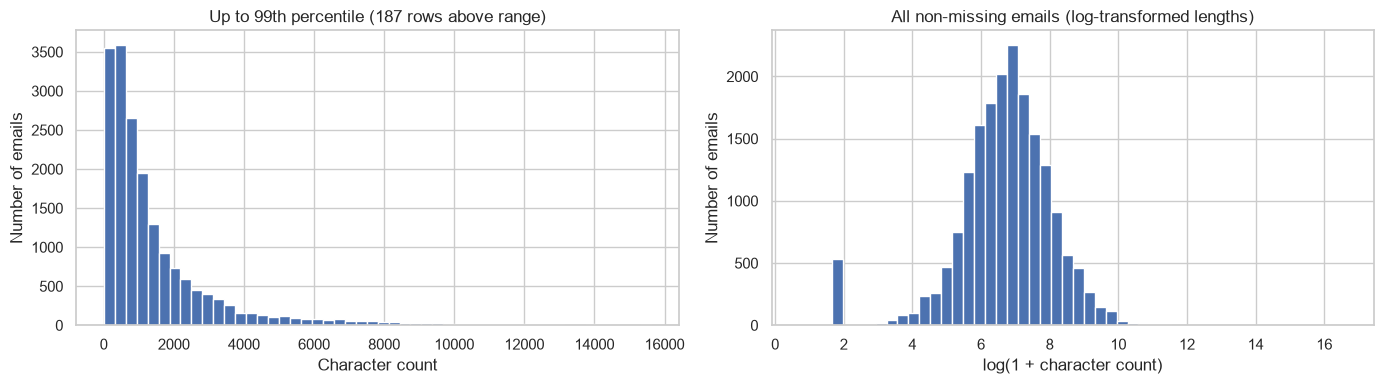

In [187]:
# Show lengths and the full distribution, including extreme values.
if not char_counts.empty:
    char_limit = char_counts.quantile(.99)
    above_limit = char_counts.gt(char_limit).sum()
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].hist(char_counts[char_counts <= char_limit], bins=50, edgecolor='white')
    axes[0].set(
        title=f'Up to 99th percentile ({above_limit:,} rows above range)',
        xlabel='Character count', ylabel='Number of emails',
    )
    axes[1].hist(np.log1p(char_counts), bins=50, edgecolor='white')
    axes[1].set(
        title='All non-missing emails (log-transformed lengths)',
        xlabel='log(1 + character count)', ylabel='Number of emails',
    )
    plt.tight_layout()
    plt.show()


### Scatter plot and candidate cutoff


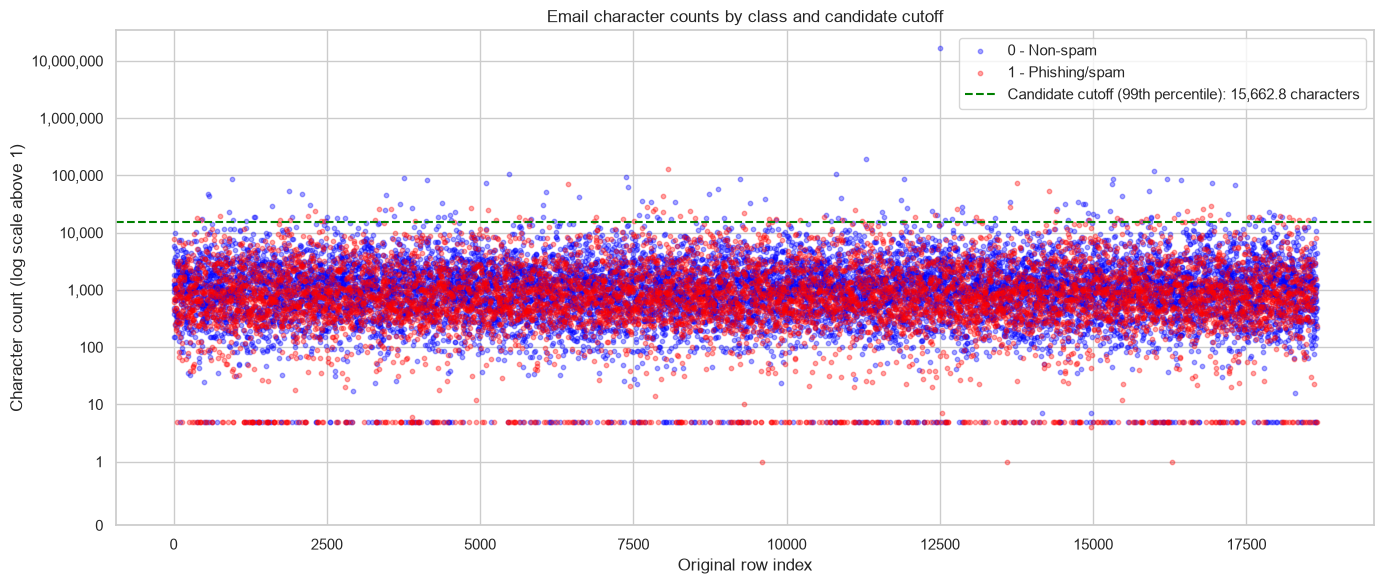

Emails above cutoff: 187


In [188]:
# Use the 99th percentile of character counts as the candidate cutoff.
char_review_threshold = char_counts.quantile(.99)

fig, ax = plt.subplots(figsize=(14, 6))
email_labels = df_phishing_email.loc[char_counts.index, 'label']
for value, color, name in [(0, 'blue', '0 - Non-spam'), (1, 'red', '1 - Phishing/spam')]:
    class_counts = char_counts[email_labels.eq(value)]
    ax.scatter(class_counts.index, class_counts, color=color, label=name, s=10, alpha=.35, rasterized=True)

ax.axhline(
    char_review_threshold, color='green', linestyle='--',
    label=f'Candidate cutoff (99th percentile): {char_review_threshold:,.1f} characters',
)
ax.set_yscale('symlog', linthresh=1)
ax.set_ylim(0, max(char_counts.max(), 1) * 2)
ax.yaxis.set_major_formatter('{x:,.0f}')
ax.set(
    title='Email character counts by class and candidate cutoff',
    xlabel='Original row index', ylabel='Character count (log scale above 1)',
)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

print(f'Emails above cutoff: {char_counts.gt(char_review_threshold).sum():,}')


### Retain long emails while limiting processed text

The raw-text 99th percentile is **15,662.84 characters**. **187 emails** exceed
it: **113 Safe and 74 Phishing**. Length alone does not establish whether an
email contains attachments or whether its label is reliable.

The preprocessing below calculates a separate 99th-percentile cutoff on
**cleaned, deduplicated `word_text`**, then keeps only the beginning of longer
texts. This retains the rows and reduces text processing, but can discard useful
information. The original `text` column remains available for structural counts.


In [189]:
df_combined = df_phishing_email.copy()
print(f'Loaded {len(df_combined):,} original rows from {DATA_PATH}')
display(df_combined['label'].value_counts(dropna=False).rename('raw_rows').to_frame())

Loaded 18,650 original rows from dataset/phishing_email_1_dataset/Phishing_Email.csv


,raw_rows
label,
0,11322
1,7328


## 3. Data preprocessing methods

For this initial preparation, clean each email into `word_text`, retain its
original `text`, truncate the cleaned text, and reuse these columns to compute
the nine count features. The prepared corpus feeds the grouped split,
full-corpus EDA, and TF-IDF augmentation.


### Preprocessing logic

`df_combined` → `prepare_count_dataset()` → prepared `corpus` → grouped split → TF-IDF + nine counts

1. **Validate input:** Check the text and label columns, accept numeric 0/1 labels, and exclude missing labels.
2. **Clean text:** Preserve original emails in `text`; create `word_text` by removing parsed HTML tags, script/style contents, URLs, email addresses, numbers, and punctuation other than internal apostrophes. Stopwords remain at this stage.
3. **Filter and deduplicate:** Remove blank or unusable emails, hash whitespace-normalized original text into `content_hash`, exclude conflicting labels, and retain one row per exact duplicate group.
4. **Create split groups:** Build `group_id` from normalized words using the protected-stopword policy. Use the full word sequence when fewer than eight filtered words remain. These keys identify matching normalized sequences, not all paraphrases.
5. **Truncate cleaned text:** Calculate the 99th-percentile character length on the prepared corpus, cap `word_text` at the rounded-up cutoff, and copy it into `text_combined`. Keep original `text` unchanged. Group IDs were created before this truncation.
6. **Extract word features:** Remove unprotected NLTK stopwords from capped `word_text`; count retained words and urgency, account, threat, financial, and official terms. Phrase matches preserve adjacency in the cleaned word sequence.
7. **Extract structural features:** Count HTTP/HTTPS occurrences in original `text` and sentences in its visible text after removing URLs/addresses. These three counts plus the six word features make nine predictors.
8. **Assemble and split:** Join counts and `clean_text` to the prepared rows, then create an approximately 80/20 grouped train/holdout split and three grouped training CV folds.
9. **Build model inputs:** Fit TF-IDF on fitting rows and append the nine counts. During CV, vocabulary and IDF are learned separately inside each training fold; labels and group identifiers are excluded from predictors.

**Limitation of this initial workflow:** The text-length cutoff is learned from
the full prepared corpus before splitting. Fold-specific TF-IDF does not remove
that preprocessing leakage. Full-corpus EDA also includes holdout rows, so these
results are exploratory rather than a fully isolated final evaluation.


In [190]:
def truncate_email_text(frame, text_column="text_combined", percentile=.99):
    """Cap text using char_count's percentile and return a copy without char_count."""
    if not 0 < percentile <= 1:
        raise ValueError("percentile must be greater than 0 and at most 1.")

    cutoff = frame["char_count"].quantile(percentile)
    if pd.isna(cutoff):
        raise ValueError("char_count must contain non-missing lengths.")

    truncated = frame.copy()
    above_cutoff = truncated["char_count"].gt(cutoff).fillna(False)
    truncated.loc[above_cutoff, text_column] = (
        truncated.loc[above_cutoff, text_column]
        .astype("string")
        .str.slice(stop=int(np.ceil(cutoff)))
    )
    return truncated.drop(columns="char_count")


In [191]:
"""Nine count features and a TF-IDF comparison for Phishing_email dataset.

We are using a numeric label 0=legitimate, 1=phishing.  

"""

# Keep alphabetic words and internal apostrophes; digits and underscores are excluded.
TOKEN_PATTERN = r"(?u)\b[^\W\d_]+(?:'[^\W\d_]+)*\b"

WORD_RE = re.compile(TOKEN_PATTERN)

URL_RE = re.compile(r"\b(?:https?://|www\.)[^\s<>\"']+", re.I)

EMAIL_RE = re.compile(r"\b[^\s<>@]+@[^\s<>@]+\.[^\s<>@]+\b")

# Five fixed keyword categories complement the four structural/length features.
# Terms may overlap: a longer phrase and its component term can both contribute counts.
TERM_CATEGORIES = {
    "urgency": {
        "urgent", "immediate", "immediately", "action required", "attention required", "respond now",
        "expires", "expiring", "deadline", "limited time", "act now", "urgent action", "click",
        "here", "now", "free", "offer", "buy", "purchase", "donate", "subscribe", "register",
        "sign up", "get started", "learn more",
    },
    "account": {
        "verify", "verification", "authenticate", "confirm", "validate", "reactivate",
        "suspended", "blocked", "restricted", "limited", "unlock", "secure", "security",
        "access", "password", "login", "account", "username", "credential",
    },
    "threat": {
        "terminate", "deactivate", "delete", "removal", "suspend", "restriction",
        "warning", "risk", "compromised", "suspicious", "unauthorized", "disabled",
        "cancelled", "violation", "breach", "illegal",
    },
    "financial": {
        "claim", "prize", "winner", "won", "reward", "bonus", "payment", "refund",
        "deposit", "transfer", "transaction", "million", "inheritance", "lottery",
        "cash", "credit", "bank", "money", "fund", "balance",
    },
    "official": {
        "official", "authorized", "authentication", "notification", "notice", "alert",
        "department", "administration", "support", "service", "helpdesk",
    },
}

# HTMLParser calls the handlers below when feed() reads the HTML.


class VisibleText(HTMLParser):
    """Collect text outside script/style elements using HTMLParser callbacks.

    Attributes
    ----------
    parts : list[str]
        Accepted text fragments in encounter order; joined by visible_email_text.
    suppressed : int
        Number of currently open script/style elements used to suppress their data.

    Notes
    -----
    This is a text extractor, not a browser renderer: it does not interpret CSS,
    recover MIME attachments, or read text from images.
    """
    def __init__(self):
        """Initialize text fragments and the script/style suppression counter."""
        super().__init__(convert_charrefs=True)
        self.parts = []
        self.suppressed = 0

    def handle_starttag(self, tag, attrs):
        """Start suppressing text when a script or style element opens."""
        if tag in {"script", "style"}:
            self.suppressed += 1

    def handle_endtag(self, tag):
        """End suppression when a script or style element closes."""
        if tag in {"script", "style"} and self.suppressed:
            self.suppressed -= 1

    def handle_data(self, data):
        """Collect text only when the suppression counter is zero."""
        if not self.suppressed:
            self.parts.append(data)


def visible_email_text(value):
    """Extract visible text while preserving case and sentence punctuation.

    Parameters
    ----------
    value : scalar object
        Raw email value, usually str; a missing scalar returns an empty string.

    Returns
    -------
    str
        Text without parsed HTML tags or script/style contents, with entities decoded
        and curly apostrophes normalized. Case and punctuation are otherwise retained.
    """
    if pd.isna(value):
        return ""
    text = str(value)
    if re.search(r"</?[A-Za-z][^>]*>", text):
        parser = VisibleText()
        parser.feed(text)
        text = " ".join(parser.parts)
    return html.unescape(text).replace("\u2019", "'")


def clean_email_text(value):
    """Basic word-only view; keep the original text separately for URL features.

    Does not decode MIME/base64/quoted-printable or recover previously removed URLs.
    Preserves apostrophes/negation and word order; removes tags, URLs and addresses.

    Parameters
    ----------
    value : scalar object
        Raw email text or a missing scalar, passed through visible_email_text first.

    Returns
    -------
    str
        Case-folded, space-separated alphabetic/apostrophe tokens in original order.
        Stopwords are still present: the caller applies the shared stopword policy.
    """
    text = visible_email_text(value).casefold()
    text = URL_RE.sub(" ", text)
    text = EMAIL_RE.sub(" ", text)
    return " ".join(WORD_RE.findall(text))


def get_protected_feature_words():
    """Collect every token from the five keyword categories among the nine features.

    Phrase components are protected , such as 'up' in 'sign up'. URL and
    sentence counts are extracted from original text, before stopword removal.

    Parameters
    ----------
    None
        Reads the shared TERM_CATEGORIES dictionary and text-normalization rules.

    Returns
    -------
    set[str]
        Unique normalized tokens from every category term, including phrase components.
        This is a set of words to retain, not an additional stopword source.
    """
    return {
        word
        for category in TERM_CATEGORIES.values()
        for term in category
        for word in clean_email_text(term).split()
    }


def get_effective_nltk_stopwords(stop_words=None):
    """Return NLTK English stopwords minus feature words and protected negations.

    Only NLTK stopwords or a subset are accepted; extra words are rejected, and negations are preserved.

    Parameters
    ----------
    stop_words : iterable[str] | None, default None
        None uses the full NLTK English list before applying feature-word and negation exclusions.

    Returns
    -------
    set[str]
        NLTK stopwords excluding protected feature words and negations.

    Raises
    ------
    ValueError
        If a supplied word is not in the NLTK English stopword set.
    LookupError or  the NLTK stopwords corpus has not been installed.
    """
    nltk_words = set(stopwords.words('english'))
    if stop_words is None:
        candidate_words = nltk_words
    else:
        candidate_words = {word.casefold() for word in stop_words}
        unsupported = candidate_words - nltk_words
        if unsupported:
            raise ValueError(f'Only NLTK English stopwords are allowed: {sorted(unsupported)}')

    # Preserve category words, including every component of a phrase.
    protected = get_protected_feature_words()
    # Protect common negation words so key sentiment signals are preserved.
    protected.update({'no', 'not', 'nor', 'never', 'cannot', "don't", "doesn't", "isn't", "won't"})
    protected.update(word for word in nltk_words if word.endswith("n't"))
    return candidate_words - protected

# One shared, corpus-supplied list; no custom email/header/HTML stopwords.
NLTK_STOP_WORDS = set(stopwords.words('english'))
PROTECTED_FEATURE_WORDS = get_protected_feature_words()
EFFECTIVE_STOP_WORDS = get_effective_nltk_stopwords()

assert EFFECTIVE_STOP_WORDS <= NLTK_STOP_WORDS
assert EFFECTIVE_STOP_WORDS.isdisjoint(PROTECTED_FEATURE_WORDS)


In [192]:
COUNT_FEATURE_COLUMNS = [
    "http_url_count", "https_url_count", "sentence_count", "total_word_count",
    "urgency_terms_count", "account_terms_count", "threat_terms_count",
    "financial_terms_count", "official_terms_count",
]

# Matching hashes identify equal normalized text, not arbitrary near-duplicates.


def _hash(value):
    """Create a deterministic identifier for a supplied text representation.

    Parameters
    ----------
    value : str
        Text already normalized by the caller; encoded as UTF-8 before hashing.

    Returns
    -------
    str
        64-character SHA-256 hexadecimal digest. Equal input strings have equal hashes;
        hashing itself does not perform fuzzy matching or measure semantic similarity.
    """
    return hashlib.sha256(value.encode("utf-8")).hexdigest()

def prepare_email_corpus(frame, text_column="text_combined", label_column="label"):
    """Return cleaned, 99th-percentile-capped text without char_count or changes to the input.

    Deduplication: Remove exact duplicates, ignoring whitespace differences.
    Conflicts: Exclude identical text with conflicting labels.
    Grouping: Group normalized matches for splitting without deleting or relabeling them.

    Args:
        frame (pandas.DataFrame): Source emails and binary labels.
        text_column (str, default="text_combined"): Original email text column.
        label_column (str, default="label"): Numeric 0/1 label column; exclude missing labels.

    Returns:
        pandas.DataFrame: Unique emails with capped text_column and word_text, original text in text, int64 labels, content_hash, group_id, and a reset index.

    Raises:
        ValueError: Missing columns, invalid labels, or fewer than two classes after cleaning.
    """

    if not {text_column, label_column}.issubset(frame.columns):
        raise ValueError(f"Expected columns {text_column!r} and {label_column!r}.")

    data = frame.copy().reset_index(drop=True)

    data["text"] = data[text_column].fillna("").astype(str)

    target = pd.to_numeric(data[label_column], errors="raise")

    if not target.dropna().isin([0, 1]).all():
        raise ValueError("Labels must be 0 or 1; missing labels will be excluded.")

    data["label"] = target.astype("Int64")

    data = data[data["label"].notna()].copy()

    exact = data["text"].str.replace(r"\s+", " ", regex=True).str.strip()

    # Clean each email once; feature extraction reuses word_text.
    # Keep stopwords here to preserve positions for phrase matching.
    data["word_text"] = data["text"].map(clean_email_text)

    empty_mask = exact.str.casefold().isin(["", "empty"]) | data["word_text"].eq("")
    data = data[~empty_mask].copy()

    data["content_hash"] = exact.loc[data.index].map(_hash)

    counts = data.groupby("content_hash")["label"].nunique()
    consistent = data[~data["content_hash"].isin(counts.index[counts > 1])].copy()

    corpus = consistent.drop_duplicates("content_hash", keep="first").copy()

    grouping_stop_words = get_effective_nltk_stopwords()

    # The normalization creates grouping keys, not learned predictors or relabeled targets.
    def split_key(text):
        """Inner function split text, remove stopwords and then generate hash
        Parameters
        ----------
        text : str
            Normalized word_text; grouping_stop_words is inherited from the enclosing call.

        Returns
        -------
        str
            SHA-256 hash of the stopword-filtered sequence when at least eight tokens
            remain; otherwise hashes the full word sequence to keep short texts specific.
            Only identical resulting sequences are grouped; paraphrases may remain separate.
        """
        words = text.split()
        reduced = [w for w in words if w not in grouping_stop_words]
        # Keep short texts specific rather than group all generic short messages.
        return _hash(" ".join(reduced if len(reduced) >= 8 else words))

    # Keep identical normalized group keys in the same split.
    corpus["group_id"] = corpus["word_text"].map(split_key)

    corpus["label"] = corpus["label"].astype("int64")
    corpus = corpus.reset_index(drop=True)

    if corpus["label"].nunique() != 2:
        raise ValueError("Both classes are required after cleaning.")

    # Count cleaned characters for truncation; the helper drops char_count afterward.
    corpus["char_count"] = corpus["word_text"].str.len()
    corpus = truncate_email_text(corpus, text_column="word_text")
    corpus[text_column] = corpus["word_text"]
    return corpus


In [193]:
# Split original prepared rows before learning any vocabulary, IDF, or scaler.


def split_email_corpus(corpus, holdout_folds=5, cv_folds=3, random_state=42):
    """Approx. 1/holdout_folds held out; groups cannot cross holdout/CV splits.

    Parameters
    ----------
    corpus : pandas.DataFrame
        Prepared rows containing text, label in {0, 1}, and group_id.
    holdout_folds : int, default 5
        Number of grouped folds for the outer split; the first fold becomes holdout.
        Group sizes make the resulting fraction approximate rather than exactly 20%.
    cv_folds : int, default 3
        Number of stratified grouped folds constructed only within training rows.
    random_state : int, default 42
        Seed for reproducible shuffled splits.

    Returns
    -------
    train : pandas.DataFrame
        Training data with its row index reset.
    test : pandas.DataFrame
        Test data with its row index reset.
    splits : list of tuples
        Each tuple contains (fit_positions, validation_positions) for one
        cross-validation split. Both are integer arrays of row positions
        in train, accessed using train.iloc.

    Raises
    ------
    ValueError
        If too few groups exist per class or a resulting partition lacks a class.
    """

    if corpus.groupby("label")["group_id"].nunique().min() < holdout_folds:
        raise ValueError("Too few distinct groups per class for the requested holdout split.")

    splitter = StratifiedGroupKFold(
        n_splits=holdout_folds, shuffle=True, random_state=random_state
    )

    train_idx, test_idx = next(splitter.split(corpus["text"], corpus["label"], corpus["group_id"]))

    train = corpus.iloc[train_idx].reset_index(drop=True)
    test = corpus.iloc[test_idx].reset_index(drop=True)

    if train["label"].nunique() != 2 or test["label"].nunique() != 2:
        raise ValueError("This grouped holdout lacks a class; reconsider the split configuration.")

    if train.groupby("label")["group_id"].nunique().min() < cv_folds:
        raise ValueError("Too few training groups per class for CV.")

    cv = StratifiedGroupKFold(n_splits=cv_folds, shuffle=True, random_state=random_state)
    splits = list(cv.split(train["text"], train["label"], train["group_id"]))

    for fit_idx, valid_idx in splits:
        if any(train.iloc[idx]["label"].nunique() != 2 for idx in (fit_idx, valid_idx)):
            raise ValueError("A grouped CV fold lacks a class; reconsider the split configuration.")

    return train, test, splits


In [194]:
def extract_count_features(corpus, stop_words=None, sentence_tokenizer=None):
    """Return (features, cleaned), preserving corpus.index and excluding labels.

    Args:
        corpus (pd.DataFrame): Original text and precleaned word_text
        stop_words (iterable[str] | None): NLTK English subset or full list if None; protect category words, phrase components, and negations.
        sentence_tokenizer (callable | None): Maps text to a sequence of sentences; defaults to nltk.sent_tokenize.

    Counting rules:
        Words: Count retained alphabetic/apostrophe tokens, excluding URLs, addresses, numbers, and punctuation.
        Terms: Count repeated and overlapping matches; phrases require original word adjacency.
        URLs: Count every raw HTTP/HTTPS occurrence, including those in HTML attributes.
        Sentences: Use visible text without URLs/addresses, before stopword filtering.

    Returns:
        features (pd.DataFrame): Shape (n_emails, 9), with int64 counts in COUNT_FEATURE_COLUMNS order.
        cleaned (pd.Series): Stopword-filtered strings named clean_text.
    """

    if stop_words is None:
        from nltk.corpus import stopwords
        stop_words = set(stopwords.words("english"))

    if sentence_tokenizer is None:
        from nltk.tokenize import sent_tokenize
        sentence_tokenizer = sent_tokenize

    # Check tokenizer availability once.
    sentence_tokenizer("Tokenizer check.")

    # Normalize terms like the stored email words.
    terms = {name: [tuple(clean_email_text(t).split()) for t in sorted(values)]
             for name, values in TERM_CATEGORIES.items()}

    # Protect all phrase components.
    protected = {w for category in terms.values() for term in category for w in term}

    # Preserve category words and negations.
    effective_stop_words = get_effective_nltk_stopwords(stop_words)
    assert effective_stop_words.isdisjoint(protected)

    max_n = max(len(term) for category in terms.values() for term in category)

    raw = corpus["text"]
    records, cleaned = [], []

    for text, word_text in zip(raw, corpus["word_text"]):
        # Keep positions before stopword removal.
        words = word_text.split()
        kept = [(i, w) for i, w in enumerate(words) if w not in effective_stop_words]
        filtered = [w for _, w in kept]
        cleaned.append(" ".join(filtered))

        occurrences = Counter((w,) for w in filtered)

        # Require original adjacency for phrase matches.
        for n in range(2, max_n + 1):
            for i in range(len(kept) - n + 1):
                window = kept[i:i+n]
                if window[-1][0] - window[0][0] == n - 1:
                    occurrences[tuple(w for _, w in window)] += 1

        # Keep punctuation for sentence boundaries.
        visible = EMAIL_RE.sub(" ", URL_RE.sub(" ", visible_email_text(text))).strip()

        record = {
            "http_url_count": len(re.findall(r"\bhttp://[^\s<>\"']+", text, re.I)),
            "https_url_count": len(re.findall(r"\bhttps://[^\s<>\"']+", text, re.I)),
            "sentence_count": len(sentence_tokenizer(visible)) if visible else 0,
            "total_word_count": len(filtered),
        }

        record.update({f"{name}_terms_count": sum(occurrences[t] for t in category)
                       for name, category in terms.items()})
        records.append(record)

    features = pd.DataFrame(records, columns=COUNT_FEATURE_COLUMNS, index=raw.index).astype("int64")

    return features, pd.Series(cleaned, index=raw.index, name="clean_text")


def prepare_count_dataset(frame, stop_words=None, sentence_tokenizer=None):
    """Return the prepared corpus with raw text, nine features, and cleaned text.

    Input columns: text_combined and label. Uses no learned word vocabulary or
    label-based feature selection

    Parameters
    ----------
    frame : pandas.DataFrame
        Original email data with text_combined and numeric label columns.
    stop_words : iterable[str] | None, default None
        Optional NLTK subset passed to extract_count_features.
    sentence_tokenizer : callable(str) -> sequence[str] | None, default None
        Optional sentence tokenizer passed to extract_count_features.

    Returns
    -------
    pandas.DataFrame
        Prepared corpus containing retained text/metadata, int64 label, all nine
        int64 count columns, and clean_text. Original text and word_text remain
        available for the classifier.
    """
    corpus = prepare_email_corpus(frame)
    features, cleaned = extract_count_features(corpus, stop_words, sentence_tokenizer)
    # Re-running on a frame containing feature columns replaces them, not duplicates.
    corpus = corpus.drop(columns=COUNT_FEATURE_COLUMNS + ["clean_text"], errors="ignore")
    return pd.concat([corpus, features, cleaned], axis=1)


In [195]:
# Build the corpus once, then create independent training/holdout partitions.
# Targets and group identifiers are kept alongside the rows but excluded from predictors.

corpus = prepare_count_dataset(df_combined)

In [196]:
print(corpus.info())
print(corpus.head(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17511 entries, 0 to 17510
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   text_combined          17511 non-null  object
 1   label                  17511 non-null  int64 
 2   text                   17511 non-null  object
 3   word_text              17511 non-null  object
 4   content_hash           17511 non-null  object
 5   group_id               17511 non-null  object
 6   http_url_count         17511 non-null  int64 
 7   https_url_count        17511 non-null  int64 
 8   sentence_count         17511 non-null  int64 
 9   total_word_count       17511 non-null  int64 
 10  urgency_terms_count    17511 non-null  int64 
 11  account_terms_count    17511 non-null  int64 
 12  threat_terms_count     17511 non-null  int64 
 13  financial_terms_count  17511 non-null  int64 
 14  official_terms_count   17511 non-null  int64 
 15  clean_text         

In [197]:
display(corpus.describe())

# Summarize cleaned, truncated email lengths, including spaces; preserve missing text.
corpus_char_counts = corpus['word_text'].astype('string').str.len()
print(f"Missing text: {corpus_char_counts.isna().sum():,} rows")
print(f"Empty text: {corpus_char_counts.eq(0).sum():,} rows")
display(corpus_char_counts.dropna().astype('int64').describe(percentiles=[.25, .5, .75, .9, .95, .99, .999]).to_frame('char_count'))


,label,http_url_count,https_url_count,sentence_count,total_word_count,urgency_terms_count,account_terms_count,threat_terms_count,financial_terms_count,official_terms_count
count,17511.000000,17511.000000,17511.000000,17511.000000,17511.000000,17511.000000,17511.000000,17511.000000,17511.000000,17511.000000
mean,0.373194,0.679744,0.055908,33.505282,157.561932,1.634687,0.472674,0.193079,0.999201,0.443036
std,0.483667,23.794861,0.300225,1687.781894,223.525685,3.357187,1.586830,0.824877,3.613842,1.280681
min,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,5.000000,40.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,10.000000,81.000000,1.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.000000,0.000000,19.000000,175.000000,2.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,3131.000000,6.000000,223247.000000,3113.000000,116.000000,36.000000,25.000000,80.000000,30.000000


Missing text: 0 rows
Empty text: 0 rows


,char_count
count,17511.000000
mean,1458.131003
std,2095.040932
min,3.000000
25%,351.000000
50%,732.000000
75%,1611.000000
90%,3367.000000
95%,5486.000000
99%,12994.700000


In [198]:
print(corpus.columns)

Index(['text_combined', 'label', 'text', 'word_text', 'content_hash',
       'group_id', 'http_url_count', 'https_url_count', 'sentence_count',
       'total_word_count', 'urgency_terms_count', 'account_terms_count',
       'threat_terms_count', 'financial_terms_count', 'official_terms_count',
       'clean_text'],
      dtype='object')


**Split and build model inputs:** `split_email_corpus()` creates an
approximately 80/20 grouped train/holdout split and three grouped training CV
folds. TF-IDF uses `word_text` with the shared stopword policy and is fitted
only on fitting rows; the nine raw counts are appended afterward. This protects
vocabulary and IDF from evaluation rows, but the earlier text-length cap was
already calculated on the full prepared corpus.


In [199]:
train_df, holdout_df, cv_splits = split_email_corpus(
    corpus,
    holdout_folds=5,  # Approximately 80% training and 20% holdout.
    cv_folds=3,
    random_state=RANDOM_STATE,
)
test_df = holdout_df  # Both names refer to the same held-out partition.

# Metadata and targets stay outside the feature matrices.
y_train = train_df[TARGET_COLUMN].to_numpy(dtype=np.int64)
y_test = test_df[TARGET_COLUMN].to_numpy(dtype=np.int64)
y_holdout = y_test
groups_train = train_df['group_id'].to_numpy()
groups_test = test_df['group_id'].to_numpy()
X_train_text = train_df[TEXT_COLUMN].copy()
X_holdout_text = test_df[TEXT_COLUMN].copy()

assert set(groups_train).isdisjoint(groups_test)
assert set(train_df['content_hash']).isdisjoint(test_df['content_hash'])
for fit_idx, valid_idx in cv_splits:
    assert set(groups_train[fit_idx]).isdisjoint(groups_train[valid_idx])

split_summary = pd.DataFrame({
    'rows': [len(train_df), len(test_df)],
    'share_of_clean_corpus': [len(train_df) / len(corpus), len(test_df) / len(corpus)],
    'safe': [(y_train == 0).sum(), (y_test == 0).sum()],
    'phishing': [(y_train == 1).sum(), (y_test == 1).sum()],
}, index=['Training', 'Holdout / test'])
display(split_summary)


,rows,share_of_clean_corpus,safe,phishing
Training,14109,0.805722,8817,5292
Holdout / test,3402,0.194278,2159,1243


## 4. Create the TF-IDF data

Use the training and holdout rows created by the grouped split in Section 3.

- **Input:** Read the prepared `word_text` column; email cleaning is already complete.
- **Stopwords:** Apply `EFFECTIVE_STOP_WORDS`, the NLTK English list with category words, phrase components, and negations protected.
- **Training:** Use `fit_transform()` to learn the vocabulary and IDF weights from training emails and create `X_train_tfidf`.
- **Holdout:** Use the same fitted vectorizer's `transform()` to create `X_test_tfidf`, preserving the training vocabulary and IDF weights.
- **Output:** Store sparse `float32` matrices with identical feature columns and rows aligned with `y_train` and `y_test`; `MAX_FEATURES_TFIDF` sets the vocabulary cap.

Sections 5–6 analyze a full copy of `corpus` with the nine count features transformed by `log1p`. Section 7 appends those raw counts to the TF-IDF matrices to create `X_train_augmented` and `X_test_augmented`; Section 8 checks their shapes, feature order, and label alignment.

For model tuning in Section 13, the shared preprocessing defined in Section 9 receives the prepared DataFrames and refits TF-IDF within each CV training fold. Validation and holdout rows use the corresponding fitted transformation; the matrices created here are kept for inspection, export, or direct training with the fixed holdout.

Reference: [scikit-learn TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html).


In [200]:
# Learn the exportable TF-IDF vocabulary and IDF only from training emails.
# The classification CV pipeline will independently refit this preprocessing within each fold.

tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    token_pattern=TOKEN_PATTERN,
    stop_words=sorted(EFFECTIVE_STOP_WORDS),  # NLTK only, with feature words excluded.
    ngram_range=NGRAM_RANGE,
    max_features=MAX_FEATURES_TFIDF,
    min_df=MIN_DF,
    dtype=np.float32,
)

# Fit only on training text.
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_text).tocsr()
# Transform holdout text using the training vocabulary.
X_test_tfidf = tfidf_vectorizer.transform(X_holdout_text).tocsr()
X_holdout_tfidf = X_test_tfidf
tfidf_terms = tfidf_vectorizer.get_feature_names_out()
tfidf_feature_names = np.array(['tfidf__' + term for term in tfidf_terms])

y_train_tfidf, y_holdout_tfidf = y_train, y_test  # Familiar Week 4 aliases.

# Sparse DataFrames provide named TF-IDF columns without densifying the data.
tfidf_train_df = pd.DataFrame.sparse.from_spmatrix(X_train_tfidf, columns=tfidf_terms)
tfidf_test_df = pd.DataFrame.sparse.from_spmatrix(X_test_tfidf, columns=tfidf_terms)

print(f'TF-IDF features after NLTK stopword filtering: {len(tfidf_terms):,}')
print(f'Training TF-IDF: {X_train_tfidf.shape}; holdout TF-IDF: {X_test_tfidf.shape}')

# Check every unigram and bigram component: no removable stopword may remain.
tfidf_vocabulary_words = {word for term in tfidf_terms for word in term.split()}
assert EFFECTIVE_STOP_WORDS.isdisjoint(tfidf_vocabulary_words)
assert EFFECTIVE_STOP_WORDS.isdisjoint(PROTECTED_FEATURE_WORDS)
print('Verified: TF-IDF contains no effective stopwords; protected feature words are not filtered.')


TF-IDF features after NLTK stopword filtering: 5,000
Training TF-IDF: (14109, 5000); holdout TF-IDF: (3402, 5000)
Verified: TF-IDF contains no effective stopwords; protected feature words are not filtered.


## 5. Univariate and Bivariate analysis of the nine engineered features

Create `corpus_eda = corpus.copy()` and apply `np.log1p` once to the nine
`COUNT_FEATURE_COLUMNS`. Text, labels, metadata, and the original `corpus` stay unchanged.

Sections 5–6 use this copy of the full corpus, including training and holdout rows.


In [201]:
# Transform only the nine count columns in a separate copy of the full corpus.
corpus_eda = corpus.copy()
corpus_eda[COUNT_FEATURE_COLUMNS] = np.log1p(corpus_eda[COUNT_FEATURE_COLUMNS])


### Analysis methods

The methods accept `corpus_eda`, select `COUNT_FEATURE_COLUMNS`, and group by `label`.
Histograms, correlations, violin/box plots, and KDE use all corpus rows.
Only the pairplot uses a reproducible, balanced sample of up to 1,000 rows to keep plotting time manageable.
Axes identify `log1p(count)` values; labels, text, and metadata are excluded from predictor axes.


In [202]:
def perform_univariate_analysis(df, kde=True):
    """Plot the nine log1p count distributions by label; optionally include KDE."""
    features = COUNT_FEATURE_COLUMNS
    n_cols = 3
    n_rows = (len(features) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4*n_rows), squeeze=False)
    fig.suptitle('Univariate Analysis: log1p Counts', fontsize=10, y=1.02)
    axes = axes.flatten()

    for ax, feature in zip(axes, features):
        sns.histplot(data=df, x=feature, hue='label', multiple='stack',
                     bins=35, kde=kde, ax=ax)
        ax.set(title=f'Distribution of {feature}', xlabel=f'log1p({feature})', ylabel='Emails')

    for ax in axes[len(features):]:
        fig.delaxes(ax)
    plt.tight_layout()
    plt.show()


In [203]:
def perform_bivariate_analysis(df, include_pairplot=True, include_violin=True):
    """Plot nine log1p counts: correlations, balanced pairplot, and distributions by label."""
    features = COUNT_FEATURE_COLUMNS
    plot_labels = {feature: f'log1p({feature})' for feature in features}

    # Correlate only the transformed count features, excluding labels and metadata.
    correlation_matrix = df[features].corr().rename(index=plot_labels, columns=plot_labels)
    plt.figure(figsize=(12, 8))
    sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
                fmt='.2f', square=True, vmin=-1, vmax=1)
    plt.title('Correlation Matrix of log1p Counts')
    plt.tight_layout()
    plt.show()

    if include_pairplot:
        pairplot_df = create_balanced_sample(
            df[features + ['label']], sample_size=1000, random_state=RANDOM_STATE,
        ).rename(columns=plot_labels)
        print(f'Pairplot sample: {len(pairplot_df):,} corpus rows, balanced by class.')
        pair_grid = sns.pairplot(
            pairplot_df, vars=list(plot_labels.values()), hue='label', diag_kind='kde',
            height=1.8, plot_kws={'alpha': 0.35, 's': 10},
            diag_kws={'cut': 0, 'warn_singular': False},
        )
        for ax in pair_grid.axes.flat:
            ax.set_xlabel(ax.get_xlabel(), fontsize=8)
            ax.set_ylabel(ax.get_ylabel(), fontsize=8)
            ax.tick_params(labelsize=8)
        plt.show()

    n_cols = 3
    n_rows = (len(features) + n_cols - 1) // n_cols
    if include_violin:
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4*n_rows), squeeze=False)
        fig.suptitle('Violin Plots: log1p Counts by Label', fontsize=10, y=1.02)
        for ax, feature in zip(axes.flat, features):
            sns.violinplot(data=df, x='label', y=feature, cut=0, ax=ax)
            ax.set(xlabel='Label (0 = Safe, 1 = Phishing)', ylabel=plot_labels[feature],
                   title=f'{feature} by Label')
        for ax in axes.flat[len(features):]:
            fig.delaxes(ax)
        plt.tight_layout()
        plt.show()

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4*n_rows), squeeze=False)
    fig.suptitle('Box Plots: log1p Counts by Label', fontsize=10, y=1.02)
    for ax, feature in zip(axes.flat, features):
        sns.boxplot(data=df, x='label', y=feature, ax=ax)
        ax.set(xlabel='Label (0 = Safe, 1 = Phishing)', ylabel=plot_labels[feature],
               title=f'{feature} by Label')
    for ax in axes.flat[len(features):]:
        fig.delaxes(ax)
    plt.tight_layout()
    plt.show()


In [204]:
def perform_kde_analysis(df):
    """Plot smoothed densities of the nine log1p counts by label, using all supplied rows."""
    features = COUNT_FEATURE_COLUMNS
    n_cols = 3
    n_rows = (len(features) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4*n_rows), squeeze=False)
    fig.suptitle('KDE Plots: log1p Counts by Label', fontsize=10, y=1.02)

    for ax, feature in zip(axes.flat, features):
        sns.kdeplot(data=df, x=feature, hue='label', cut=0, warn_singular=False, ax=ax)
        ax.set(title=f'KDE of {feature}', xlabel=f'log1p({feature})')

    for ax in axes.flat[len(features):]:
        fig.delaxes(ax)
    plt.tight_layout()
    plt.show()


In [205]:
def analyze_phishing_email_Univariate_data(df):
    """Display histograms and KDE for the corpus copy's nine log1p counts by label."""
    print('Performing Univariate Analysis...')
    perform_univariate_analysis(df)


def analyze_phishing_email_Bivariate_data(df, include_kde=False):
    """Display count relationships and class comparisons, with optional separate KDE plots."""
    print('Performing Bivariate Analysis...')
    perform_bivariate_analysis(df)
    if include_kde:
        print('Performing KDE Analysis...')
        perform_kde_analysis(df)


In [206]:
def create_balanced_sample(df, sample_size=1000, random_state=42):
    """Sample equally by label without replacement, capped by the smaller class; shuffle rows."""
    safe = df[df['label'] == 0]
    phishing = df[df['label'] == 1]
    per_class = min(sample_size // 2, len(safe), len(phishing))
    sample = pd.concat([
        safe.sample(n=per_class, random_state=random_state),
        phishing.sample(n=per_class, random_state=random_state),
    ])
    return sample.sample(frac=1, random_state=random_state).reset_index(drop=True)


In [207]:
# Summarize log1p counts; zero_percent is the percentage of emails without each feature.
count_feature_summary = corpus_eda[COUNT_FEATURE_COLUMNS].describe().T
count_feature_summary['zero_percent'] = corpus_eda[COUNT_FEATURE_COLUMNS].eq(0).mean() * 100
print(f'log1p-count summary: nine features, {len(corpus_eda):,} corpus emails.')
display(count_feature_summary.round(3))


log1p-count summary: nine features, 17,511 corpus emails.


,count,mean,std,min,25%,50%,75%,max,zero_percent
http_url_count,17511.0,0.219,0.476,0.000,0.000,0.000,0.000,8.049,78.665
https_url_count,17511.0,0.034,0.170,0.000,0.000,0.000,0.000,1.946,95.791
sentence_count,17511.0,2.451,0.986,0.693,1.792,2.398,2.996,12.316,0.000
total_word_count,17511.0,4.441,1.115,0.693,3.714,4.407,5.170,8.044,0.000
urgency_terms_count,17511.0,0.631,0.730,0.000,0.000,0.693,1.099,4.762,47.530
account_terms_count,17511.0,0.209,0.475,0.000,0.000,0.000,0.000,3.611,80.081
threat_terms_count,17511.0,0.100,0.313,0.000,0.000,0.000,0.000,3.258,89.133
financial_terms_count,17511.0,0.303,0.653,0.000,0.000,0.000,0.000,4.394,76.084
official_terms_count,17511.0,0.215,0.457,0.000,0.000,0.000,0.000,3.434,78.476


## 6. Univariate and Bivariate analysis using the 9 derived features

Pass `corpus_eda` (a copy of the corpus) directly to both analysis functions. Class means and medians,
histograms/KDE, correlations, violin plots, and boxplots all use the nine
log1p-transformed counts from the full corpus. Only the pairplot uses a balanced
sample of up to 1,000 rows. No additional log transform is applied here.

The mean and median table is in log1p units, not original count units.
Correlations describe transformed feature pairs, excluding `label` and metadata.


#### Observations: univariate analysis

All values use **`log1p(count) = ln(1 + count)`**. Means are averages of transformed
values, not average raw counts. The labels are **Safe = 0** and **Phishing = 1**.

- **Sparse features:** URL counts and most keyword categories are zero for most emails. Urgency is an exception: it is nonzero in about 52.47% of all emails. Log transformation compresses large counts and preserves zeros.
- **Urgency and financial terms:** Their transformed means are higher in Phishing emails: **0.957 vs 0.437** for urgency and **0.497 vs 0.187** for financial terms. Median urgency corresponds to **2 occurrences in Phishing versus 0 in Safe**; financial medians are zero in both classes.
- **Other keywords:** Account terms have a higher transformed mean in Phishing emails (**0.283 vs 0.164**). Threat and official terms show smaller mean differences, and all three categories have zero medians in both classes.
- **Links and length:** HTTP/HTTPS means are higher in Safe emails. Sentence and word counts overlap across classes; neither is a complete separator.
- **Interpretation:** Safe emails are more numerous, so taller histogram bars do not necessarily mean greater within-class prevalence. These descriptive differences do not establish predictive importance, statistical significance, or performance on future email.


#### Observations: bivariate analysis

- **Email length:** Sentence and word counts have the strongest correlation (**0.83**), indicating overlapping length information, with substantial class overlap.
- **Length and keywords:** Word-count correlations with keyword counts range from **0.29–0.47**; longer emails offer more opportunities for keyword matches. Financial terms also correlate with account (**0.43**) and urgency (**0.41**) terms.
- **Class differences:** Urgency shows the clearest visual separation: Phishing emails' transformed median is about **1.10**, equivalent to **2 occurrences**, versus **0 for Safe emails**. Financial and account terms are also more frequently nonzero in Phishing emails, although many Phishing emails contain none.
- **URL counts:** Most correlations with text features are near zero; HTTP and HTTPS correlate only **0.16**. HTTP counts are generally higher in Safe emails, while HTTPS is sparse in both classes, so URL presence alone does not identify phishing.
- **Limited separation:** Threat and official terms cluster at zero in both classes. No plotted feature pair clearly separates Safe from Phishing emails completely.

**Interpretation limits:** Heatmap correlations are between features, not with the label. The pairplot's **1,000 class-balanced rows** do not represent actual class proportions. With many zeros, ordinary nonzero counts may appear as boxplot outliers without being data errors.


In [208]:
# Compare the mean and median of log1p counts by label across the full corpus.
count_class_comparison = (
    corpus_eda.groupby('label')[COUNT_FEATURE_COLUMNS]
    .agg(['mean', 'median']).T.rename(columns={0: 'Safe', 1: 'Phishing'})
)
print('log1p-count summaries by class (0 = Safe, 1 = Phishing):')
display(count_class_comparison.round(3))


log1p-count summaries by class (0 = Safe, 1 = Phishing):


label                          Safe  Phishing
http_url_count        mean    0.282     0.113
                      median  0.000     0.000
https_url_count       mean    0.046     0.015
                      median  0.000     0.000
sentence_count        mean    2.416     2.510
                      median  2.303     2.398
total_word_count      mean    4.472     4.389
                      median  4.477     4.290
urgency_terms_count   mean    0.437     0.957
                      median  0.000     1.099
account_terms_count   mean    0.164     0.283
                      median  0.000     0.000
threat_terms_count    mean    0.090     0.117
                      median  0.000     0.000
financial_terms_count mean    0.187     0.497
                      median  0.000     0.000
official_terms_count  mean    0.212     0.220
                      median  0.000     0.000

Performing Univariate Analysis...


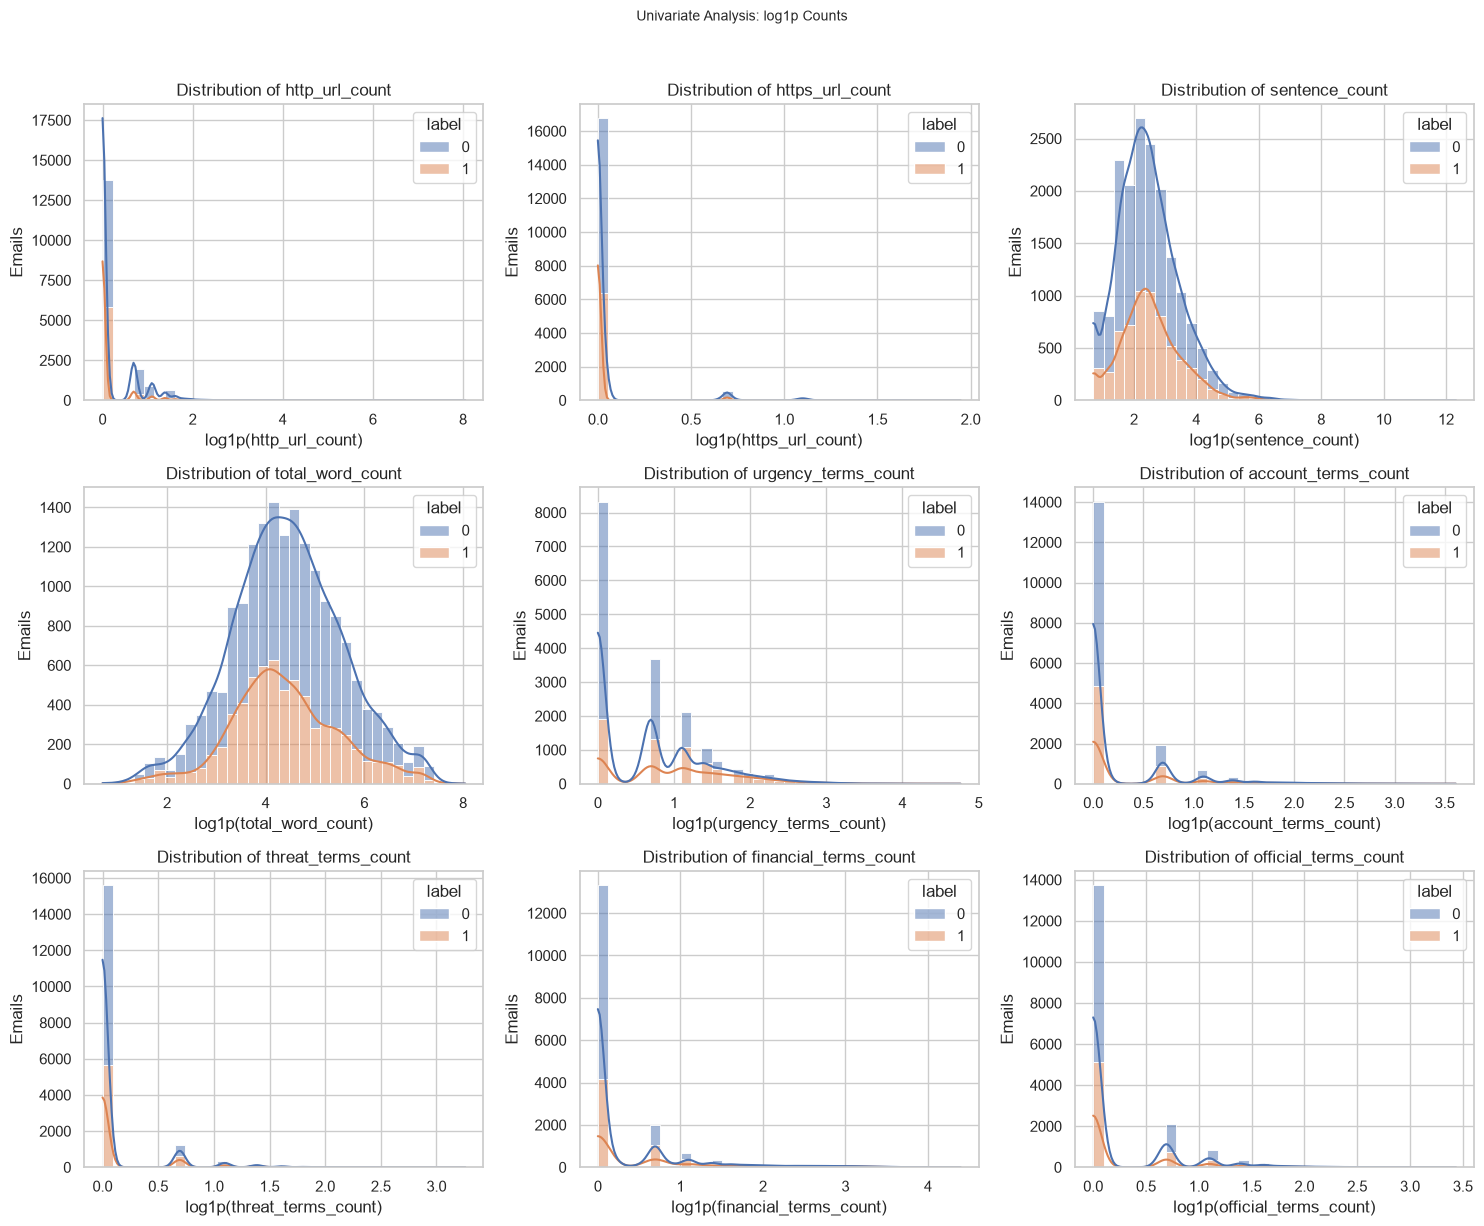

Performing Bivariate Analysis...


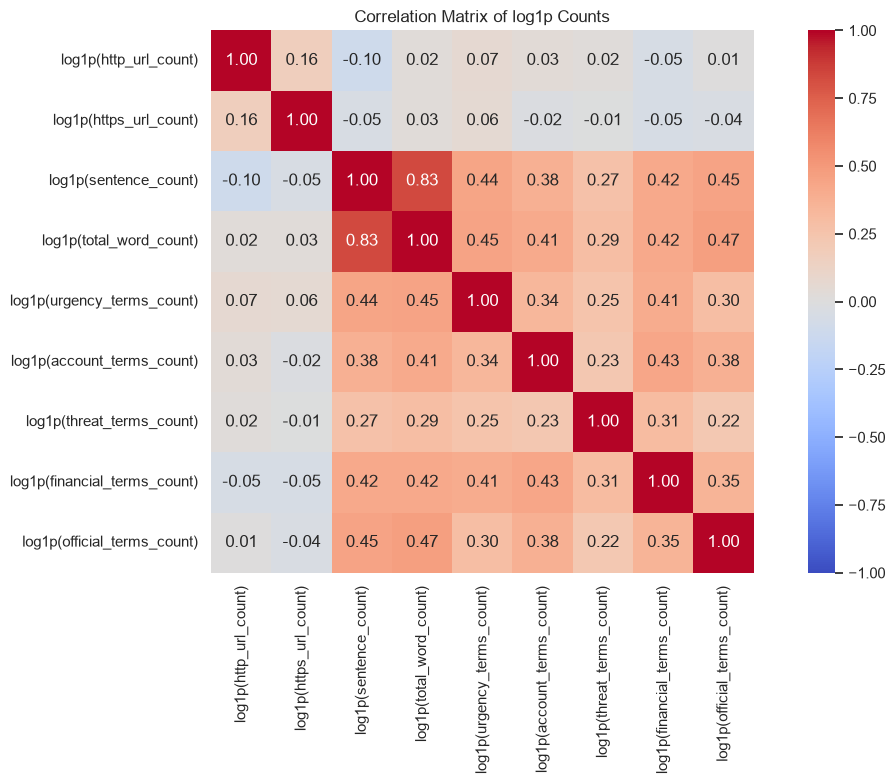

Pairplot sample: 1,000 corpus rows, balanced by class.


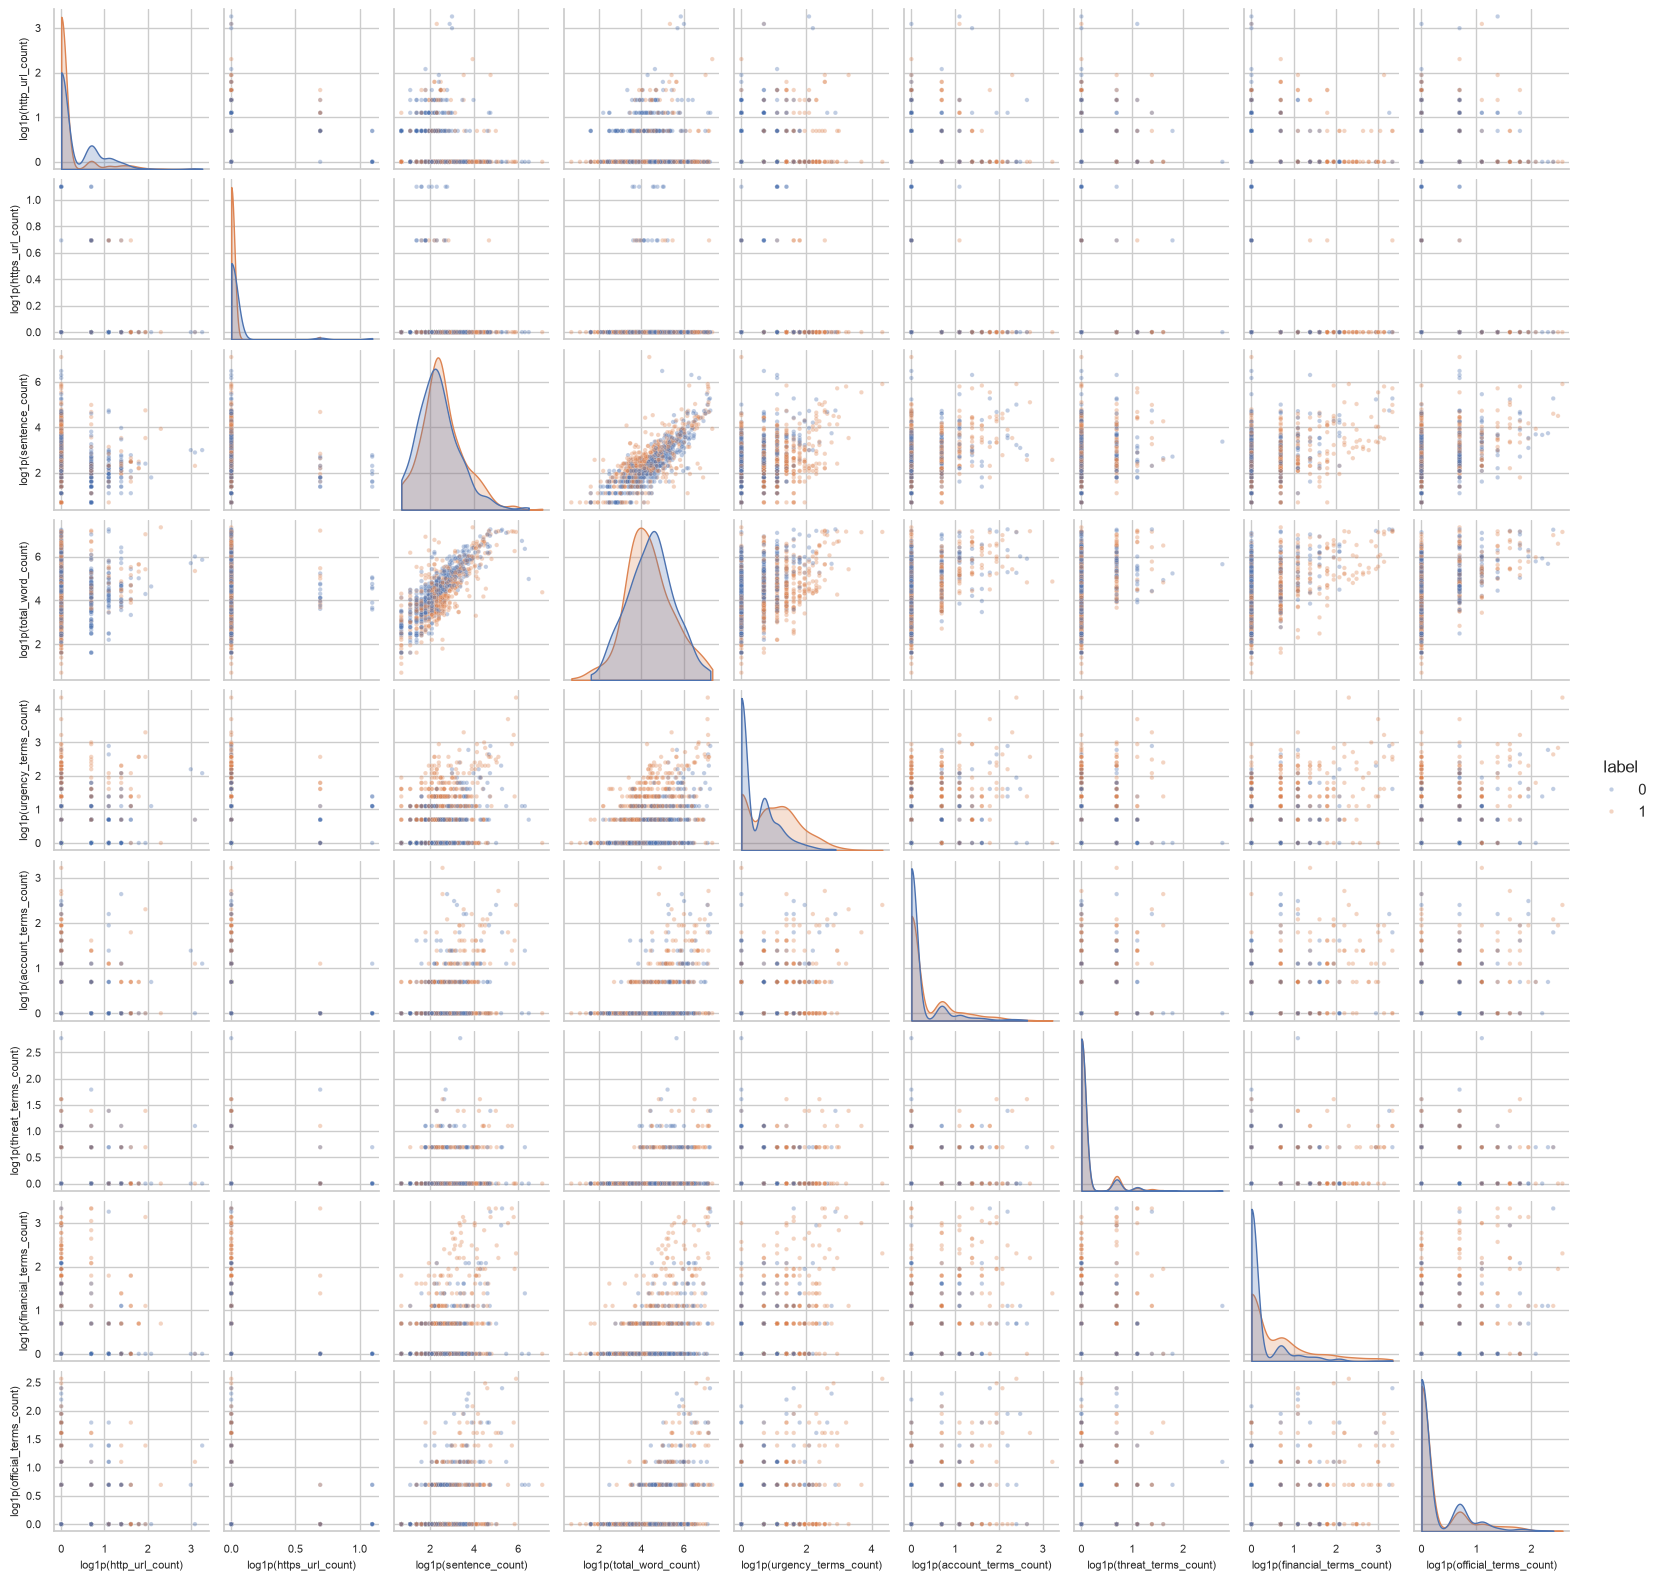

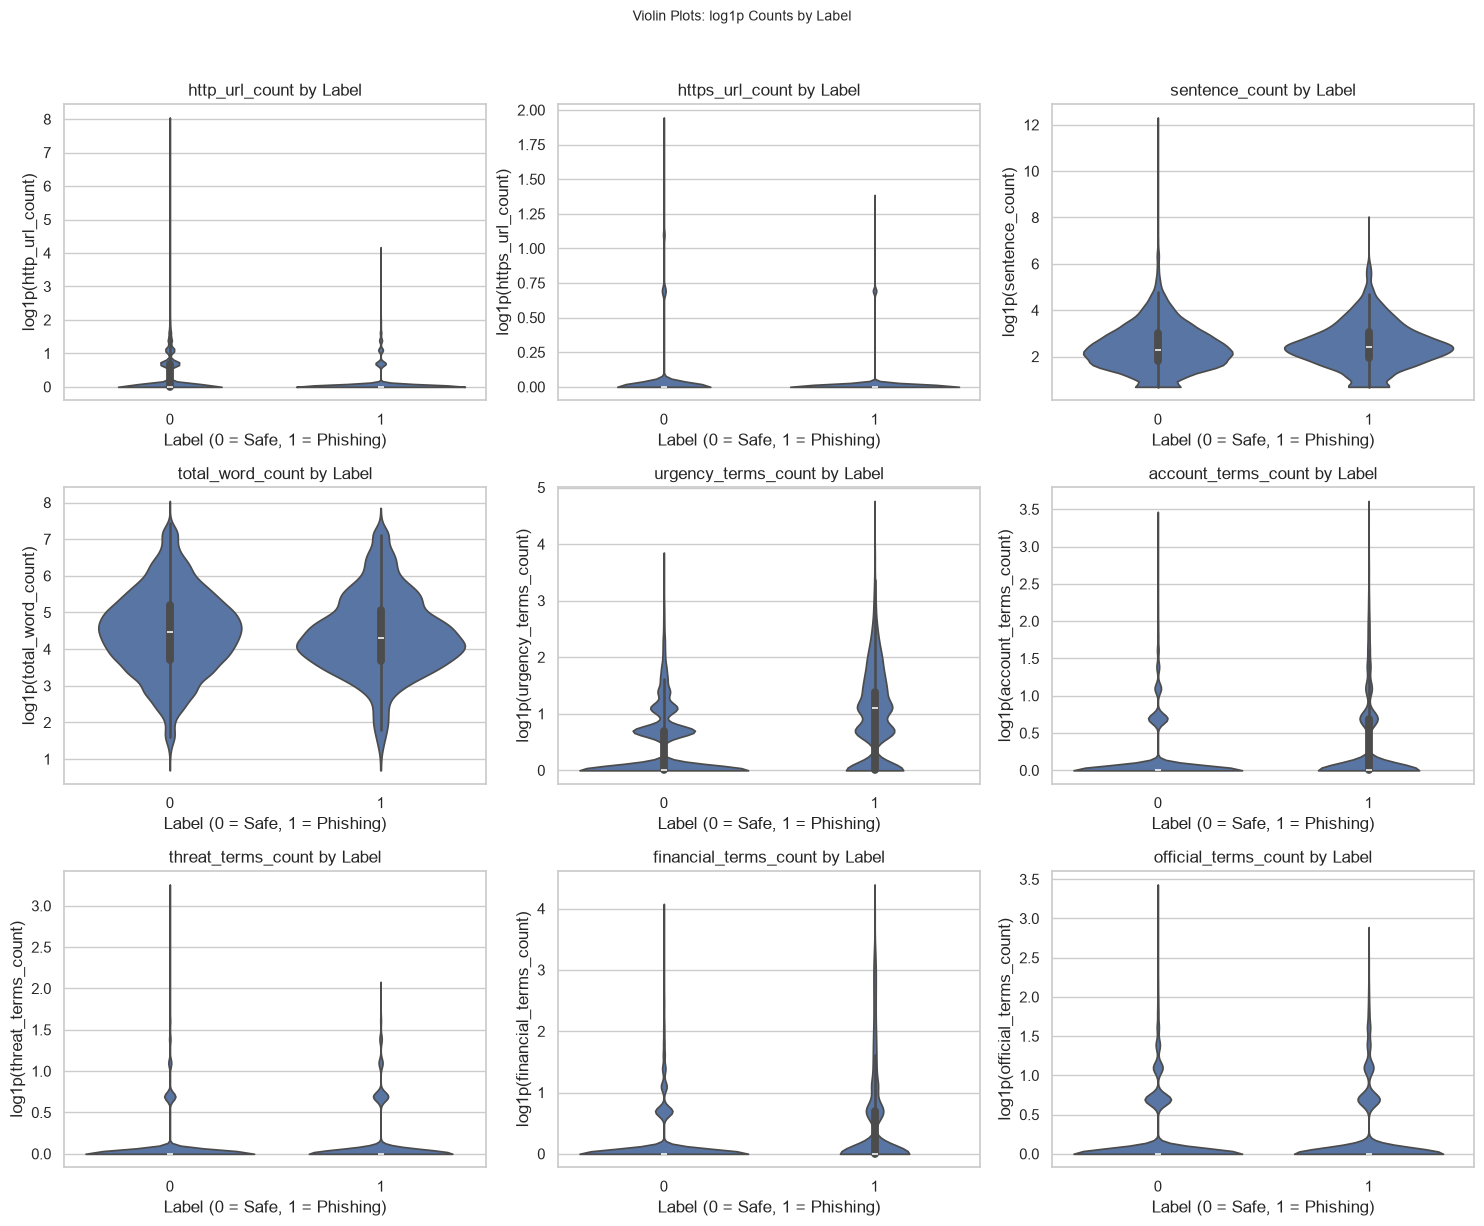

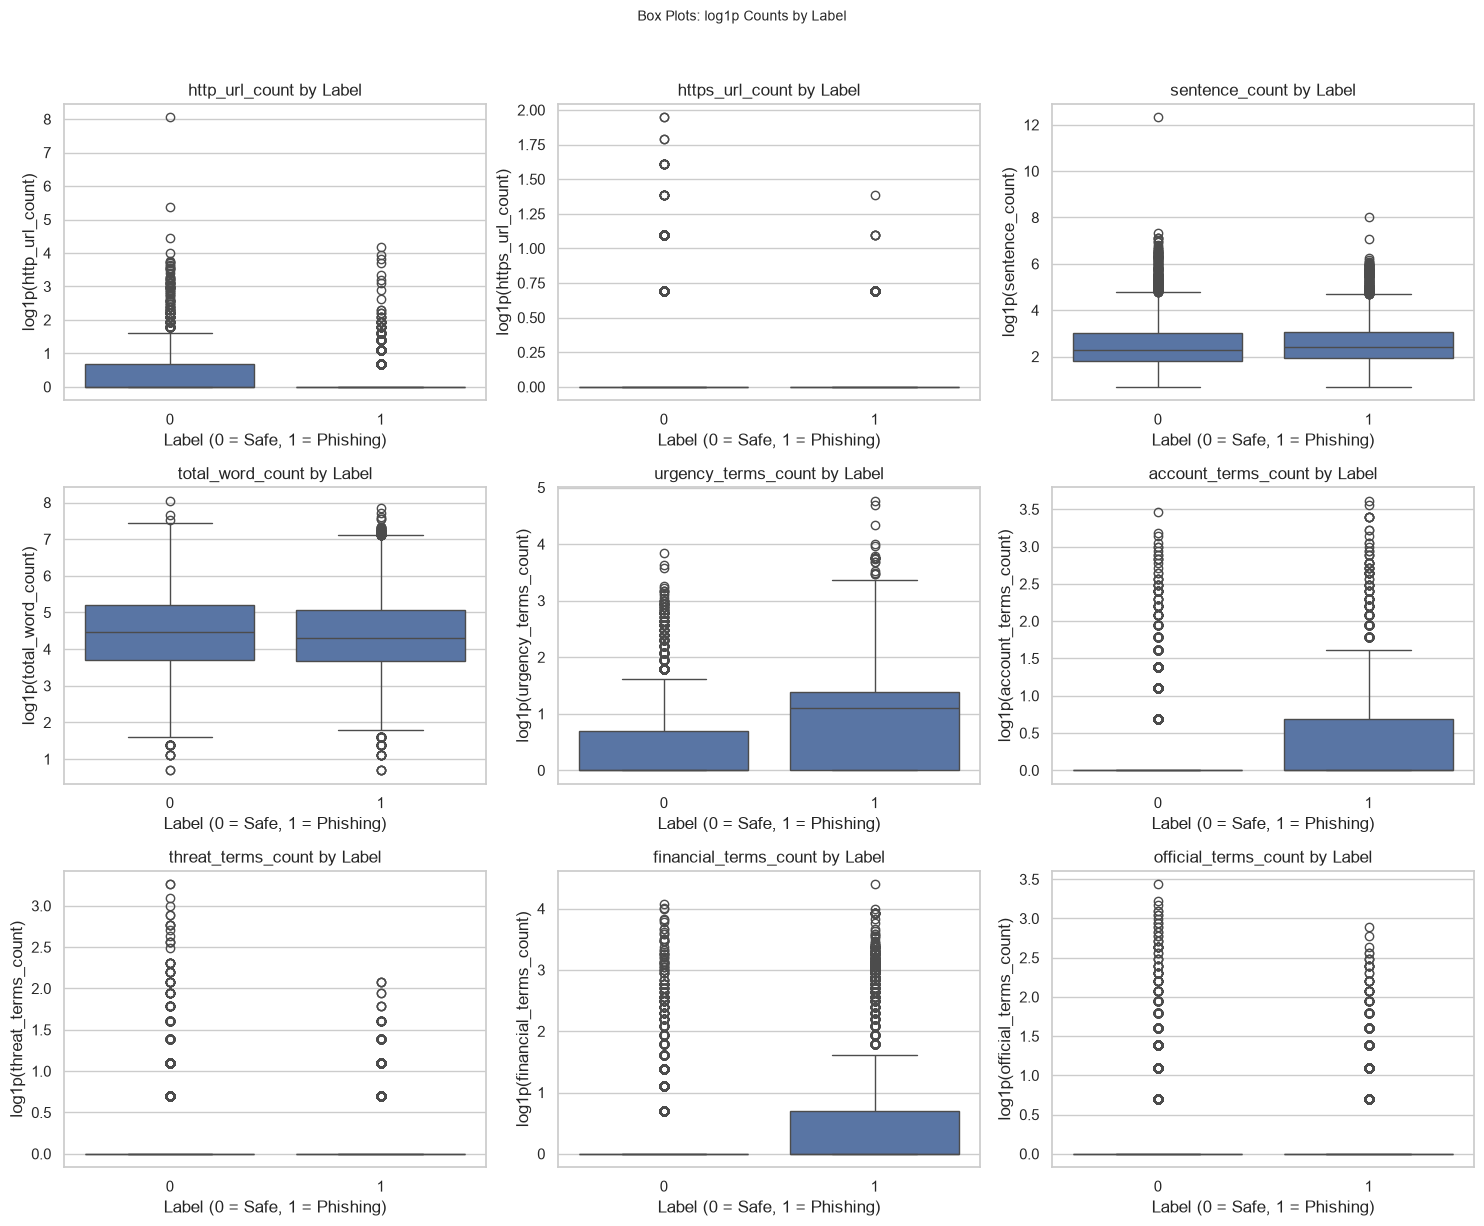

Performing KDE Analysis...


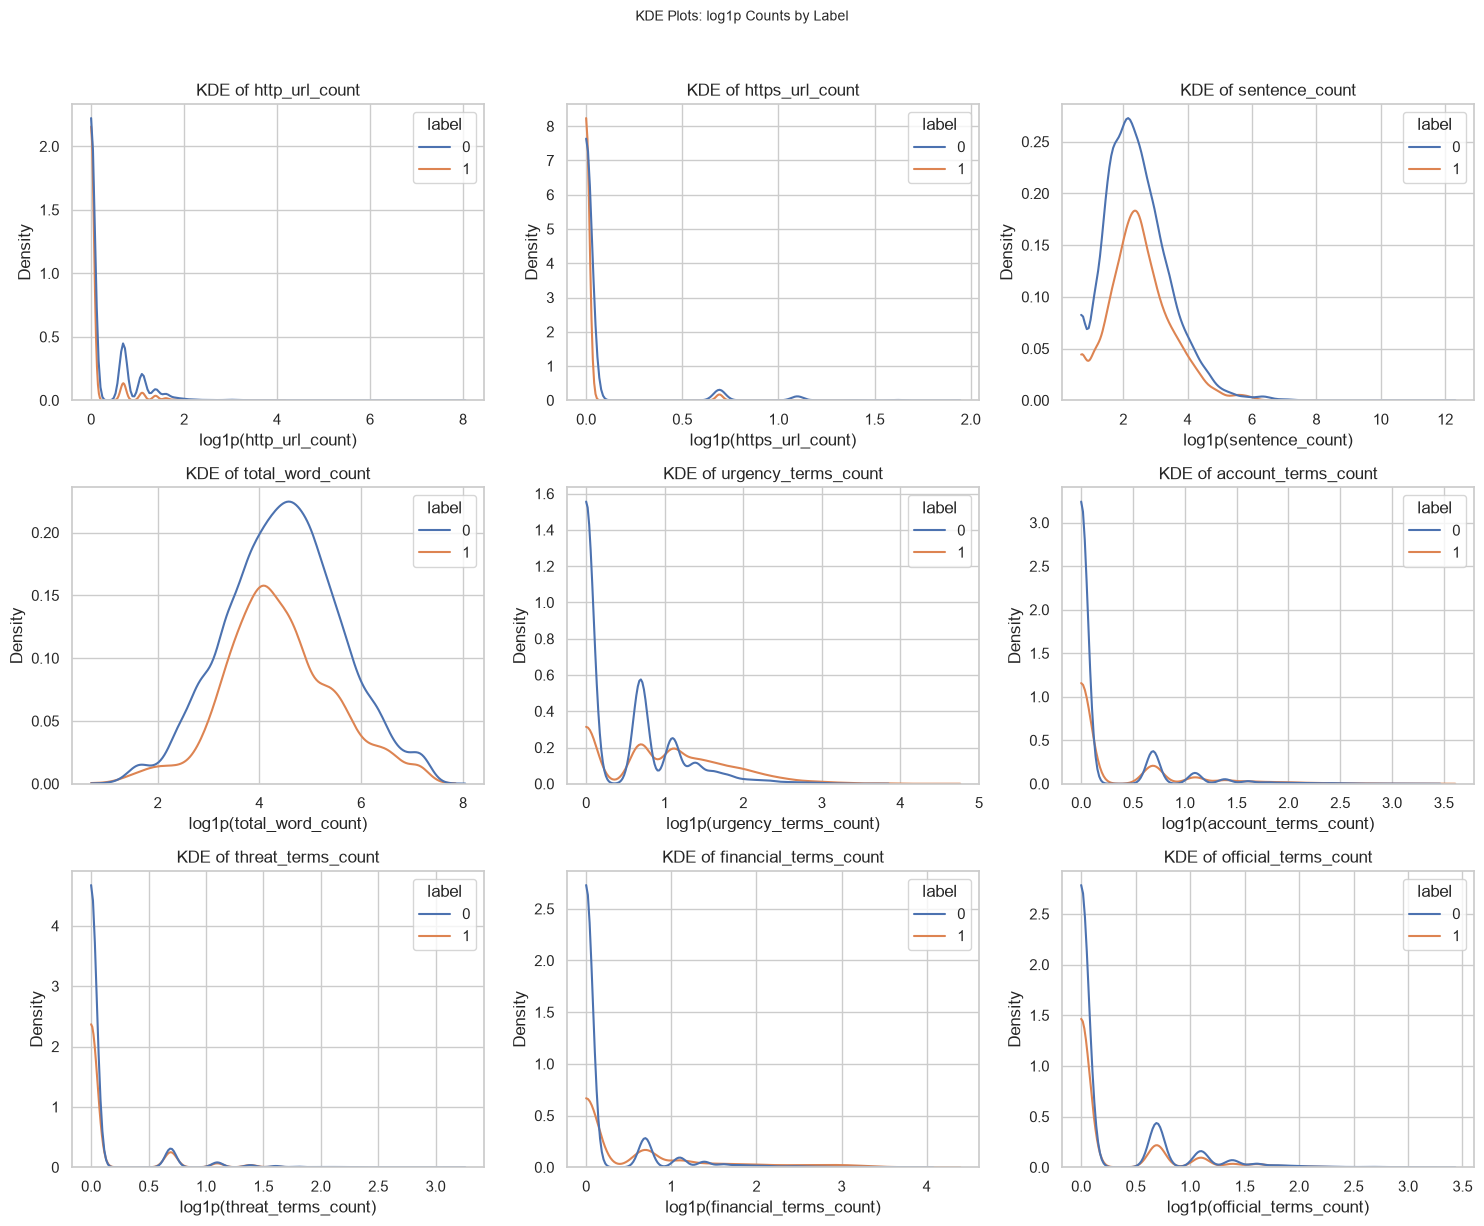

In [209]:
# Pass the full transformed corpus; each helper selects the nine counts and label.
analyze_phishing_email_Univariate_data(corpus_eda)
analyze_phishing_email_Bivariate_data(corpus_eda, include_kde=True)


### Add TF-IDF features

The nine engineered counts overlap across classes, so we also include TF-IDF
features to represent email wording. These plots alone cannot establish that
count-only classification performs poorly or that TF-IDF improves it. Measuring
that benefit would require a count-only baseline evaluated on the same folds.


In [210]:
# Lets drop the corpus_eda datframe to save memory since we have already performed the analysis and have the results.

del corpus_eda

## 7. Create the augmented feature vector: TF-IDF + nine engineered features

In [211]:
# Create the reusable raw augmented vector and preserve a catalog of its column order.
# Sparse horizontal stacking keeps the 5,000 TF-IDF columns from becoming a dense matrix.

assert EFFECTIVE_STOP_WORDS <= set(stopwords.words('english'))
assert EFFECTIVE_STOP_WORDS.isdisjoint(PROTECTED_FEATURE_WORDS)
assert tfidf_vectorizer.get_params()['stop_words'] == sorted(EFFECTIVE_STOP_WORDS)
assert EFFECTIVE_STOP_WORDS.isdisjoint(tfidf_vocabulary_words)

# Append the nine original count features in the declared order; keep everything sparse.
X_train_counts = sparse.csr_matrix(train_df[COUNT_FEATURE_COLUMNS].to_numpy(dtype=np.float32))
X_test_counts = sparse.csr_matrix(test_df[COUNT_FEATURE_COLUMNS].to_numpy(dtype=np.float32))
count_feature_names = np.array(['count__' + name for name in COUNT_FEATURE_COLUMNS])

X_train_augmented = sparse.hstack([X_train_tfidf, X_train_counts], format='csr', dtype=np.float32)
X_test_augmented = sparse.hstack([X_test_tfidf, X_test_counts], format='csr', dtype=np.float32)
X_holdout_augmented = X_test_augmented
augmented_feature_names = np.concatenate([tfidf_feature_names, count_feature_names])
augmented_feature_catalog = pd.DataFrame({
    'column_index': np.arange(len(augmented_feature_names)),
    'feature_name': augmented_feature_names,
    'feature_type': ['TF-IDF'] * len(tfidf_terms) + ['Count'] * len(COUNT_FEATURE_COLUMNS),
})
# Aliases used by exports and modeling.
X_train, X_test = X_train_augmented, X_test_augmented
X_holdout = X_holdout_augmented
feature_names = augmented_feature_names
feature_catalog = augmented_feature_catalog

# Verify the vector size, feature order, and row alignment before modeling.
assert len(COUNT_FEATURE_COLUMNS) == 9
assert X_train_augmented.shape == (len(y_train), len(augmented_feature_names))
assert X_test_augmented.shape == (len(y_test), len(augmented_feature_names))
assert len(augmented_feature_names) == X_train_tfidf.shape[1] + 9
assert list(augmented_feature_names[-9:]) == list(count_feature_names)
assert len(set(augmented_feature_names)) == len(augmented_feature_names)
for matrix in (X_train_augmented, X_test_augmented):
    assert sparse.isspmatrix_csr(matrix)
    assert matrix.dtype == np.float32
    assert np.isfinite(matrix.data).all()

augmentation_summary = pd.DataFrame({
    'rows': [X_train_augmented.shape[0], X_test_augmented.shape[0]],
    'TF-IDF features': [X_train_tfidf.shape[1], X_test_tfidf.shape[1]],
    'additional count features': [len(COUNT_FEATURE_COLUMNS)] * 2,
    'augmented features': [X_train_augmented.shape[1], X_test_augmented.shape[1]],
}, index=['Training', 'Holdout / test'])
print(f'TF-IDF uses {len(EFFECTIVE_STOP_WORDS)} effective NLTK stopwords; feature-word overlap: 0.')
display(augmentation_summary)
print('The nine appended features and their positions in the new vector:')
display(augmented_feature_catalog.tail(9))


TF-IDF uses 172 effective NLTK stopwords; feature-word overlap: 0.


,rows,TF-IDF features,additional count features,augmented features
Training,14109,5000,9,5009
Holdout / test,3402,5000,9,5009


The nine appended features and their positions in the new vector:


,column_index,feature_name,feature_type
5000,5000,count__http_url_count,Count
5001,5001,count__https_url_count,Count
5002,5002,count__sentence_count,Count
5003,5003,count__total_word_count,Count
5004,5004,count__urgency_terms_count,Count
5005,5005,count__account_terms_count,Count
5006,5006,count__threat_terms_count,Count
5007,5007,count__financial_terms_count,Count
5008,5008,count__official_terms_count,Count


## 8. Data ready for the next step

| Variable | Contents |
|---|---|
| `X_train_tfidf`, `X_test_tfidf` | Sparse TF-IDF features only |
| `X_train_counts`, `X_test_counts` | The original nine numeric count features |
| `X_train_augmented`, `X_test_augmented` | New sparse vectors: TF-IDF followed by nine raw count features |
| `X_train`, `X_test`, `X_holdout` | Compatible aliases for the augmented matrices |
| `augmented_feature_names`, `augmented_feature_catalog` | Ordered names and positions in the new vector |
| `y_train`, `y_test` | Aligned labels; Safe = 0, Phishing = 1 |
| `tfidf_terms`, `feature_names`, `feature_catalog` | Column names in matrix order |
| `tfidf_train_df`, `tfidf_test_df` | Named sparse TF-IDF DataFrames |
| `tfidf_vectorizer` | Fitted training vocabulary and IDF weights |
| `train_df`, `test_df` | Text, count features, labels, and source-row metadata |
| `groups_train`, `groups_test`, `cv_splits` | Group IDs and three training CV splits |
| `corpus_eda` | Full corpus copy with nine log1p-transformed count columns and the original label/text/metadata |
| `count_feature_summary`, `count_class_comparison` | Full-corpus summaries of the nine log1p count features |

`X_holdout` and `y_holdout` are aliases for the test partition. Row position `i`
in each matrix matches position `i` in its labels and source DataFrame.

The prepared matrices can be used for training and final holdout evaluation.
For cross-validation or tuning, use `cv_splits` with a pipeline that fits
a new TF-IDF vectorizer inside each fold using `train_df[TEXT_COLUMN]`. Using the
already fitted TF-IDF matrix for CV would expose validation-fold vocabulary and
IDF statistics. Keep the holdout separate during feature and model choices.
Reference: [scikit-learn guidance on preventing data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

The shared classification methods below implement this pipeline using `train_df` as
input. TF-IDF is followed by the same nine raw count features; count scaling is
not needed for tree split thresholds. The pipeline clones the TF-IDF settings
and refits preprocessing without changing the prepared matrices or vectorizer.


In [212]:
# Final shape, alignment, and numeric checks. No classifier is trained here.
assert X_train.shape == (len(y_train), len(feature_names))
assert X_test.shape == (len(y_test), len(feature_names))
assert len(tfidf_terms) == X_train_tfidf.shape[1] == X_test_tfidf.shape[1]
assert len(np.unique(feature_names)) == len(feature_names)
assert X_train.shape[1] == X_train_tfidf.shape[1] + len(COUNT_FEATURE_COLUMNS)
for matrix in (X_train_tfidf, X_test_tfidf, X_train_counts, X_test_counts, X_train, X_test):
    assert sparse.isspmatrix_csr(matrix)
    assert matrix.dtype == np.float32
    assert np.isfinite(matrix.data).all()
    assert (matrix.data >= 0).all()
assert np.array_equal(y_train, train_df[TARGET_COLUMN].to_numpy())
assert np.array_equal(y_test, test_df[TARGET_COLUMN].to_numpy())

ready_summary = pd.DataFrame([
    {'feature_set': 'TF-IDF only', 'training_rows': X_train_tfidf.shape[0],
     'holdout_rows': X_test_tfidf.shape[0], 'features': X_train_tfidf.shape[1]},
    {'feature_set': 'Nine count features', 'training_rows': X_train_counts.shape[0],
     'holdout_rows': X_test_counts.shape[0], 'features': X_train_counts.shape[1]},
    {'feature_set': 'TF-IDF + counts (X_train / X_test)', 'training_rows': X_train.shape[0],
     'holdout_rows': X_test.shape[0], 'features': X_train.shape[1]},
])
display(ready_summary)
print('Data preparation and analysis complete. The matrices and labels are ready.')


,feature_set,training_rows,holdout_rows,features
0,TF-IDF only,14109,3402,5000
1,Nine count features,14109,3402,9
2,TF-IDF + counts (X_train / X_test),14109,3402,5009


Data preparation and analysis complete. The matrices and labels are ready.


## 9. Shared preparation, tuning, and evaluation methods

These helpers are defined here and called later with `train_df`, grouped `cv_splits`, and holdout `test_df`.

1. **Prepare features — `make_tree_features()`:** Define the transformer combining TF-IDF and nine raw counts for each classifier.
2. **Validate inputs — `validate_tuning_inputs()`:** Check labels, predictor columns, CV indices, and group separation before tuning.
3. **Tune — `tune_classifier()`:** Fit TF-IDF within each training fold, select the best mean phishing F1, and refit the pipeline on all training rows.
4. **Report CV — `build_model_results()`:** Summarize each parameter combination's mean scores and fit time.
5. **Evaluate and summarize:** `evaluate_classifier()` scores `test_df` without fitting; `build_holdout_record()` combines its results with CV scores, timings, and tree details.
6. **Plot — `plot_classifier_evaluation()`:** Optionally display confusion matrix, ROC, and precision-recall charts.

Models receive augmented features with original counts; `log1p` remains for EDA only.


In [213]:
# These will be need for classification and comparing perfromance of different models and hyperparameter tuning.
import json
import time
from tempfile import TemporaryDirectory

import joblib
from joblib import Memory, parallel_config
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.model_selection import GridSearchCV, ParameterGrid
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, root_mean_squared_error, roc_auc_score, average_precision_score,
    classification_report, confusion_matrix, make_scorer,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
)


In [214]:
def make_tree_features(vectorizer, *, text_column="word_text", count_columns=None):
    """Build an unfitted transformer combining fresh TF-IDF with optional raw counts.
    
    Args:
        vectorizer (TfidfVectorizer): Settings template; learned vocabulary and IDF are discarded.
        text_column (str): Prepared DataFrame column containing text.
        count_columns (sequence[str] | None): Unique numeric columns; None uses TF-IDF only.
    
    Returns:
        ColumnTransformer: TF-IDF followed by counts; other columns are dropped; output is sparse for this dataset.
    
    Raises:
        TypeError or ValueError: Count columns are a string, duplicated, or include text_column.
    """
    if isinstance(count_columns, str):
        raise TypeError("count_columns must be a sequence of names, not a string.")
    columns = list(count_columns) if count_columns is not None else []
    if text_column in columns or len(set(columns)) != len(columns):
        raise ValueError("Count columns must be unique and exclude the text column.")

    # Fit fresh vocabulary and IDF within each training fold.
    transformers = [("tfidf", clone(vectorizer), text_column)]
    if columns:
        transformers.append(("counts", "passthrough", columns))
    return ColumnTransformer(transformers, remainder="drop", sparse_threshold=1.0)


In [215]:
def validate_tuning_inputs(pipeline, training_frame, cv_splits, target_column, group_column):
    """Return labels and CV splits after checking predictors, labels, and group separation.

    Splits use positional indices into training_frame; invalid inputs raise ValueError.
    """
    labels = training_frame[target_column].to_numpy()
    groups = training_frame[group_column].to_numpy()
    if pd.isna(labels).any() or set(labels) != {0, 1}:
        raise ValueError("Training labels must contain both Safe=0 and Phishing=1.")
    if pd.isna(groups).any():
        raise ValueError("Training group IDs cannot be missing.")

    # Exclude labels and metadata from predictors.
    feature_transformer = pipeline.named_steps["features"]
    forbidden_columns = {target_column, group_column, "input_row", "content_hash", "copies"}
    for _, _, columns in feature_transformer.transformers:
        selected = [columns] if isinstance(columns, str) else list(columns)
        if forbidden_columns.intersection(selected):
            raise ValueError("The feature pipeline includes a label or metadata column.")

    splits = list(cv_splits)
    if len(splits) < 2:
        raise ValueError("Provide at least two grouped cross-validation splits.")
    # Require valid positions, both classes, and separate rows/groups in each fold.
    for fold, (fit_idx, valid_idx) in enumerate(splits, start=1):
        fit_idx, valid_idx = np.asarray(fit_idx), np.asarray(valid_idx)
        for indices in (fit_idx, valid_idx):
            if (indices.ndim != 1 or indices.dtype.kind not in "iu" or len(indices) == 0
                    or np.any(indices < 0) or np.any(indices >= len(training_frame))
                    or len(np.unique(indices)) != len(indices)):
                raise ValueError(f"Fold {fold} has invalid row indices for training_frame.")
            if set(labels[indices]) != {0, 1}:
                raise ValueError(f"Fold {fold} needs both classes in fit and validation rows.")
        if set(fit_idx).intersection(valid_idx):
            raise ValueError(f"Fold {fold} shares rows between fit and validation.")
        if set(groups[fit_idx]).intersection(groups[valid_idx]):
            raise ValueError(f"Fold {fold} shares email groups between fit and validation.")
    return labels, splits


In [216]:
def tune_classifier(
    pipeline, training_frame, cv_splits, param_grid, *,
    target_column="label", group_column="group_id", n_jobs=1, verbose=0,
    return_train_score=False,
):
    """Tune grouped CV and refit the pipeline with the best mean phishing F1.

    Use prepared training rows, positional CV splits, and pipeline-prefixed parameters.
    Options set label/group columns, parallel jobs, verbosity, and training-score reporting.
    Returns fitted GridSearchCV with CV scores/timings and elapsed_seconds_.
    TF-IDF fits within each fold; RMSE scores are negative; invalid inputs raise ValueError.
    """
    labels, splits = validate_tuning_inputs(
        pipeline, training_frame, cv_splits, target_column, group_column,
    )

    # Record all metrics; select the best candidate by mean validation F1.
    scoring = {
        "f1": make_scorer(f1_score, pos_label=1, zero_division=0),
        "precision": make_scorer(precision_score, pos_label=1, zero_division=0),
        "recall": make_scorer(recall_score, pos_label=1, zero_division=0),
        "roc_auc": make_scorer(roc_auc_score, response_method="predict_proba"),
        "average_precision": make_scorer(average_precision_score, response_method="predict_proba"),
        "balanced_accuracy": "balanced_accuracy",
        "rmse": "neg_root_mean_squared_error",  # RMSE of predicted 0/1 labels.
    }
    search = GridSearchCV(
        estimator=clone(pipeline), param_grid=param_grid, scoring=scoring,
        refit="f1", cv=splits, n_jobs=n_jobs, return_train_score=return_train_score,
        error_score="raise", verbose=verbose,
    )
    start = time.perf_counter()
    search.fit(training_frame, labels)
    search.elapsed_seconds_ = time.perf_counter() - start
    return search


In [217]:
def plot_classifier_evaluation(labels, scores, matrix, name):
    """Display confusion matrix, ROC, and precision-recall charts without fitting.

    scores are Phishing=1 probabilities; matrix is ordered [[TN, FP], [FN, TP]].
    """
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    ConfusionMatrixDisplay(matrix, display_labels=["Safe", "Phishing"]).plot(
        ax=axes[0], cmap="Blues", colorbar=False,
    )
    RocCurveDisplay.from_predictions(labels, scores, name=name, ax=axes[1])
    PrecisionRecallDisplay.from_predictions(labels, scores, name=name, ax=axes[2])
    axes[0].set_title(f"{name}: confusion matrix")
    axes[1].set_title("ROC using phishing probabilities")
    axes[2].set_title("Precision-recall using phishing probabilities")
    plt.tight_layout()
    plt.show()


In [218]:
def evaluate_classifier(
    fitted_model, evaluation_frame, *, target_column="label", name="Classifier", plot=True,
):
    """Evaluate a fitted pipeline/search on prepared rows with Safe=0 and Phishing=1.

    target_column supplies labels; name labels results; plot enables three evaluation charts.
    Return a dict of metrics, classification_report, confusion_matrix, predictions, and probability_scores.
    RMSE uses predicted labels; ROC-AUC/AP use phishing probabilities. No fitting occurs.
    Raise ValueError if evaluation labels or model classes do not contain exactly 0 and 1.
    """
    labels = evaluation_frame[target_column].to_numpy()
    if pd.isna(labels).any() or set(labels) != {0, 1}:
        raise ValueError("Evaluation requires both Safe=0 and Phishing=1 for ROC-AUC.")
    if not np.array_equal(fitted_model.classes_, np.array([0, 1])):
        raise ValueError("The fitted model must use Safe=0 and Phishing=1.")

    predictions = fitted_model.predict(evaluation_frame)
    scores = fitted_model.predict_proba(evaluation_frame)[:, 1]
    metrics = {
        "model": name, "rows": len(labels),
        "accuracy": accuracy_score(labels, predictions),
        "rmse": root_mean_squared_error(labels, predictions),
        "error_rate": np.mean(labels != predictions),
        "balanced_accuracy": balanced_accuracy_score(labels, predictions),
        "precision": precision_score(labels, predictions, zero_division=0),
        "recall": recall_score(labels, predictions, zero_division=0),
        "f1": f1_score(labels, predictions, zero_division=0),
        "roc_auc": roc_auc_score(labels, scores),
        "average_precision": average_precision_score(labels, scores),
    }
    report = pd.DataFrame(classification_report(
        labels, predictions, labels=[0, 1], target_names=["Safe", "Phishing"],
        output_dict=True, zero_division=0,
    )).T
    matrix = confusion_matrix(labels, predictions, labels=[0, 1])
    if plot:
        plot_classifier_evaluation(labels, scores, matrix, name)
    return {
        "metrics": metrics, "classification_report": report,
        "confusion_matrix": matrix, "predictions": predictions, "probability_scores": scores,
    }


In [219]:
def build_model_results(search, model_name="Classifier"):
    """Return an unrounded, eight-column CV summary with one row per parameter combination.
    
    Args:
        search (GridSearchCV): Fitted output of tune_classifier with its named CV metrics.
        model_name (str): Model label repeated on each row.
    
    Returns:
        pd.DataFrame: Parameters without model__ prefixes, mean CV scores, positive label RMSE, and mean fold-fit seconds.
    """
    cv = pd.DataFrame(search.cv_results_)
    return pd.DataFrame({
        'model': model_name,
        'hyper param': [{key.removeprefix('model__'): value for key, value in parameters.items()}
                        for parameters in cv['params']],
        'CV_rmse': -cv['mean_test_rmse'],
        'CV_ROC_AUC': cv['mean_test_roc_auc'],
        'CV Avg Precision': cv['mean_test_precision'],
        'CV_Avg_recall': cv['mean_test_recall'],
        'CV_Avg_F1score': cv['mean_test_f1'],
        'CV Fit time': cv['mean_fit_time'],
    })


In [220]:
def build_holdout_record(
    name, search, estimator, result, *, evaluation_seconds,
    training_rows, test_rows, selected_model_name,
):
    """Validate one evaluation and return its CV/holdout metrics, timings, and tree details.

    Reuse fitted search results and predictions; no fitting or prediction occurs here.
    """
    metrics = result['metrics']
    tn, fp, fn, tp = result['confusion_matrix'].ravel()
    assert tn + fp + fn + tp == test_rows
    np.testing.assert_allclose(metrics['rmse'] ** 2, 1 - metrics['accuracy'])
    assert np.isfinite(result['probability_scores']).all()

    trees = [estimator] if isinstance(estimator, DecisionTreeClassifier) else estimator.estimators_
    best, scores = search.best_index_, search.cv_results_
    return {
        'model': name, 'hyper param': search.best_params_,
        'CV_RMSE': -scores['mean_test_rmse'][best], 'CV_F1': search.best_score_,
        'CV_ROC_AUC': scores['mean_test_roc_auc'][best],
        'CV_Precision': scores['mean_test_precision'][best],
        'CV_Recall': scores['mean_test_recall'][best],
        'CV_F1_Std': scores['std_test_f1'][best],
        'CV_Mean_Fit_Time_Seconds': scores['mean_fit_time'][best],
        'Test_RMSE': metrics['rmse'], 'Accuracy': metrics['accuracy'],
        'Balanced_Accuracy': metrics['balanced_accuracy'],
        'Precision': metrics['precision'], 'Recall': metrics['recall'], 'F1': metrics['f1'],
        'ROC_AUC': metrics['roc_auc'], 'Average_precision': metrics['average_precision'],
        'Test_Error_Rate': metrics['error_rate'], 'Fit_Time_Seconds': search.refit_time_,
        'Search_Time_Seconds': search.elapsed_seconds_, 'Evaluation_Time_Seconds': evaluation_seconds,
        'True_Negatives': int(tn), 'False_Positives': int(fp),
        'False_Negatives': int(fn), 'True_Positives': int(tp),
        'Fitted_Trees': len(trees),
        'Max_Component_Depth': max(tree.get_depth() for tree in trees),
        'Total_Leaves': sum(tree.get_n_leaves() for tree in trees),
        'Features': estimator.n_features_in_, 'Training_Rows': training_rows, 'Test_Rows': test_rows,
        'Selected_Overall_By_CV': name == selected_model_name,
    }


## 10. Decision-tree classification

The pipeline combines TF-IDF and selected raw counts before fitting a decision tree.
The quick grid tests **max_depth = 5, 10, 20, None** (four configurations).
The expanded grid also tests **min_samples_leaf = 1, 5, 10** (12 configurations).
`None` leaves depth unrestricted; compare training and validation F1 for overfitting.

In this section we define a decision-tree pipeline using TF-IDF plus nine raw count features. It prepares four tree-depth configurations for the quick search, or 12 depth-and-leaf-size combinations for the expanded search. Tuning runs later using grouped cross-validation; training and validation F1 help identify overfitting.


In [221]:
def create_decision_tree(
    vectorizer, *, text_column="word_text", count_columns=None,
    criterion="gini", max_depth=None, min_samples_split=2, min_samples_leaf=1,
    max_features=None, class_weight=None, ccp_alpha=0.0, random_state=42,
):
    """Build an unfitted TF-IDF + optional raw counts -> decision-tree pipeline.
    
    Args:
        vectorizer (TfidfVectorizer): Settings template cloned for preprocessing within each fold.
        text_column (str): Prepared input text column.
        count_columns (sequence[str] | None): Counts appended after TF-IDF; None uses text only.
        criterion (str): Split impurity measure: gini, entropy, or log_loss.
        max_depth (int | None): Tree depth limit; None leaves depth unrestricted.
        min_samples_split (int | float): Minimum row count or fraction required to split a node.
        min_samples_leaf (int | float): Minimum row count or fraction required in a leaf.
        max_features (int | float | str | None): Features considered per split; None uses all.
        class_weight (dict | str | None): Class weights, 'balanced', or no weighting.
        ccp_alpha (float): Non-negative pruning strength; larger values prune more.
        random_state (int): Seed for reproducible tree fitting.
    
    Returns:
        Pipeline: Unfitted features -> model; fitted predict gives (n_rows,) labels and predict_proba gives (n_rows, 2) scores in classes_ order.
    """
    return Pipeline([
        ("features", make_tree_features(
            vectorizer, text_column=text_column, count_columns=count_columns,
        )),
        ("model", DecisionTreeClassifier(
            criterion=criterion, max_depth=max_depth,
            min_samples_split=min_samples_split, min_samples_leaf=min_samples_leaf,
            max_features=max_features, class_weight=class_weight,
            ccp_alpha=ccp_alpha, random_state=random_state,
        )),
    ])


In [222]:
# Four configurations in quick mode; 12 when depth and leaf size are varied together.
decision_tree_quick_grid = {
    'model__max_depth': [5, 10, 20, None],
}
decision_tree_expanded_grid = {
    'model__max_depth': [5, 10, 20, None],
    'model__min_samples_leaf': [1, 5, 10],
}


## 11. Random forest with bootstrap bagging

The pipeline fits trees on bootstrap samples (`bootstrap=True`) and averages their
class probabilities. `max_features='sqrt'` selects feature subsets at each split;
`max_samples=None` gives each bootstrap sample the training set's row count.

The quick grid tests **50, 100, 200, 300 trees**. The expanded grid tests
**100, 200, 300 trees × depth 20/None × leaf size 1/5** (12 configurations).
Keep forest `n_jobs=1` because GridSearchCV parallelizes the outer search.


In [223]:
def create_random_forest(
    vectorizer, *, text_column="word_text", count_columns=None, n_estimators=100,
    max_depth=None, min_samples_split=2, min_samples_leaf=1, max_features="sqrt",
    max_samples=None, class_weight=None, criterion="gini", random_state=42, n_jobs=1,
):
    """Build an unfitted TF-IDF + optional raw counts -> bootstrap random-forest pipeline.
    
    Args:
        vectorizer (TfidfVectorizer): Settings template cloned for preprocessing within each fold.
        text_column (str): Prepared input text column.
        count_columns (sequence[str] | None): Counts appended after TF-IDF; None uses text only.
        n_estimators (int): Number of bootstrap-trained trees.
        max_depth (int | None): Per-tree depth limit; None leaves depth unrestricted.
        min_samples_split (int | float): Minimum row count or fraction required to split a node.
        min_samples_leaf (int | float): Minimum row count or fraction required in a leaf.
        max_features (int | float | str | None): Features considered per split; 'sqrt' uses the square root of the total.
        max_samples (int | float | None): Bootstrap sample count or fraction; None uses the training-row count.
        class_weight (dict | str | None): Class weights, 'balanced', 'balanced_subsample', or no weighting.
        criterion (str): Split impurity measure: gini, entropy, or log_loss.
        random_state (int): Seed for bootstrap sampling and tree fitting.
        n_jobs (int): Forest workers; keep 1 when the outer search runs in parallel.
    
    Returns:
        Pipeline: Unfitted features -> model with bootstrap=True; fitted probabilities average across trees in classes_ order.
    """
    return Pipeline([
        ("features", make_tree_features(
            vectorizer, text_column=text_column, count_columns=count_columns,
        )),
        ("model", RandomForestClassifier(
            n_estimators=n_estimators, max_depth=max_depth,
            min_samples_split=min_samples_split, min_samples_leaf=min_samples_leaf,
            max_features=max_features, bootstrap=True, max_samples=max_samples,
            class_weight=class_weight, criterion=criterion,
            random_state=random_state, n_jobs=n_jobs,
        )),
    ])


In [224]:
# bootstrap=True is fixed in the factory; every candidate uses bootstrap bagging.
random_forest_quick_grid = {
    'model__n_estimators': [50, 100, 200, 300],
}
random_forest_expanded_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [20, None],
    'model__min_samples_leaf': [1, 5],
}


## 12. Boosting with AdaBoost

This factory uses discrete **SAMME AdaBoost**. It fits weak decision trees
sequentially, increasing emphasis on misclassified training examples, and combines
their class predictions through a weighted vote. The quick search uses decision
stumps (`max_depth=1`); learning rate scales each learner's contribution.
`n_estimators` is a maximum, and fitting can stop earlier on a perfect fit.

The quick grid tests **25, 50, 100, 200 rounds** at `learning_rate=1.0`.
The expanded grid tests **50/100/200 rounds × learning rate 0.1/1.0 ×
weak-tree depth 1/2**, giving 12 configurations. Nested weak-learner parameters
use names such as `model__estimator__max_depth`.

Reference: [AdaBoostClassifier documentation for the installed scikit-learn 1.5 series](https://scikit-learn.org/1.5/modules/generated/sklearn.ensemble.AdaBoostClassifier.html).


In [225]:
def create_adaboost(
    vectorizer, *, text_column="word_text", count_columns=None, n_estimators=50,
    learning_rate=1.0, weak_max_depth=1, weak_min_samples_leaf=1, random_state=42,
):
    """Build a TF-IDF/count pipeline with AdaBoost over shallow decision trees.

    Parameters
    ----------
    vectorizer : sklearn.feature_extraction.text.TfidfVectorizer
        Settings template; learned vocabulary/IDF are not reused across folds.
    text_column : str, default 'word_text'
        Prepared DataFrame text column.
    count_columns : sequence[str] | None, default None
        Raw count predictors appended after TF-IDF.
    n_estimators : int, default 50
        Maximum boosting rounds; actual fitted learner count can be smaller.
    learning_rate : float, default 1.0
        Positive multiplier for learner contributions; tune jointly with rounds.
    weak_max_depth : int, default 1
        Maximum depth of each weak decision tree (1 means decision stump).
    weak_min_samples_leaf : int, default 1
        Minimum rows in each weak tree leaf.
    random_state : int, default 42
        Seed forwarded to the weak learner and boosting ensemble.

    Returns
    -------
    sklearn.pipeline.Pipeline
        Unfitted features -> model pipeline with AdaBoostClassifier. After fitting,
        predict returns integer labels of shape (n_rows,); predict_proba returns
        (n_rows, 2) estimates ordered by classes_. Estimates are not separately
        calibrated. Nested grid settings can override estimator__max_depth.
    """
    weak_tree = DecisionTreeClassifier(
        max_depth=weak_max_depth, min_samples_leaf=weak_min_samples_leaf,
        random_state=random_state,
    )
    boosting = AdaBoostClassifier(
        estimator=weak_tree, n_estimators=n_estimators,
        learning_rate=learning_rate, random_state=random_state,
    )
    # The installed sklearn API exposes algorithm; request discrete SAMME explicitly.
    # Also allow versions where SAMME is the only algorithm and the keyword is absent.
    if 'algorithm' in boosting.get_params():
        boosting.set_params(algorithm='SAMME')
    return Pipeline([
        ("features", make_tree_features(
            vectorizer, text_column=text_column, count_columns=count_columns,
        )),
        ("model", boosting),
    ])


In [226]:
# Four round counts in quick mode; expanded mode also varies shrinkage and weak-tree depth.
adaboost_quick_grid = {
    'model__n_estimators': [25, 50, 100, 200],
}
adaboost_expanded_grid = {
    'model__n_estimators': [50, 100, 200],
    'model__learning_rate': [0.1, 1.0],
    'model__estimator__max_depth': [1, 2],
}


## 13. Run the three model searches in order

The default `SEARCH_MODE='quick'` gives **four configurations per family**:
12 candidate rows, **36 CV fits and three full-training refits**. Each quick grid
varies one main control while holding other parameters at defaults.
 `SEARCH_MODE='expanded'` selects 12 configurations per family:
36 candidate rows, **108 CV fits and three refits**. This notebook runs only the
selected mode; the expanded search is an optional follow-up.

Execution order is **Decision Tree, Random Forest (Bagging), AdaBoost**. Each
family uses its own temporary preprocessing cache, preserving a fresh full-training
refit for timing. Up to four CV fits run concurrently; forest internals use one
worker. Training scores are optional and add prediction work, not extra fits.

`model_searches` stores fitted GridSearchCV objects, `model_cv_results_df` stores
all candidate/fold details, and `results_df` stores the single eight-column
candidate report. This section prepares those objects without displaying multiple
performance tables. **Saved outputs show the completed quick run.**

In [227]:
# Shared experiment controls: all families use the same data, feature definitions, and folds.
INCLUDE_COUNTS = True
SEARCH_MODE = 'quick'  # 'quick': 4 per family; 'expanded': 12 per family.
COLLECT_TRAIN_SCORES = True  # Set False to reduce per-fold prediction/scoring work.
SEARCH_JOBS = min(4, joblib.cpu_count())
SAVE_MODEL_ARTIFACTS = True
MODEL_ORDER = ['Decision Tree', 'Random Forest (Bagging)', 'AdaBoost']
MODELS_TO_RUN = MODEL_ORDER.copy()
count_columns_for_models = COUNT_FEATURE_COLUMNS if INCLUDE_COUNTS else None

model_candidates = {
    'Decision Tree': create_decision_tree(
        tfidf_vectorizer, text_column=TEXT_COLUMN, count_columns=count_columns_for_models,
        random_state=RANDOM_STATE,
    ),
    'Random Forest (Bagging)': create_random_forest(
        tfidf_vectorizer, text_column=TEXT_COLUMN, count_columns=count_columns_for_models,
        random_state=RANDOM_STATE, n_jobs=1,
    ),
    'AdaBoost': create_adaboost(
        tfidf_vectorizer, text_column=TEXT_COLUMN, count_columns=count_columns_for_models,
        random_state=RANDOM_STATE,
    ),
}
quick_param_grids = {
    'Decision Tree': decision_tree_quick_grid,
    'Random Forest (Bagging)': random_forest_quick_grid,
    'AdaBoost': adaboost_quick_grid,
}
expanded_param_grids = {
    'Decision Tree': decision_tree_expanded_grid,
    'Random Forest (Bagging)': random_forest_expanded_grid,
    'AdaBoost': adaboost_expanded_grid,
}
if SEARCH_MODE not in {'quick', 'expanded'}:
    raise ValueError("Choose SEARCH_MODE='quick' or 'expanded'.")
if (not MODELS_TO_RUN or len(set(MODELS_TO_RUN)) != len(MODELS_TO_RUN)
        or not set(MODELS_TO_RUN).issubset(MODEL_ORDER)):
    raise ValueError('Select unique model names from MODEL_ORDER.')
param_grids = quick_param_grids if SEARCH_MODE == 'quick' else expanded_param_grids
candidate_counts = {name: len(ParameterGrid(param_grids[name])) for name in MODELS_TO_RUN}
total_candidates = sum(candidate_counts.values())
MODEL_FILE_STEMS = {'Decision Tree': 'decision_tree',
                    'Random Forest (Bagging)': 'random_forest_bagging', 'AdaBoost': 'adaboost'}
RESULTS_DIR = Path(
    f'./artifacts/week6_tree_ensembles/{SEARCH_MODE}_grid_'
    f'{total_candidates}configs_tfidf_{MAX_FEATURES_TFIDF}'
)
for name in MODELS_TO_RUN:
    print(f'{name}: {candidate_counts[name]} configurations')
print(f'Total: {total_candidates} candidates × {len(cv_splits)} folds = '
      f'{total_candidates * len(cv_splits)} CV fits, plus {len(MODELS_TO_RUN)} refits.')


Decision Tree: 4 configurations
Random Forest (Bagging): 4 configurations
AdaBoost: 4 configurations
Total: 12 candidates × 3 folds = 36 CV fits, plus 3 refits.


In [228]:
# Run the configured searches and store their fitted pipelines and CV results.
RUN_MODEL_SEARCHES = True
model_searches = {}
selected_models = {}
model_cv_frames = {}
model_cv_results_df = pd.DataFrame()
results_df = pd.DataFrame()
selected_model_name = None
selected_model = None

if RUN_MODEL_SEARCHES:
    if SAVE_MODEL_ARTIFACTS:
        RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    with TemporaryDirectory(prefix='week6_ensemble_cv_') as cache_directory:
        with parallel_config(backend='loky', inner_max_num_threads=1):
            for model_name in MODELS_TO_RUN:
                stem = MODEL_FILE_STEMS[model_name]
                # Independent family caches make each full-training refit include fresh TF-IDF.
                memory = Memory(Path(cache_directory) / stem, verbose=0)
                candidate = clone(model_candidates[model_name]).set_params(memory=memory)
                print(f'Tuning {model_name} on {len(train_df):,} training rows...', flush=True)
                search = tune_classifier(
                    candidate, train_df, cv_splits, param_grids[model_name],
                    target_column=TARGET_COLUMN, n_jobs=SEARCH_JOBS, verbose=2,
                    return_train_score=COLLECT_TRAIN_SCORES,
                )
                # Fitted transformers are retained; predictions need no temporary fit cache.
                search.best_estimator_.set_params(memory=None)
                search.estimator.set_params(memory=None)
                model_searches[model_name] = search
                selected_models[model_name] = search.best_estimator_
                model_cv_frames[model_name] = pd.DataFrame(search.cv_results_)
                if SAVE_MODEL_ARTIFACTS:
                    joblib.dump(search, RESULTS_DIR / f'{stem}_search.joblib')
                    joblib.dump(search.best_estimator_, RESULTS_DIR / f'{stem}_best_pipeline.joblib')
                    model_cv_frames[model_name].to_csv(RESULTS_DIR / f'{stem}_cv_results.csv', index=False)
                print(f'{model_name} search completed in {search.elapsed_seconds_:.1f} seconds.', flush=True)

    # One row per candidate, all three families combined, with the same eight public columns.
    results_df = pd.concat(
        [build_model_results(model_searches[name], name) for name in MODELS_TO_RUN],
        ignore_index=True,
    )
    model_cv_results_df = pd.concat(
        [frame.assign(model=name) for name, frame in model_cv_frames.items()], ignore_index=True,
    )
    # Freeze overall selection using training CV before any holdout predictions.
    selected_model_name = max(model_searches, key=lambda name: model_searches[name].best_score_)
    selected_model = selected_models[selected_model_name]
    if SAVE_MODEL_ARTIFACTS:
        results_df.to_csv(RESULTS_DIR / 'model_results.csv', index=False)
        model_cv_results_df.to_csv(RESULTS_DIR / 'all_candidate_cv_results.csv', index=False)
        joblib.dump(selected_model, RESULTS_DIR / 'selected_pipeline.joblib')
else:
    print('No models fitted. Set RUN_MODEL_SEARCHES=True and execute this cell when ready.')


Tuning Decision Tree on 14,109 training rows...
Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV] END .................................model__max_depth=5; total time=   4.2s
[CV] END .................................model__max_depth=5; total time=   4.3s
[CV] END .................................model__max_depth=5; total time=   4.4s
[CV] END ................................model__max_depth=10; total time=   4.4s
[CV] END ................................model__max_depth=10; total time=   1.3s
[CV] END ................................model__max_depth=10; total time=   1.3s
[CV] END ................................model__max_depth=20; total time=   1.5s
[CV] END ................................model__max_depth=20; total time=   1.5s
[CV] END ................................model__max_depth=20; total time=   1.6s
[CV] END ..............................model__max_depth=None; total time=   1.9s
[CV] END ..............................model__max_depth=None; total time=   2.0s
[

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[CV] END ............................model__n_estimators=100; total time=   6.1s
[CV] END ............................model__n_estimators=200; total time=  11.1s
[CV] END ............................model__n_estimators=200; total time=  10.9s
[CV] END ............................model__n_estimators=200; total time=  10.8s
AdaBoost search completed in 48.9 seconds.


## 14. Single results DataFrame and best configurations

`results_df` contains every tested configuration across all three model families.
The quick run produces **12 rows** with exactly these columns:
`model`, `hyper param`, `CV_rmse`, `CV_ROC_AUC`, `CV Avg Precision`,
`CV_Avg_recall`, `CV_Avg_F1score`, `CV Fit time`.

`CV Avg Precision` is mean **ordinary phishing precision across validation folds**,
not average precision (AP). Recall and F1 are also fold means. `CV_rmse` is the
mean fold RMSE of predicted 0/1 labels; the negative loss used by GridSearchCV is
converted back to positive RMSE. `CV Fit time` is mean fold-fit **seconds**, which
can include preprocessing cache hits and concurrent-worker effects.

Change the display controls to limit rows, models, or columns without deleting
results or retraining. Best configurations are printed **after the one table**,
using unrounded CV F1 rather than the filtered display. Full-training refit times
and holdout metrics are retained separately in `holdout_results_df` below.

In [229]:
# These settings control only the final presentation, never model fitting or selection.
DISPLAY_COLUMNS = [
    'model', 'hyper param', 'CV_rmse', 'CV_ROC_AUC', 'CV Avg Precision',
    'CV_Avg_recall', 'CV_Avg_F1score', 'CV Fit time',
]
DISPLAY_MODELS = None  # Example: ['Decision Tree', 'AdaBoost']; None shows all.
DISPLAY_TOP_N = None  # None shows every tested candidate.
DISPLAY_SORT_BY = ['model', 'CV_Avg_F1score']
DISPLAY_ASCENDING = [True, False]
best_configurations = {}

if model_searches:
    display_df = results_df.copy()
    if DISPLAY_MODELS is not None:
        display_df = display_df[display_df['model'].isin(DISPLAY_MODELS)]
    # Preserve the requested family order, while sorting candidate quality within each family.
    display_df['model'] = pd.Categorical(display_df['model'], categories=MODEL_ORDER, ordered=True)
    display_df = display_df.sort_values(DISPLAY_SORT_BY, ascending=DISPLAY_ASCENDING)
    if DISPLAY_TOP_N is not None:
        display_df = display_df.head(DISPLAY_TOP_N)
    with pd.option_context('display.max_columns', None, 'display.max_colwidth', None,
                           'display.max_rows', None):
        display(display_df.loc[:, DISPLAY_COLUMNS].round(4))

    print('Best configuration for each classifier (highest mean CV phishing F1):')
    for name in MODELS_TO_RUN:
        search = model_searches[name]
        best = search.best_index_
        parameters = {key.removeprefix('model__'): value for key, value in search.best_params_.items()}
        best_configurations[name] = {
            'hyper param': parameters, 'CV_Avg_F1score': float(search.best_score_),
            'CV_ROC_AUC': float(search.cv_results_['mean_test_roc_auc'][best]),
            'CV_rmse': float(-search.cv_results_['mean_test_rmse'][best]),
            'Fit_Time_Seconds': float(search.refit_time_),
        }
        print(f"  {name}: {parameters}; CV F1={search.best_score_:.6f}; "
              f"CV ROC-AUC={best_configurations[name]['CV_ROC_AUC']:.6f}; "
              f"full-training fit={search.refit_time_:.2f} s")
    print('Overall selection using training CV F1:', selected_model_name)
    if SAVE_MODEL_ARTIFACTS:
        _ = (RESULTS_DIR / 'best_configurations.json').write_text(json.dumps(best_configurations, indent=2))
else:
    print('No classification results yet. Run the search before displaying performance.')


,model,hyper param,CV_rmse,CV_ROC_AUC,CV Avg Precision,CV_Avg_recall,CV_Avg_F1score,CV Fit time
3,Decision Tree,{'max_depth': None},0.3044,0.9024,0.8719,0.8825,0.8772,1.0987
2,Decision Tree,{'max_depth': 20},0.3167,0.9285,0.8838,0.8437,0.8631,0.7682
1,Decision Tree,{'max_depth': 10},0.3752,0.9150,0.8216,0.7977,0.8094,1.4694
0,Decision Tree,{'max_depth': 5},0.4549,0.8383,0.9111,0.4967,0.6427,3.2369
7,Random Forest (Bagging),{'n_estimators': 300},0.1747,0.9954,0.9599,0.9584,0.9591,6.0150
6,Random Forest (Bagging),{'n_estimators': 200},0.1749,0.9953,0.9599,0.9582,0.9590,4.0356
5,Random Forest (Bagging),{'n_estimators': 100},0.1754,0.9950,0.9613,0.9561,0.9587,3.0964
4,Random Forest (Bagging),{'n_estimators': 50},0.1834,0.9940,0.9599,0.9497,0.9548,3.9859
11,AdaBoost,{'n_estimators': 200},0.2999,0.9725,0.9125,0.8406,0.8751,9.8763
10,AdaBoost,{'n_estimators': 100},0.3542,0.9554,0.8931,0.7560,0.8188,5.1399


Best configuration for each classifier (highest mean CV phishing F1):
  Decision Tree: {'max_depth': None}; CV F1=0.877193; CV ROC-AUC=0.902377; full-training fit=5.11 s
  Random Forest (Bagging): {'n_estimators': 300}; CV F1=0.959133; CV ROC-AUC=0.995432; full-training fit=11.94 s
  AdaBoost: {'n_estimators': 200}; CV F1=0.875087; CV ROC-AUC=0.972478; full-training fit=17.48 s
Overall selection using training CV F1: Random Forest (Bagging)


## 15. Selected-model performance, fit time, confusion matrices and AUC

Reuse each CV-selected pipeline on the same holdout rows; no models are refitted.

1. **Evaluate:** Call `evaluate_classifier()` once per model and retain predictions in `holdout_results`.
2. **Summarize:** `build_holdout_record()` checks each result and combines CV scores, holdout metrics, timings, and tree details into `holdout_results_df`.
3. **Display:** Reuse the results for the tables, confusion matrices, and plots below.

Fit time measures full-training refit; search time covers tuning; evaluation time
covers holdout prediction/scoring. Confusion matrices use `[[TN, FP], [FN, TP]]`.
ROC-AUC/AP use phishing probabilities; other classification metrics use predicted labels.


In [230]:
# Evaluate each CV-selected pipeline once; reuse its results in later tables and plots.
holdout_results = {}
holdout_results_df = pd.DataFrame()
performance_records = []

if model_searches:
    assert set(groups_train).isdisjoint(groups_test)
    assert np.array_equal(y_test, test_df[TARGET_COLUMN].to_numpy())
    expected_features = X_train_tfidf.shape[1] + len(count_columns_for_models or [])

    for name in MODELS_TO_RUN:
        search, pipeline = model_searches[name], selected_models[name]
        estimator = pipeline.named_steps['model']
        feature_names_fitted = pipeline.named_steps['features'].get_feature_names_out()
        assert estimator.n_features_in_ == len(feature_names_fitted) == expected_features

        start = time.perf_counter()
        result = evaluate_classifier(pipeline, test_df, target_column=TARGET_COLUMN, name=name, plot=False)
        evaluation_seconds = time.perf_counter() - start
        holdout_results[name] = result
        performance_records.append(build_holdout_record(
            name, search, estimator, result, evaluation_seconds=evaluation_seconds,
            training_rows=len(train_df), test_rows=len(test_df), selected_model_name=selected_model_name,
        ))

    holdout_results_df = pd.DataFrame(performance_records)
else:
    print('Holdout evaluation is waiting for the model searches.')


### Display the section results and confusion matrices from stored DataFrames

The first table has **one row per selected classifier**: Decision Tree, Random
Forest (Bagging), and AdaBoost. It reads `holdout_results_df` and shows the selected
hyperparameters, accuracy, precision, recall, F1, ROC-AUC, AP, test RMSE, and
full-training fit time in seconds. These are holdout metrics; Section 14 remains
the combined candidate **CV** results table.

Each model's numeric confusion matrix is then displayed as a labeled DataFrame,
reconstructed from that same row's TN, FP, FN, and TP counts and checked against
the stored evaluation matrix. **Rows are actual classes; columns are predicted
classes.** The Safe/Phishing order gives `[[TN, FP], [FN, TP]]`.

Edit `HOLDOUT_DISPLAY_COLUMNS` or `HOLDOUT_DISPLAY_MODELS` to control what is
shown. This cell only presents stored results; rerunning it does not train models,
generate predictions, or change any score. The plots follow these printed tables.


In [231]:
# Report this section's selected-model performance directly from its stored DataFrame.
HOLDOUT_DISPLAY_COLUMNS = [
    'model', 'hyper param', 'Accuracy', 'Precision', 'Recall', 'F1',
    'ROC_AUC', 'Average_precision', 'Test_RMSE', 'Fit_Time_Seconds',
]
HOLDOUT_DISPLAY_MODELS = None  # Example: ['Decision Tree', 'AdaBoost']; None shows all.
confusion_matrix_frames = {}  # Keep the labeled matrices available for reuse.

if not holdout_results_df.empty:
    # Work on a presentation copy and preserve the same model order as the searches.
    holdout_display_df = holdout_results_df.set_index('model').loc[MODELS_TO_RUN].reset_index()
    if HOLDOUT_DISPLAY_MODELS is not None:
        holdout_display_df = holdout_display_df[
            holdout_display_df['model'].isin(HOLDOUT_DISPLAY_MODELS)
        ].copy()
    # Shorter parameter names are only for display; the full saved results are unchanged.
    holdout_display_df['hyper param'] = holdout_display_df['hyper param'].map(
        lambda parameters: {key.removeprefix('model__'): value for key, value in parameters.items()}
    )
    print('Selected classifiers: holdout results (fit time in seconds)')
    with pd.option_context('display.max_columns', None, 'display.max_colwidth', None,
                           'display.max_rows', None):
        display(holdout_display_df.loc[:, HOLDOUT_DISPLAY_COLUMNS].round(4))

    # Use the stored result-row counts, not new predictions, to print each confusion matrix.
    for _, row in holdout_display_df.iterrows():
        name = row['model']
        matrix_df = pd.DataFrame(
            [[int(row['True_Negatives']), int(row['False_Positives'])],
             [int(row['False_Negatives']), int(row['True_Positives'])]],
            index=pd.Index(['Safe', 'Phishing'], name='Actual'),
            columns=pd.Index(['Safe', 'Phishing'], name='Predicted'),
            dtype=np.int64,
        )
        np.testing.assert_array_equal(matrix_df.to_numpy(), holdout_results[name]['confusion_matrix'])
        confusion_matrix_frames[name] = matrix_df
        print(f'\n{name}: confusion matrix (actual rows, predicted columns)')
        display(matrix_df)
else:
    print('No holdout results yet. Run the search and evaluation cells before this display cell.')


Selected classifiers: holdout results (fit time in seconds)


,model,hyper param,Accuracy,Precision,Recall,F1,ROC_AUC,Average_precision,Test_RMSE,Fit_Time_Seconds
0,Decision Tree,{'max_depth': None},0.9139,0.8694,0.8994,0.8841,0.9108,0.8187,0.2935,5.1058
1,Random Forest (Bagging),{'n_estimators': 300},0.9744,0.9639,0.9662,0.9650,0.9964,0.9930,0.1599,11.9443
2,AdaBoost,{'n_estimators': 200},0.9051,0.9064,0.8254,0.8640,0.9743,0.9527,0.3081,17.4760



Decision Tree: confusion matrix (actual rows, predicted columns)


Predicted,Safe,Phishing
Actual,,
Safe,1991,168
Phishing,125,1118



Random Forest (Bagging): confusion matrix (actual rows, predicted columns)


Predicted,Safe,Phishing
Actual,,
Safe,2114,45
Phishing,42,1201



AdaBoost: confusion matrix (actual rows, predicted columns)


Predicted,Safe,Phishing
Actual,,
Safe,2053,106
Phishing,217,1026


### Classification performance from results

The saved quick run tested **12 configurations across three grouped CV folds**.
These selected models use TF-IDF plus nine raw counts and share **3,402 holdout emails**.

| Model | Selected setting | CV F1 | Holdout accuracy | Phishing precision | Phishing recall | Holdout F1 |
|---|---|---:|---:|---:|---:|---:|
| Decision Tree | `max_depth=None` | 0.8772 | 91.39% | 86.94% | 89.94% | 0.8841 |
| Random Forest (Bagging) | `n_estimators=300` | 0.9591 | 97.44% | 96.39% | 96.62% | 0.9650 |
| AdaBoost | `n_estimators=200` | 0.8751 | 90.51% | 90.64% | 82.54% | 0.8640 |

- **Random Forest leads this run:** It was selected by the highest mean CV F1 and also has the highest holdout F1, with **45 false alarms and 42 missed phishing emails**.
- **Decision Tree is fastest:** Full-training refit took **5.11 seconds**, versus **11.94** for Random Forest and **17.48** for AdaBoost, but it produced **168 false alarms and 125 misses**.
- **AdaBoost trades recall for precision compared with the single tree:** Its higher precision comes with lower recall and **217 missed phishing emails**. Its holdout F1 is lower than both other models.

CV scores determine model selection; holdout scores describe the selected configurations.
These observations summarize the saved results and require no new fitting or predictions.


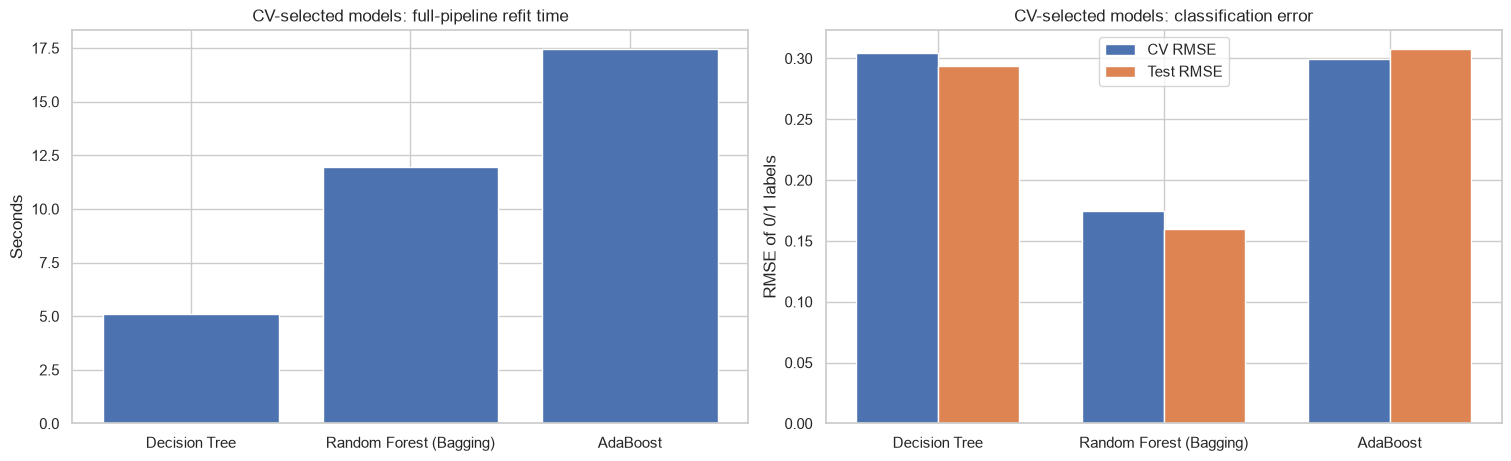

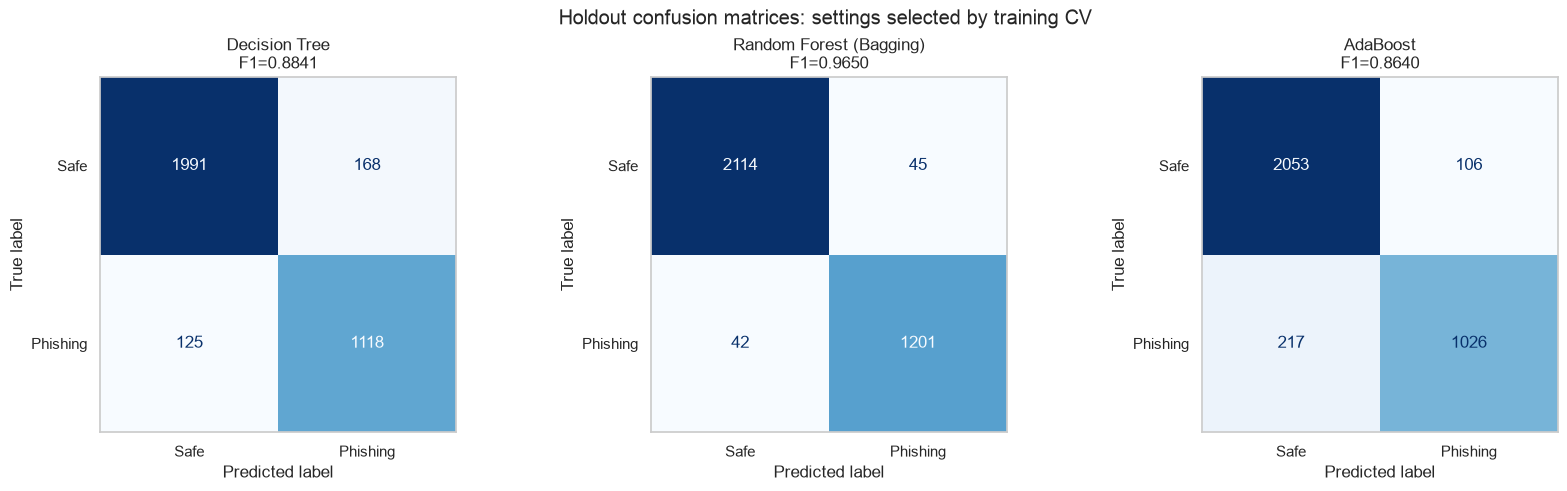

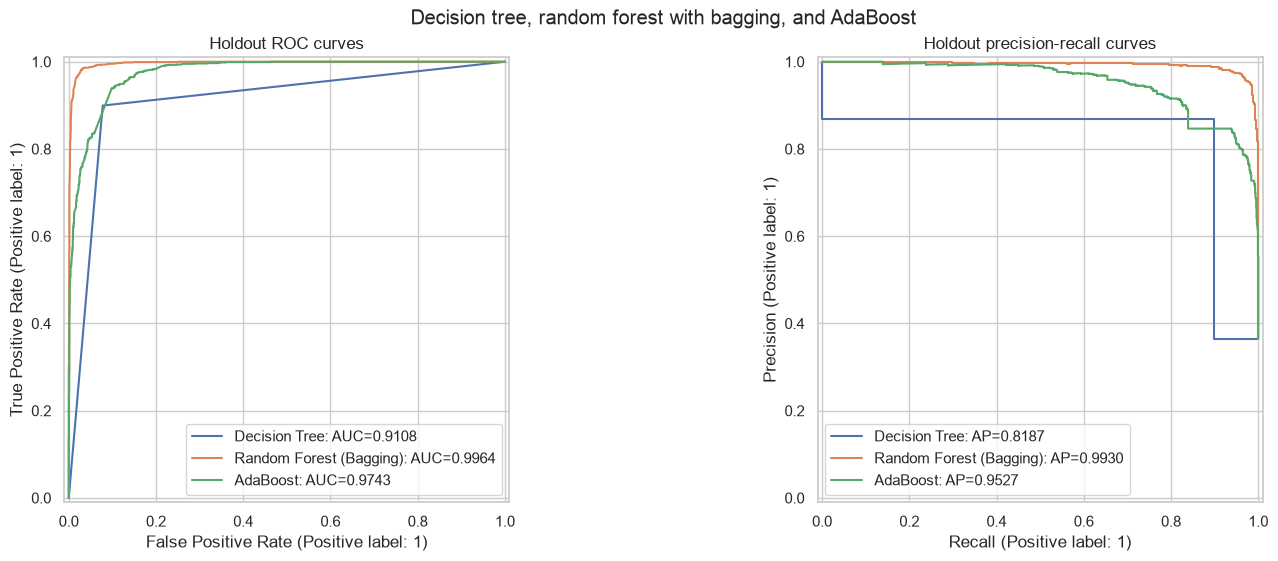

In [232]:
if holdout_results:
    # Compare full-training refit duration and classification error for the three winners.
    chart = holdout_results_df.set_index('model').loc[MODELS_TO_RUN]
    positions = np.arange(len(chart))
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), constrained_layout=True)
    axes[0].bar(positions, chart['Fit_Time_Seconds'])
    axes[0].set(title='CV-selected models: full-pipeline refit time', ylabel='Seconds')
    axes[1].bar(positions - 0.18, chart['CV_RMSE'], width=0.36, label='CV RMSE')
    axes[1].bar(positions + 0.18, chart['Test_RMSE'], width=0.36, label='Test RMSE')
    axes[1].set(title='CV-selected models: classification error', ylabel='RMSE of 0/1 labels')
    axes[1].legend()
    for ax in axes:
        ax.set_xticks(positions, chart.index)
    if SAVE_MODEL_ARTIFACTS:
        fig.savefig(RESULTS_DIR / 'selected_error_and_fit_time.png', dpi=150, bbox_inches='tight')
    plt.show()

    # Same holdout rows and label ordering for every confusion matrix.
    fig, axes = plt.subplots(1, len(MODELS_TO_RUN), figsize=(5.5 * len(MODELS_TO_RUN), 4.8),
                             constrained_layout=True, squeeze=False)
    for ax, name in zip(axes.flat, MODELS_TO_RUN):
        result = holdout_results[name]
        ConfusionMatrixDisplay(result['confusion_matrix'], display_labels=['Safe', 'Phishing']).plot(
            ax=ax, cmap='Blues', colorbar=False, values_format='d')
        ax.grid(False)
        ax.set_title(f"{name}\nF1={result['metrics']['f1']:.4f}")
    fig.suptitle('Holdout confusion matrices: settings selected by training CV')
    if SAVE_MODEL_ARTIFACTS:
        fig.savefig(RESULTS_DIR / 'confusion_matrices.png', dpi=160, bbox_inches='tight')
    plt.show()

    # Ranking plots reuse stored positive-class probabilities; no models are refitted.
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)
    for name in MODELS_TO_RUN:
        result = holdout_results[name]
        RocCurveDisplay.from_predictions(y_test, result['probability_scores'], ax=axes[0], name=name)
        PrecisionRecallDisplay.from_predictions(y_test, result['probability_scores'], ax=axes[1], name=name)
    axes[0].legend([f"{name}: AUC={holdout_results[name]['metrics']['roc_auc']:.4f}" for name in MODELS_TO_RUN],
                   loc='lower right')
    axes[1].legend([f"{name}: AP={holdout_results[name]['metrics']['average_precision']:.4f}" for name in MODELS_TO_RUN],
                   loc='lower left')
    axes[0].set_title('Holdout ROC curves')
    axes[1].set_title('Holdout precision-recall curves')
    fig.suptitle('Decision tree, random forest with bagging, and AdaBoost')
    if SAVE_MODEL_ARTIFACTS:
        fig.savefig(RESULTS_DIR / 'roc_precision_recall.png', dpi=160, bbox_inches='tight')
    plt.show()


### Holdout classification performance: Random Forest, Decision Tree and AdaBoost

On the shared holdout set of **3,402 emails**, I observe that **Random Forest with 300 trees achieves the strongest classification performance**. It has the highest accuracy, phishing F1, ROC-AUC, and average precision, together with the lowest classification RMSE.

For **Random Forest**, holdout accuracy is **97.44%**, precision is **96.39%**, recall is **96.62%**, and F1 is **0.9650**. The confusion matrix shows **1,201 correctly detected phishing emails**, with only **42 missed phishing emails and 45 legitimate emails incorrectly flagged**. Its strong precision and recall indicate that it successfully limits both types of error. Its holdout F1 is also close to its CV F1 of **0.9591**, showing consistent performance across these evaluations.

For the **Decision Tree**, accuracy is **91.39%** and F1 is **0.8841**. It correctly identifies **1,118 phishing emails**, but misses **125** and incorrectly flags **168 legitimate emails**. Its recall of **89.94%** is higher than AdaBoost’s, but its lower precision of **86.94%** reflects more false alarms. The Decision Tree is the fastest model to fit, taking approximately **5.11 seconds**, although this speed comes with substantially more classification errors than Random Forest.

For **AdaBoost**, accuracy is **90.51%** and F1 is **0.8640**. Its precision of **90.64%** exceeds the Decision Tree’s, and it produces fewer false alarms: **106 compared with 168**. However, its recall falls to **82.54%**, resulting in **217 missed phishing emails**, the highest number among the three models. At the prediction rule used here, AdaBoost therefore reduces false alarms relative to the Decision Tree while missing more phishing messages. It also has the longest fit time, approximately **17.48 seconds**, compared with **11.94 seconds** for Random Forest.

The **ROC and precision–recall curves** reinforce Random Forest’s strong performance, with **ROC-AUC of 0.9964 and average precision of 0.9930**. AdaBoost ranks second on these measures, with **0.9743 and 0.9527**, despite having the lowest F1. This distinction shows that AdaBoost ranks emails relatively well by their scores, but its standard classification rule produces a less favorable precision–recall balance. The Decision Tree has weaker ranking performance, with **ROC-AUC of 0.9108 and average precision of 0.8187**.

The error plot also favors Random Forest: its holdout RMSE is **0.1599**, compared with **0.2935 for Decision Tree** and **0.3081 for AdaBoost**. CV and holdout results are broadly similar, without a large deterioration on this holdout set. Because the holdout has been used previously, I interpret these comparisons as exploratory.


## 16. Hyperparameter plots for each model family

For each family, reuse candidate CV scores to plot mean F1, label RMSE, and mean
fold-fit time. Labels show the parameters that vary in the chosen grid; the
factory definitions specify the fixed settings. The star marks the same CV-F1
winner printed in the results section. Error bars show **fold standard deviation**,
not confidence intervals. Training F1 appears when its collection is enabled.
No candidate is retrained just to draw these figures.

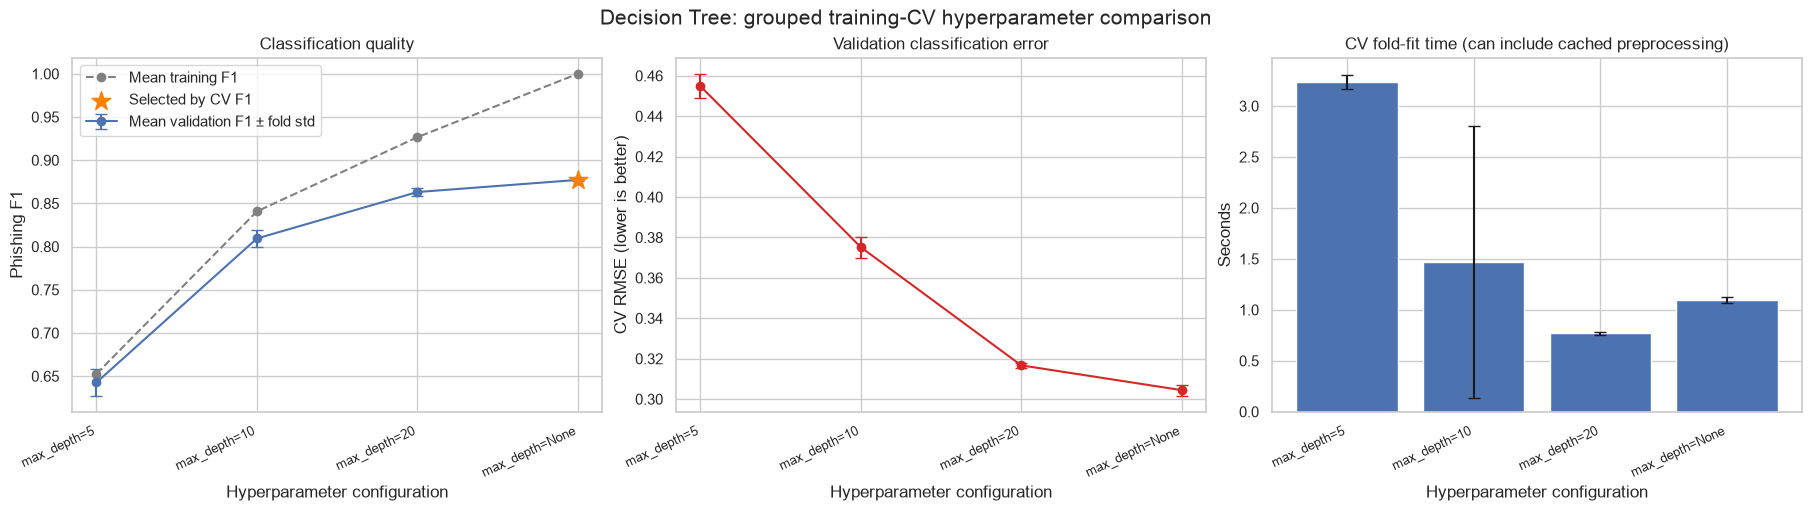

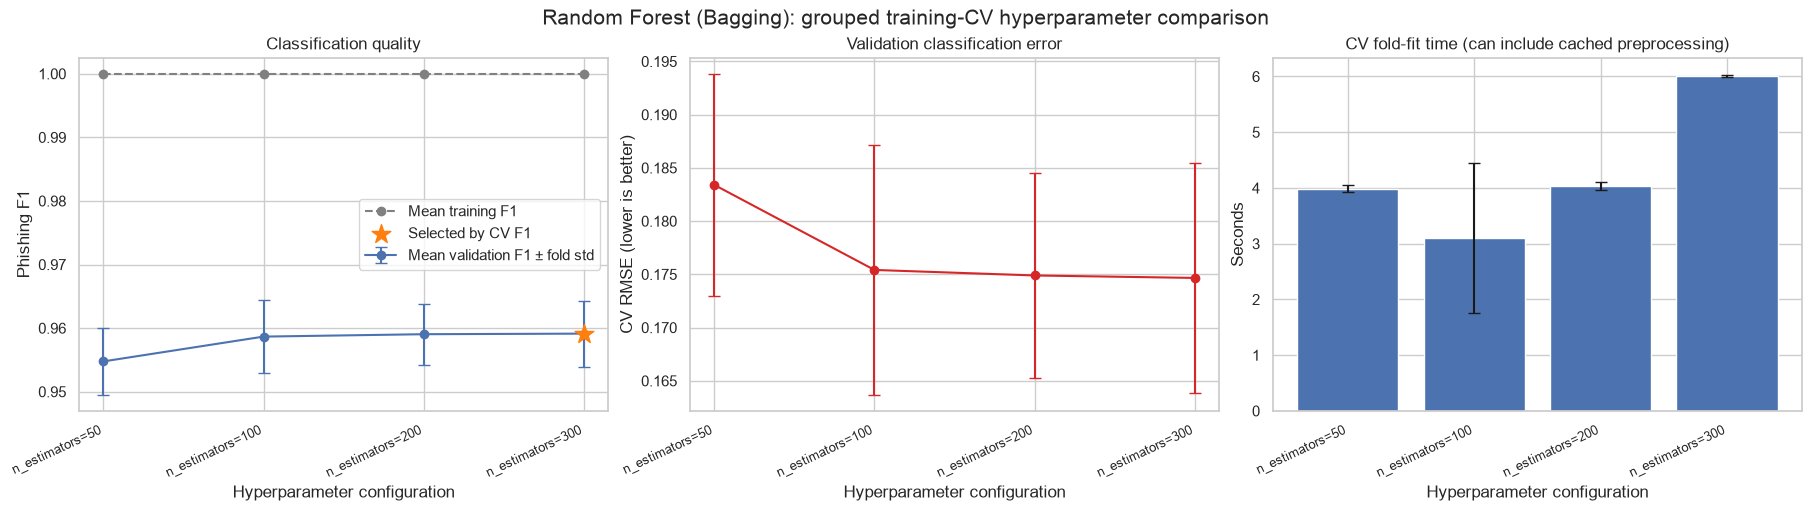

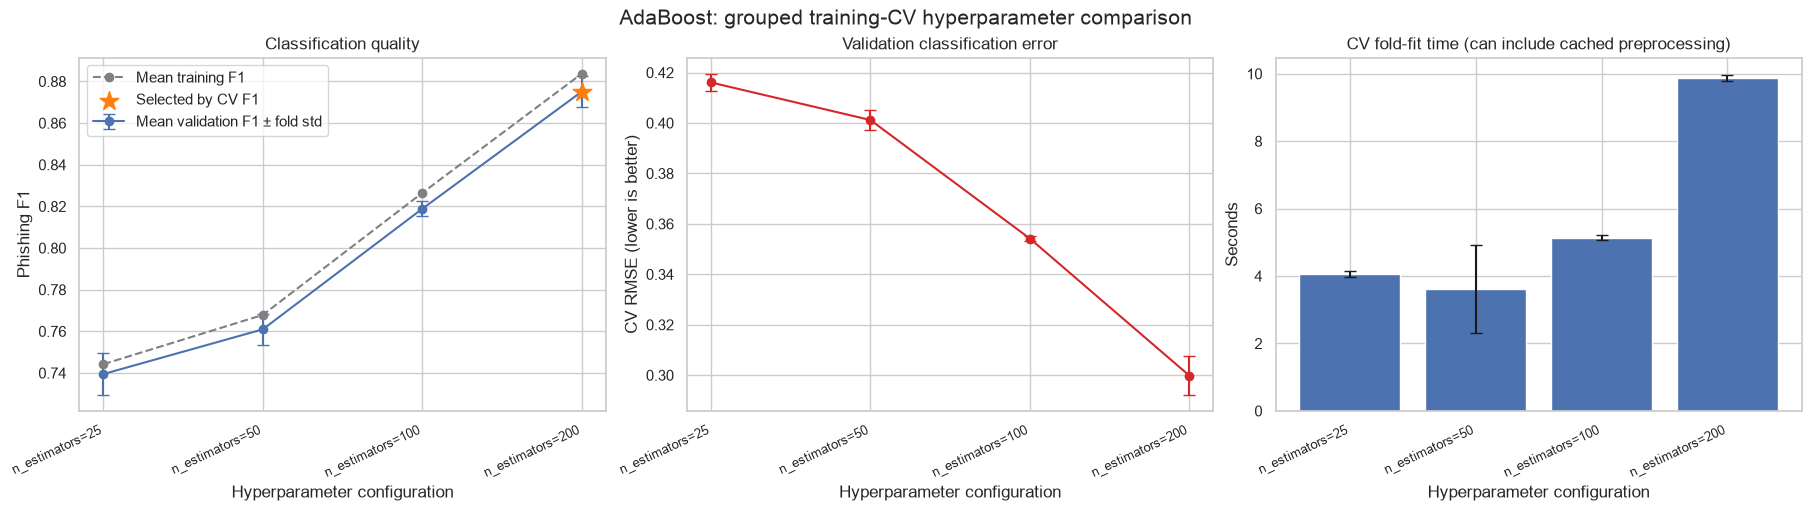

In [233]:
for model_name, search in model_searches.items():
    cv = model_cv_frames[model_name]
    positions = np.arange(len(cv))
    varying_keys = [key for key, values in param_grids[model_name].items() if len(values) > 1]
    labels = ['\n'.join(f'{key.removeprefix("model__")}={parameters[key]}'
                         for key in varying_keys) for parameters in cv['params']]
    fig, axes = plt.subplots(1, 3, figsize=(max(18, len(cv) * 2), 5), constrained_layout=True)
    axes[0].errorbar(positions, cv['mean_test_f1'], yerr=cv['std_test_f1'],
                     fmt='o-', capsize=4, label='Mean validation F1 ± fold std')
    if 'mean_train_f1' in cv:
        axes[0].plot(positions, cv['mean_train_f1'], 'o--', color='gray', label='Mean training F1')
    axes[0].scatter(search.best_index_, search.best_score_, marker='*', s=200,
                    color='tab:orange', zorder=5, label='Selected by CV F1')
    axes[0].set(title='Classification quality', ylabel='Phishing F1')
    axes[0].legend(loc='best')
    axes[1].errorbar(positions, -cv['mean_test_rmse'], yerr=cv['std_test_rmse'],
                     fmt='o-', color='tab:red', capsize=4)
    axes[1].set(title='Validation classification error', ylabel='CV RMSE (lower is better)')
    axes[2].bar(positions, cv['mean_fit_time'], yerr=cv['std_fit_time'], capsize=4)
    axes[2].set(title='CV fold-fit time (can include cached preprocessing)', ylabel='Seconds', ylim=(0, None))
    for ax in axes:
        ax.set_xticks(positions, labels, fontsize=9, rotation=25, ha='right')
        ax.set_xlabel('Hyperparameter configuration')
    fig.suptitle(f'{model_name}: grouped training-CV hyperparameter comparison', fontsize=15)
    if SAVE_MODEL_ARTIFACTS:
        fig.savefig(RESULTS_DIR / f'{MODEL_FILE_STEMS[model_name]}_hyperparameters.png', dpi=150, bbox_inches='tight')
    plt.show()


## 17. Comments on hyperparameter tuning and classification performance

The saved quick search gives **Random Forest the strongest mean validation F1**:
**0.9591** with 300 trees. The figures below are rounded from the saved CV table,
not estimated from the plots.

- **Decision Tree:** Increasing depth from 5 to unrestricted raises validation F1 from **0.6427 to 0.8772**, while label RMSE falls from **0.4549 to 0.3044**. Training F1 rises from **0.6527 to 1.0000**, so the training–validation gap grows. Depth 5 appears to underfit relative to the deeper candidates. The unrestricted tree has a substantial generalization gap, but also the best validation F1 tested; these results do not show validation performance deteriorating as depth increases.
- **Random Forest:** Validation F1 rises from **0.9548 at 50 trees to 0.9591 at 300**. Gains after 100 trees are small, and fold error bars overlap. Training F1 is **1.0000** for all four settings. Mean CV fit time is **3.10 seconds at 100 trees** and **6.02 seconds at 300**, so the extra computation buys little additional mean F1 in this run.
- **AdaBoost:** Validation F1 rises from **0.7395 at 25 rounds to 0.8751 at 200**, while label RMSE falls from **0.4161 to 0.2999**. Training and validation F1 remain close, but both stay below Random Forest's results. Mean CV fit time increases from **5.14 seconds at 100 rounds to 9.88 seconds at 200**.

These are CV fold means, not holdout scores or full-training refit times.
Timing includes pipeline fitting and is affected by preprocessing cache hits and
concurrent workers; it need not increase monotonically with model size.


## 18. Actions I took to avoid overfitting and how I assessed whether they worked

I used grouped cross-validation and model-complexity comparisons to guide selection, then compared training, validation, and holdout results.

**Actions I took**

1. **I handled duplicates and separated related emails:** I removed exact duplicates, checked conflicting labels, and kept matching normalized email groups together in the train/holdout split and three CV folds.
2. **I fitted TF-IDF within each fold:** Vocabulary and IDF used only the fold's training rows; labels and metadata were excluded from predictors. These models used nine raw counts; the log1p transformation was used only for EDA.
3. **I limited the vocabulary:** I used up to 5,000 unigram/bigram features and excluded terms occurring in fewer than five fitting emails.
4. **I compared model complexity:** I tested Decision Tree depths of 5, 10, 20, and None; Random Forest sizes of 50, 100, 200, and 300 trees; and AdaBoost limits of 25, 50, 100, and 200 estimators. I selected each configuration and the overall family by mean validation phishing F1.
5. **I used ensemble controls:** Random Forest used bootstrap samples and `max_features="sqrt"`, mechanisms intended to reduce variance through averaging diverse trees ([scikit-learn explanation](https://scikit-learn.org/stable/modules/ensemble.html#random-forests)). AdaBoost used depth-1 decision stumps, limiting each learner's complexity; its learning rate remained 1.0.
6. **I measured generalization gaps:** I enabled `COLLECT_TRAIN_SCORES=True`, used **14,109 training/CV emails**, and evaluated the refitted models on **3,402 holdout emails** after selecting them by CV.

**What I observed**

Training and validation F1 were fold means; holdout F1 came from each selected model refitted on all training rows. Gaps were training F1 minus validation F1, calculated before rounding.

| Model | Selected setting | Training F1 | Validation F1 | F1 gap | Holdout F1 |
|---|---|---:|---:|---:|---:|
| Decision Tree | `max_depth=None` | 1.000000 | 0.877193 | 0.122807 | 0.884144 |
| Random Forest (Bagging) | 300 trees | 1.000000 | 0.959133 | 0.040867 | 0.965046 |
| AdaBoost | `n_estimators=200` | 0.883685 | 0.875087 | 0.008598 | 0.864000 |

- **Decision Tree:** The unrestricted tree had the best validation F1 in its grid, but perfect training F1 and a **0.122807 gap** showed a substantial generalization gap. Validation F1 still improved with depth, so the grid did not establish that the selected tree was deeper than the validation optimum. Depth 5 had much lower training/validation F1 (**0.652701/0.642722**), suggesting underfitting. Testing depth limits exposed this trade-off; it did not result in selecting a shallow or pruned tree.
- **Random Forest:** Its **0.040867 gap** was smaller than the unrestricted tree's, and it achieved the highest validation and holdout F1. Training RMSE was **0.000000**, CV RMSE **0.174663**, and holdout RMSE **0.159916**. The similar validation and holdout errors supported consistent performance on this split, while the perfect training fit still showed a generalization gap.
- **AdaBoost:** Its **0.008598 gap** was the smallest, but its training, validation, and holdout F1 were lower than Random Forest's. Validation F1 improved from **0.739469 at 25 estimators to 0.875087 at 200**. A small gap alone therefore did not identify the best classifier.

I retained **Random Forest with 300 trees** using validation F1. It also achieved **97.44% holdout accuracy**, with **45 false positives and 42 missed phishing emails**. Its CV F1 advantage over 200 trees was only about **0.000091**, so I did not interpret that small difference as a decisive advantage beyond this run.

These results supported the selected model on this dataset, but did not prove that overfitting had been eliminated. CV measured performance on unseen folds and guided selection; it did not itself remove the gaps. The quick run did not tune pruning, minimum leaf sizes, or AdaBoost's learning rate. Full-corpus EDA, the full-corpus length cap, and prior holdout inspection kept the comparison exploratory; I did not establish performance on future phishing emails or isolate the benefit of truncation or the nine added counts.


# 20- Week 9 Gradient Boost


## Simple gradient boosting 


1. Start with the mean training label.
2. Calculate the errors: `residual = y - prediction`.
3. Fit a small regression tree to those errors.
4. Update: `prediction += learning_rate * tree_prediction`.

Labels are **Safe=0** and **Phishing=1**. Predict phishing when the final
score is **at least 0.5**. 

In [ ]:
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

### 21. Set aside validation rows
Use the first existing grouped CV split as one fixed training/validation split.
Remove validation text already present in fitting rows. Similarly, exclude
holdout text already present in the full training set.

In [235]:
gb_fit_rows, gb_valid_rows = cv_splits[0]
gb_fit = train_df.iloc[gb_fit_rows].copy()
gb_valid = train_df.iloc[gb_valid_rows].copy()
gb_valid = gb_valid.loc[~gb_valid[TEXT_COLUMN].isin(gb_fit[TEXT_COLUMN])]

# Keep the final holdout separate from hyperparameter selection.
gb_test_mask = ~test_df[TEXT_COLUMN].isin(train_df[TEXT_COLUMN])
gb_X_test = X_test[gb_test_mask.to_numpy()]
gb_y_test = y_test[gb_test_mask.to_numpy()]
print(f'Fit: {len(gb_fit):,}; validation: {len(gb_valid):,}; holdout: {len(gb_y_test):,}')
print(f'Holdout text matches excluded: {(~gb_test_mask).sum()}')


Fit: 9,509; validation: 4,598; holdout: 3,399
Holdout text matches excluded: 3


#### Build validation features using fitting text only
Create a fresh vectorizer for gradient boost with the existing settings. This prevents validation
text from influencing vocabulary or IDF. Append the same nine raw count features.
The final model will use the existing full-training `X_train` matrix.

In [236]:
gb_vectorizer = TfidfVectorizer(**tfidf_vectorizer.get_params())
gb_fit_text = gb_vectorizer.fit_transform(gb_fit[TEXT_COLUMN])
gb_valid_text = gb_vectorizer.transform(gb_valid[TEXT_COLUMN])

gb_X_fit = sparse.hstack([gb_fit_text, gb_fit[COUNT_FEATURE_COLUMNS].to_numpy()], format='csr')
gb_X_valid = sparse.hstack([gb_valid_text, gb_valid[COUNT_FEATURE_COLUMNS].to_numpy()], format='csr')
gb_y_fit = gb_fit[TARGET_COLUMN].to_numpy()
gb_y_valid = gb_valid[TARGET_COLUMN].to_numpy()


### 22. Fit and predict with small trees
Each tree learns the errors left by the previous trees. `max_leaf_nodes` limits tree size;
`min_samples_leaf` requires enough emails to support each leaf's prediction.
The exploratory search uses 5; the later grouped check also tries 10, 20, and 50.


In [237]:
def fit_gradient_boost_small_trees(X, y, n_trees=100, max_leaf_nodes=3, learning_rate=.1,
                                  min_samples_leaf=5):
    """Fit small trees to residuals; return the trees and initial mean prediction."""
    initial_prediction = float(np.mean(y))
    prediction = np.full(len(y), initial_prediction)
    trees = []
    for stage in range(n_trees):
        residual = y - prediction
        tree = DecisionTreeRegressor(max_leaf_nodes=max_leaf_nodes,
                                      min_samples_leaf=min_samples_leaf, random_state=42 + stage)
        tree.fit(X, residual)
        prediction += learning_rate * tree.predict(X)
        trees.append(tree)
    return trees, initial_prediction


In [238]:
def predict_gradient_boost_small_trees(trees, X, initial_prediction, learning_rate=.1):
    """Add the initial mean and scaled tree predictions to produce email scores."""
    prediction = np.full(X.shape[0], initial_prediction)
    for tree in trees:
        prediction += learning_rate * tree.predict(X)
    return prediction


### 23. Explore the original hyperparameter grid
Compare **80 settings**: five tree counts, four learning rates, and four tree sizes.
Use validation RMSE to rank them, matching the sample's error measure.
Also record classification accuracy at the fixed 0.5 threshold.

Fit 150 trees once per learning-rate/tree-size pair and reuse tree prefixes.
This first-split search is exploratory for creating the strategy going forward

In [239]:
gb_tree_counts = [25, 50, 100, 125, 150]
gb_learning_rates = [.05, .1, .15, .2]
gb_leaf_counts = [3, 5, 7, 9]


In [240]:
gb_results = []
gb_runs = {}
for rate in gb_learning_rates:
    for leaves in gb_leaf_counts:
        trees, initial = fit_gradient_boost_small_trees(
            gb_X_fit, gb_y_fit, max(gb_tree_counts), leaves, rate)
        gb_runs[(rate, leaves)] = (trees, initial)
        for count in gb_tree_counts:
            scores = predict_gradient_boost_small_trees(trees[:count], gb_X_valid, initial, rate)
            gb_results.append({
                'n_trees': count, 'learning_rate': rate, 'max_leaf_nodes': leaves,
                'validation_rmse': np.sqrt(np.mean((gb_y_valid - scores) ** 2)),
                'validation_accuracy': np.mean((scores >= .5) == gb_y_valid),
            })
        print(f'Finished learning rate={rate}, maximum leaves={leaves}')
gb_results = pd.DataFrame(gb_results).sort_values('validation_rmse').reset_index(drop=True)
display(gb_results.round(4))


Finished learning rate=0.05, maximum leaves=3
Finished learning rate=0.05, maximum leaves=5
Finished learning rate=0.05, maximum leaves=7
Finished learning rate=0.05, maximum leaves=9
Finished learning rate=0.1, maximum leaves=3
Finished learning rate=0.1, maximum leaves=5
Finished learning rate=0.1, maximum leaves=7
Finished learning rate=0.1, maximum leaves=9
Finished learning rate=0.15, maximum leaves=3
Finished learning rate=0.15, maximum leaves=5
Finished learning rate=0.15, maximum leaves=7
Finished learning rate=0.15, maximum leaves=9
Finished learning rate=0.2, maximum leaves=3
Finished learning rate=0.2, maximum leaves=5
Finished learning rate=0.2, maximum leaves=7
Finished learning rate=0.2, maximum leaves=9


,n_trees,learning_rate,max_leaf_nodes,validation_rmse,validation_accuracy
0,150,0.20,9,0.2185,0.9550
1,125,0.20,9,0.2213,0.9522
2,150,0.15,9,0.2226,0.9545
3,100,0.20,9,0.2252,0.9487
4,125,0.15,9,0.2261,0.9515
...,...,...,...,...,...
75,25,0.05,7,0.3621,0.8454
76,25,0.10,3,0.3777,0.8108
77,50,0.05,3,0.3793,0.8149
78,25,0.05,5,0.3797,0.8188


In [241]:
gb_best = gb_results.iloc[0]
gb_best_count = int(gb_best['n_trees'])
gb_best_rate = float(gb_best['learning_rate'])
gb_best_leaves = int(gb_best['max_leaf_nodes'])
print(f'Best: {gb_best_count} trees, learning rate {gb_best_rate}, maximum {gb_best_leaves} leaves')


Best: 150 trees, learning rate 0.2, maximum 9 leaves


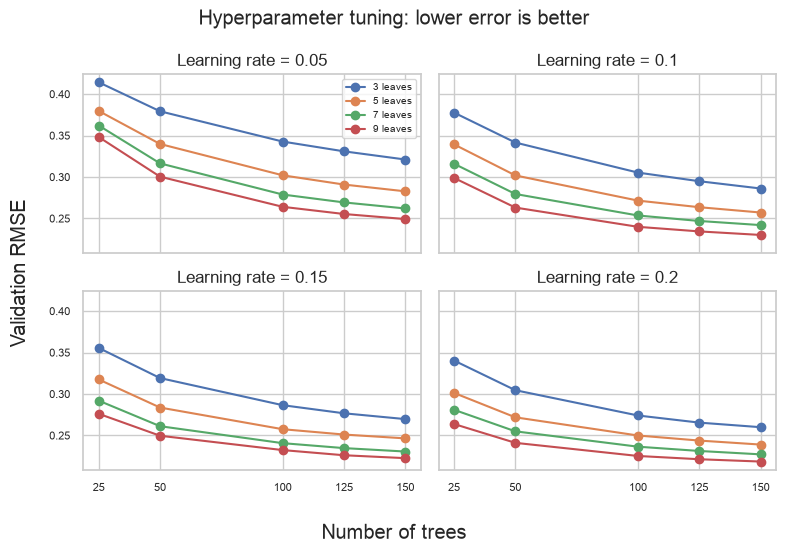

In [242]:
# One panel per learning rate keeps the expanded search easy to compare.
fig, axes = plt.subplots(2, 2, figsize=(8, 5.5), sharex=True, sharey=True)
for ax, rate in zip(axes.flat, gb_learning_rates):
    for leaves in gb_leaf_counts:
        rows = gb_results[(gb_results.learning_rate == rate) &
                          (gb_results.max_leaf_nodes == leaves)].sort_values('n_trees')
        ax.plot(rows.n_trees, rows.validation_rmse, 'o-', label=f'{leaves} leaves')
    ax.set_title(f'Learning rate = {rate}')
    ax.set_xticks(gb_tree_counts)
    ax.tick_params(labelsize=8)
axes[0, 0].legend(fontsize=7)
fig.supxlabel('Number of trees')
fig.supylabel('Validation RMSE')
fig.suptitle('Hyperparameter tuning: lower error is better')
plt.tight_layout()
plt.show()


### Learning rate observations 

We see that higher learning rate of 0.2 is behaving best and the lowest one is not doing a good job so we could use between 01 and 0.3 in the final stages when we do finetuning


### 24. Inspect the exploratory error curves

- High fitting and validation errors suggest underfitting.
- Falling fitting error with a sustained rise in validation error suggests overfitting.
- A gap can remain even while validation error improves.

These curves use the first split. The next section compares all three folds
before selecting the final model.


In [243]:
def boosting_rmse_by_stage(trees, X, y, initial_prediction, learning_rate=.1):
    """Return RMSE before boosting and after each successive tree correction."""
    prediction = np.full(len(y), initial_prediction)
    errors = [np.sqrt(np.mean((y - prediction) ** 2))]
    for tree in trees:
        prediction += learning_rate * tree.predict(X)
        errors.append(np.sqrt(np.mean((y - prediction) ** 2)))
    return np.array(errors)


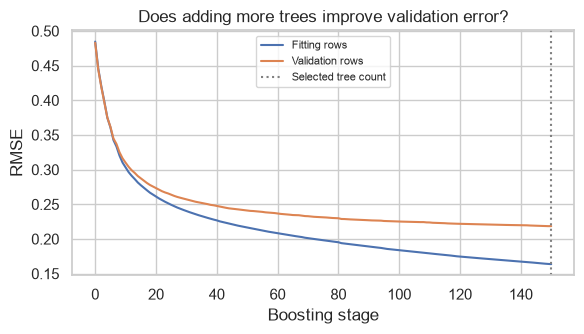

In [244]:
gb_curve_trees, gb_curve_initial = gb_runs[(gb_best_rate, gb_best_leaves)]
gb_fit_errors = boosting_rmse_by_stage(gb_curve_trees, gb_X_fit, gb_y_fit, gb_curve_initial, gb_best_rate)
gb_valid_errors = boosting_rmse_by_stage(gb_curve_trees, gb_X_valid, gb_y_valid, gb_curve_initial, gb_best_rate)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(gb_fit_errors, label='Fitting rows')
ax.plot(gb_valid_errors, label='Validation rows')
ax.axvline(gb_best_count, color='gray', linestyle=':', label='Selected tree count')
ax.set(xlabel='Boosting stage', ylabel='RMSE', title='Does adding more trees improve validation error?')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


### 25. Check stronger regularization across three grouped folds
Try minimum leaf sizes **5, 10, 20, and 50** for the two leading distinct
learning-rate/tree-size pairs from the exploratory search: **8 configurations**.
For each, measure every stage from 1 to 150 on all three existing grouped folds.

Fit vocabulary/IDF inside each fold and remove matching prepared text from that
fold's validation rows. Keep the holdout out of model selection.
This is a focused second-stage search, not an exhaustive search of every possible
parameter combination. CV scores guide selection; they are not an independent
estimate after tuning on them.


In [245]:
gb_shortlist = gb_results.drop_duplicates(['learning_rate', 'max_leaf_nodes']).head(2)
gb_min_leaf_sizes = [5, 10, 20, 50]
gb_candidates = [(float(row.learning_rate), int(row.max_leaf_nodes), minimum)
                 for row in gb_shortlist.itertuples() for minimum in gb_min_leaf_sizes]
display(pd.DataFrame(gb_candidates,
                    columns=['learning_rate', 'max_leaf_nodes', 'min_samples_leaf']))


,learning_rate,max_leaf_nodes,min_samples_leaf
0,0.20,9,5
1,0.20,9,10
2,0.20,9,20
3,0.20,9,50
4,0.15,9,5
5,0.15,9,10
6,0.15,9,20
7,0.15,9,50


In [246]:
def make_boosting_fold(fit_rows, valid_rows):
    """Build one grouped fold, learning TF-IDF only from its fitting emails."""
    fit = train_df.iloc[fit_rows]
    valid = train_df.iloc[valid_rows]
    valid = valid.loc[~valid[TEXT_COLUMN].isin(fit[TEXT_COLUMN])]
    assert set(fit.group_id).isdisjoint(valid.group_id)
    assert set(fit[TEXT_COLUMN]).isdisjoint(valid[TEXT_COLUMN])
    vectorizer = TfidfVectorizer(**tfidf_vectorizer.get_params())
    fit_text = vectorizer.fit_transform(fit[TEXT_COLUMN])
    valid_text = vectorizer.transform(valid[TEXT_COLUMN])
    X_fit = sparse.hstack([fit_text, fit[COUNT_FEATURE_COLUMNS].to_numpy()], format='csr')
    X_valid = sparse.hstack([valid_text, valid[COUNT_FEATURE_COLUMNS].to_numpy()], format='csr')
    return X_fit, fit[TARGET_COLUMN].to_numpy(), X_valid, valid[TARGET_COLUMN].to_numpy()


In [247]:
def boosting_metrics_by_stage(trees, X, y, initial_prediction, learning_rate):
    """Measure RMSE, accuracy, and phishing recall after each added tree."""
    prediction = np.full(len(y), initial_prediction)
    records = []
    for stage, tree in enumerate(trees, start=1):
        prediction += learning_rate * tree.predict(X)
        labels = prediction >= .5
        records.append({'n_trees': stage,
                        'rmse': np.sqrt(np.mean((y - prediction) ** 2)),
                        'accuracy': np.mean(labels == y),
                        'phishing_recall': np.mean(labels[y == 1])})
    return pd.DataFrame(records).set_index('n_trees')


In [248]:
gb_fold_results = []
for fold, (fit_rows, valid_rows) in enumerate(cv_splits, start=1):
    X_fit, y_fit, X_valid, y_valid = make_boosting_fold(fit_rows, valid_rows)
    for rate, leaves, minimum in gb_candidates:
        trees, initial = fit_gradient_boost_small_trees(
            X_fit, y_fit, max(gb_tree_counts), leaves, rate, minimum)
        fitting = boosting_metrics_by_stage(trees, X_fit, y_fit, initial, rate)
        validation = boosting_metrics_by_stage(trees, X_valid, y_valid, initial, rate)
        history = fitting.add_prefix('train_').join(validation.add_prefix('validation_'))
        gb_fold_results.append(history.reset_index().assign(
            fold=fold, learning_rate=rate, max_leaf_nodes=leaves, min_samples_leaf=minimum))
        print(f'Fold {fold}: rate={rate}, leaves={leaves}, minimum leaf size={minimum}')
gb_cv_history = pd.concat(gb_fold_results, ignore_index=True)


Fold 1: rate=0.2, leaves=9, minimum leaf size=5
Fold 1: rate=0.2, leaves=9, minimum leaf size=10
Fold 1: rate=0.2, leaves=9, minimum leaf size=20
Fold 1: rate=0.2, leaves=9, minimum leaf size=50
Fold 1: rate=0.15, leaves=9, minimum leaf size=5
Fold 1: rate=0.15, leaves=9, minimum leaf size=10
Fold 1: rate=0.15, leaves=9, minimum leaf size=20
Fold 1: rate=0.15, leaves=9, minimum leaf size=50
Fold 2: rate=0.2, leaves=9, minimum leaf size=5
Fold 2: rate=0.2, leaves=9, minimum leaf size=10
Fold 2: rate=0.2, leaves=9, minimum leaf size=20
Fold 2: rate=0.2, leaves=9, minimum leaf size=50
Fold 2: rate=0.15, leaves=9, minimum leaf size=5
Fold 2: rate=0.15, leaves=9, minimum leaf size=10
Fold 2: rate=0.15, leaves=9, minimum leaf size=20
Fold 2: rate=0.15, leaves=9, minimum leaf size=50
Fold 3: rate=0.2, leaves=9, minimum leaf size=5
Fold 3: rate=0.2, leaves=9, minimum leaf size=10
Fold 3: rate=0.2, leaves=9, minimum leaf size=20
Fold 3: rate=0.2, leaves=9, minimum leaf size=50
Fold 3: rate=0.15

#### Select the best score and a simpler alternative
First find the lowest **mean validation RMSE** across the three folds.
Then use the **one-standard-error rule**: accept configurations within one
standard error of that minimum and prefer fewer total possible leaves
(`n_trees × max_leaf_nodes`), then a larger minimum leaf size.

This chooses a smaller ensemble when its validation error is close to the best.
It is a practical selection rule, not proof that models are statistically equal.
We fit all 150 stages to compare the curves, then retain the chosen prefix;
this is validation-based stopping-point selection, not an early exit from fitting.


In [249]:
gb_parameters = ['learning_rate', 'max_leaf_nodes', 'min_samples_leaf', 'n_trees']
gb_cv_summary = gb_cv_history.groupby(gb_parameters, as_index=False).agg(
    mean_train_rmse=('train_rmse', 'mean'), mean_validation_rmse=('validation_rmse', 'mean'),
    std_validation_rmse=('validation_rmse', 'std'),
    mean_train_accuracy=('train_accuracy', 'mean'),
    mean_validation_accuracy=('validation_accuracy', 'mean'),
    std_validation_accuracy=('validation_accuracy', 'std'),
    mean_phishing_recall=('validation_phishing_recall', 'mean'))
gb_cv_summary['rmse_se'] = gb_cv_summary.std_validation_rmse / np.sqrt(len(cv_splits))
gb_cv_summary['accuracy_gap'] = gb_cv_summary.mean_train_accuracy - gb_cv_summary.mean_validation_accuracy
gb_cv_best = gb_cv_summary.loc[gb_cv_summary.mean_validation_rmse.idxmin()]
gb_rmse_limit = gb_cv_best.mean_validation_rmse + gb_cv_best.rmse_se
# This complexity measure favors fewer trees and fewer leaves per tree.
gb_eligible = gb_cv_summary.loc[gb_cv_summary.mean_validation_rmse <= gb_rmse_limit].copy()
gb_eligible['total_leaf_limit'] = gb_eligible.n_trees * gb_eligible.max_leaf_nodes
gb_selected = gb_eligible.sort_values(
    ['total_leaf_limit', 'min_samples_leaf', 'mean_validation_rmse'],
    ascending=[True, False, True]).iloc[0]


In [250]:
gb_baseline = gb_cv_summary.loc[
    (gb_cv_summary.learning_rate == gb_best_rate) &
    (gb_cv_summary.max_leaf_nodes == gb_best_leaves) &
    (gb_cv_summary.min_samples_leaf == 5) & (gb_cv_summary.n_trees == gb_best_count)].iloc[0]
gb_cv_comparison = pd.DataFrame([gb_baseline, gb_cv_best, gb_selected],
    index=['Original setting', 'Lowest CV error', 'Selected simpler model'])
gb_columns = gb_parameters + ['mean_validation_rmse', 'mean_train_accuracy',
    'mean_validation_accuracy', 'std_validation_accuracy', 'mean_phishing_recall', 'accuracy_gap']
display(gb_cv_comparison[gb_columns].round(4))
print(f'One-standard-error RMSE limit: {gb_rmse_limit:.4f}')
print('Best mean CV score and final simpler choice are shown separately above.')


,learning_rate,max_leaf_nodes,min_samples_leaf,n_trees,mean_validation_rmse,mean_train_accuracy,mean_validation_accuracy,std_validation_accuracy,mean_phishing_recall,accuracy_gap
Original setting,0.2,9.0,5.0,150.0,0.2179,0.9878,0.9595,0.0056,0.9330,0.0284
Lowest CV error,0.2,9.0,20.0,150.0,0.2151,0.9844,0.9630,0.0061,0.9381,0.0213
Selected simpler model,0.2,9.0,20.0,138.0,0.2167,0.9827,0.9618,0.0056,0.9355,0.0209


One-standard-error RMSE limit: 0.2167
Best mean CV score and final simpler choice are shown separately above.


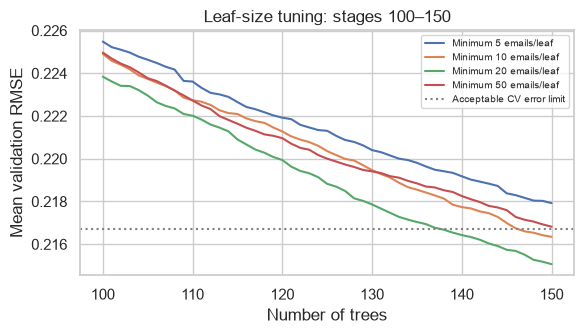

In [251]:
# Zoom in on later stages to make differences between leaf limits visible.
gb_leaf_plot = gb_cv_summary.loc[(gb_cv_summary.learning_rate == gb_best_rate) &
                               (gb_cv_summary.max_leaf_nodes == gb_best_leaves)]
fig, ax = plt.subplots(figsize=(6, 3.5))
for minimum, rows in gb_leaf_plot.groupby('min_samples_leaf'):
    rows = rows.loc[rows.n_trees >= 100]
    ax.plot(rows.n_trees, rows.mean_validation_rmse, label=f'Minimum {minimum} emails/leaf')
ax.axhline(gb_rmse_limit, color='gray', linestyle=':', label='Acceptable CV error limit')
ax.set(xlabel='Number of trees', ylabel='Mean validation RMSE', title='Leaf-size tuning: stages 100–150')
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()


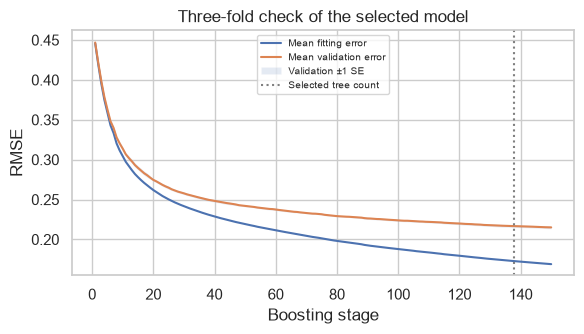

In [252]:
gb_selected_history = gb_cv_history.loc[
    (gb_cv_history.learning_rate == gb_selected.learning_rate) &
    (gb_cv_history.max_leaf_nodes == gb_selected.max_leaf_nodes) &
    (gb_cv_history.min_samples_leaf == gb_selected.min_samples_leaf)]
gb_mean_curve = gb_selected_history.groupby('n_trees')[['train_rmse', 'validation_rmse']].mean()
gb_curve_se = gb_selected_history.groupby('n_trees').validation_rmse.std() / np.sqrt(len(cv_splits))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(gb_mean_curve.index, gb_mean_curve.train_rmse, label='Mean fitting error')
ax.plot(gb_mean_curve.index, gb_mean_curve.validation_rmse, label='Mean validation error')
ax.fill_between(gb_mean_curve.index, gb_mean_curve.validation_rmse - gb_curve_se,
                gb_mean_curve.validation_rmse + gb_curve_se, alpha=.15, label='Validation ±1 SE')
ax.axvline(gb_selected.n_trees, color='gray', linestyle=':', label='Selected tree count')
ax.set(xlabel='Boosting stage', ylabel='RMSE', title='Three-fold check of the selected model')
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()


,fold,train_accuracy,validation_accuracy,validation_phishing_recall,accuracy_gap
437,1,0.9840,0.9556,0.9266,0.0284
1637,2,0.9806,0.9629,0.9345,0.0177
2837,3,0.9834,0.9667,0.9455,0.0166


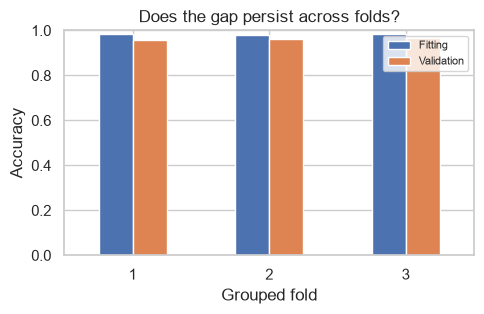

In [253]:
gb_selected_folds = gb_selected_history.loc[gb_selected_history.n_trees == gb_selected.n_trees].copy()
gb_selected_folds['accuracy_gap'] = gb_selected_folds.train_accuracy - gb_selected_folds.validation_accuracy
display(gb_selected_folds[['fold', 'train_accuracy', 'validation_accuracy',
                           'validation_phishing_recall', 'accuracy_gap']].round(4))
fig, ax = plt.subplots(figsize=(5, 3.3))
gb_selected_folds.set_index('fold')[['train_accuracy', 'validation_accuracy']].plot.bar(ax=ax, rot=0)
ax.set(xlabel='Grouped fold', ylabel='Accuracy', ylim=(0, 1), title='Does the gap persist across folds?')
ax.legend(['Fitting', 'Validation'], fontsize=8)
plt.tight_layout()
plt.show()


### Very small gaps across folds so thats what we want

### 26. Fit the selected model and evaluate the holdout
Fit a fresh ensemble with the selected number of trees using all original training rows. The fixed
0.5 threshold produces Safe/Phishing labels; regression scores are not probabilities.
Holdout results do not select settings. Because this holdout has already been
viewed in earlier development, fresh external emails would give a stronger final check.


In [254]:
gb_final_count = int(gb_selected.n_trees)
gb_final_rate = float(gb_selected.learning_rate)
gb_final_leaves = int(gb_selected.max_leaf_nodes)
gb_final_minimum = int(gb_selected.min_samples_leaf)
gb_trees, gb_initial = fit_gradient_boost_small_trees(
    X_train, y_train, gb_final_count, gb_final_leaves, gb_final_rate, gb_final_minimum)
gb_train_scores = predict_gradient_boost_small_trees(gb_trees, X_train, gb_initial, gb_final_rate)
gb_test_scores = predict_gradient_boost_small_trees(gb_trees, gb_X_test, gb_initial, gb_final_rate)
gb_test_predictions = (gb_test_scores >= .5).astype(int)

gb_train_accuracy = np.mean((gb_train_scores >= .5) == y_train)
gb_test_accuracy = np.mean(gb_test_predictions == gb_y_test)
print(f'Training accuracy: {gb_train_accuracy:.2%}')
print(f'Mean grouped CV accuracy: {gb_selected.mean_validation_accuracy:.2%}')
print(f'Holdout accuracy: {gb_test_accuracy:.2%}')
print(classification_report(gb_y_test, gb_test_predictions, labels=[0, 1],
                            target_names=['Safe', 'Phishing'], zero_division=0))


Training accuracy: 98.07%
Mean grouped CV accuracy: 96.18%
Holdout accuracy: 95.68%
              precision    recall  f1-score   support

        Safe       0.96      0.98      0.97      2159
    Phishing       0.96      0.92      0.94      1240

    accuracy                           0.96      3399
   macro avg       0.96      0.95      0.95      3399
weighted avg       0.96      0.96      0.96      3399



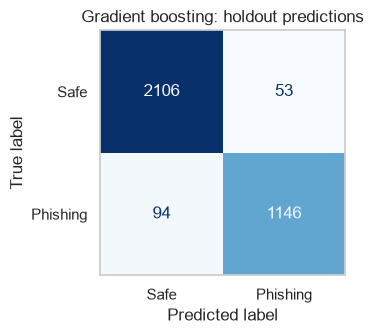

In [255]:
fig, ax = plt.subplots(figsize=(4, 3.5))
ConfusionMatrixDisplay.from_predictions(gb_y_test, gb_test_predictions,
    labels=[0, 1], display_labels=['Safe', 'Phishing'], cmap='Blues', colorbar=False, ax=ax)
ax.grid(False)
ax.set_title('Gradient boosting: holdout predictions')
plt.tight_layout()
plt.show()


### Initial results 

### 27. Look at the first small tree
Following the sample's tree display, show the first tree through **depth 2**: the root and the next two levels.
Its leaf value is an error correction, not a class label. Multiply it by the
learning rate before adding it to the current email score. Ellipses mark omitted
branches; `tfidf__` features are word weights and `count__` features are raw counts.


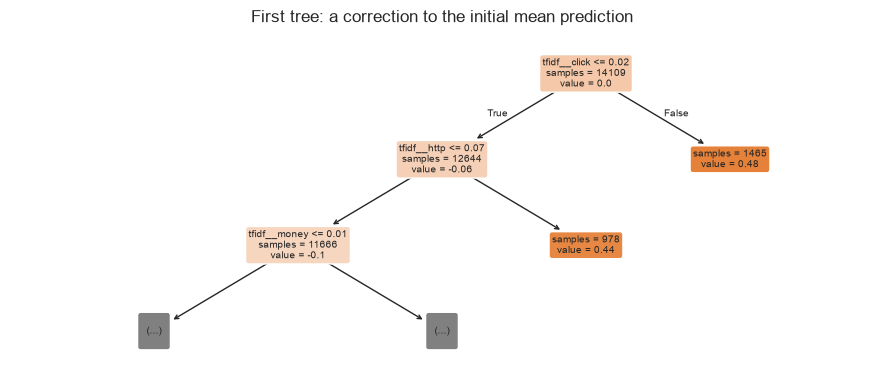

In [256]:
fig, ax = plt.subplots(figsize=(9, 4))
plot_tree(gb_trees[0], feature_names=list(feature_names), max_depth=2,
           filled=True, rounded=True, impurity=False, precision=2, fontsize=7, ax=ax)
ax.set_title('First tree: a correction to the initial mean prediction')
plt.tight_layout()
plt.show()


### Comments on hyperparameter tuning and classification performance

I kept the original **80-setting exploratory search** and checked its two leading learning-rate/tree-size pairs with minimum leaf sizes **5, 10, 20, and 50**. Each of these **8 configurations** was evaluated at every stage from 1 to 150 across **three grouped folds**. This is a focused refinement; it does not establish a global optimum over all possible settings.

The **lowest mean CV error** was **0.2151**, using **150 trees, learning rate 0.2, 9 maximum leaves, and 20 minimum emails per leaf**. Mean validation accuracy was **96.30%**.

To reduce complexity, I selected **138 trees, learning rate 0.2, 9 maximum leaves, and 20 minimum emails per leaf**. Its mean CV RMSE was **0.2167**, within the one-standard-error limit of **0.2167**. Its mean validation accuracy was **96.18%**, with a fold standard deviation of **0.56 percentage points**. The notebook distinguishes the best-scoring configuration from this simpler final choice.

On **3,399 holdout emails**, the selected model achieved **95.68% accuracy**, **95.58% phishing precision**, **92.42% phishing recall**, and **0.940 F1**. There were **53 false alarms and 94 missed phishing emails**. The fixed 0.5 threshold converts regression scores into classes; these scores are not probabilities.

### Actions I took to avoid overfitting and how I assessed whether they worked

- I compared stronger minimum leaf-size limits instead of assuming that 5 was best.
- I kept email groups separate, removed matching prepared text across fitting/validation partitions, and learned vocabulary/IDF separately inside each fold.
- I checked all three grouped folds and compared their training and validation results.
- I used the one-standard-error rule to retain a smaller tree prefix with validation error close to the minimum. All 150 stages were fitted for comparison; this selects a stopping point rather than stopping the fitting loop early.
- I kept holdout labels out of hyperparameter selection and retained the fixed classification threshold. **3 holdout rows** matching prepared training text were excluded.

Compared with the **150-tree / learning-rate-0.2 / 9-leaf / minimum-5** baseline evaluated on the same three folds, the selected model's mean fitting–validation accuracy gap changed from **2.84** to **2.09 percentage points**. Mean validation accuracy changed from **95.95%** to **96.18%**, and mean phishing recall from **93.30%** to **93.55%**. The smaller gap accompanies slightly better mean validation accuracy and recall in this comparison; it does not establish that overfitting has been eliminated.

Mean validation error was lowest at the 150-tree search limit. This does not show a sustained late-stage rise; the shorter ensemble is a conservative complexity choice, not evidence that every later tree overfits.

Final training accuracy was **98.07%**, versus **95.68%** on the holdout, a gap of **2.40 percentage points**. These checks help assess overfitting; they do not prove it is absent. CV scores were used for selection, and the holdout has already been viewed during development. The inherited 99th-percentile text cap was calculated before splitting the corpus; only TF-IDF is refitted within these folds. A fully isolated final evaluation would fit that cap on training rows too and use fresh external emails.

References: [grouped cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html), [preprocessing leakage](https://scikit-learn.org/stable/common_pitfalls.html).


## 30 Scikit-learn regularization comparison
Based on the [scikit-learn gradient boosting regularization example](https://scikit-learn.org/stable/auto_examples/ensemble/plot_gradient_boosting_regularization.html).

The loss function used is binomial deviance. Regularization via shrinkage (learning_rate < 1.0) improves performance considerably. In combination with shrinkage, stochastic gradient boosting (subsample < 1.0) can produce more accurate models by reducing the variance via bagging. Subsampling without shrinkage usually does poorly.

This section uses `GradientBoostingClassifier`, which learns using binary log loss.
The earlier manual boosting loop used squared errors; their error values are not
directly comparable. Here **deviance = 2 × log loss**, and lower is better.

Compare smaller learning steps, random samples of training rows, and random
feature subsets. As in the example, measure performance after each added tree.
Use our **three grouped validation folds** to choose settings and tree count;
keep the holdout out of this search. Reuse `make_boosting_fold` and the prepared data.


In [318]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import log_loss


### 31. Define the comparisons
Since I am using devinace based measure the first time I will follow the example as give in the Scikit Learn page and comapre the results to take decision i.e firs 5 set. The sixth combines shrinkage, row sampling, and feature sampling.

- `learning_rate=0.2`: each tree makes a smaller correction than at 1.0.
- `subsample=0.5`: use half the fitting rows for each boosting stage.
- `max_features=0.2`: set the candidate feature count to `max(1, int(0.2 * n_features))` per split, approximately 20%. The example uses 2 of 10 features; our input has up to 5,000 TF-IDF features plus nine counts. A split search can inspect more features if needed to find a valid partition.
- `max_features=None`: consider all features.

Keep maximum leaves at **9** and minimum emails per leaf at **20** from the
previous comparison. Set `max_depth=None` so an additional depth limit does not
interfere with the leaf limit. Test every stage from **1 to 400**.

Reference: [GradientBoostingClassifier parameter definitions](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html).


In [258]:
reg_max_trees = 400
reg_tree_params = dict(max_leaf_nodes=9, min_samples_leaf=20, min_samples_split=5,
                       max_depth=None, random_state=42, loss='log_loss')
reg_settings = {
    'No shrinkage': dict(learning_rate=1.0, subsample=1.0, max_features=None),
    'Shrinkage': dict(learning_rate=0.2, subsample=1.0, max_features=None),
    'Row sampling': dict(learning_rate=1.0, subsample=0.5, max_features=None),
    'Shrinkage + rows': dict(learning_rate=0.2, subsample=0.5, max_features=None),
    'Shrinkage + features': dict(learning_rate=0.2, subsample=1.0, max_features=0.2),
    'Shrinkage + rows + features': dict(learning_rate=0.2, subsample=0.5, max_features=0.2),
}
display(pd.DataFrame.from_dict(reg_settings, orient='index').rename_axis('setting'))
print('An empty max_features entry means all features are considered.')


,learning_rate,subsample,max_features
setting,,,
No shrinkage,1.0,1.0,NaN
Shrinkage,0.2,1.0,NaN
Row sampling,1.0,0.5,NaN
Shrinkage + rows,0.2,0.5,NaN
Shrinkage + features,0.2,1.0,0.2
Shrinkage + rows + features,0.2,0.5,0.2


An empty max_features entry means all features are considered.


### 32. Measure classification performance after each tree
This helper reuses `staged_predict_proba`, as in the linked example. It records
error and classification performance without refitting for every tree count.
Phishing predictions use a fixed probability threshold of 0.5.


In [259]:
def classifier_metrics_by_stage(model, X, y):
    """Measure deviance, accuracy, and phishing recall at each boosting stage."""
    records = []
    for stage, probabilities in enumerate(model.staged_predict_proba(X), start=1):
        predictions = probabilities[:, 1] >= .5
        records.append({'n_estimators': stage,
                        'deviance': 2 * log_loss(y, probabilities, labels=[0, 1]),
                        'accuracy': np.mean(predictions == y),
                        'phishing_recall': np.mean(predictions[y == 1])})
    return pd.DataFrame(records).set_index('n_estimators')


### 33. Run the grouped comparison
Fit vocabulary/IDF separately inside each fold using the existing helper, which
also keeps groups and matching prepared text apart. There are **18 fits**:
six cases × three folds. Each fit supplies results for all 400 tree counts.
This cell takes several minutes on the full email dataset.


In [260]:
reg_fold_results = []
for fold, (fit_rows, valid_rows) in enumerate(cv_splits, start=1):
    X_fit, y_fit, X_valid, y_valid = make_boosting_fold(fit_rows, valid_rows)
    for name, settings in reg_settings.items():
        model = GradientBoostingClassifier(n_estimators=reg_max_trees,
                                            **reg_tree_params, **settings)
        model.fit(X_fit, y_fit)
        fitting = classifier_metrics_by_stage(model, X_fit, y_fit)
        validation = classifier_metrics_by_stage(model, X_valid, y_valid)
        history = fitting.add_prefix('train_').join(validation.add_prefix('validation_'))
        reg_fold_results.append(history.reset_index().assign(fold=fold, setting=name))
        print(f'Finished fold {fold}: {name}')
reg_history = pd.concat(reg_fold_results, ignore_index=True)


Finished fold 1: No shrinkage
Finished fold 1: Shrinkage
Finished fold 1: Row sampling
Finished fold 1: Shrinkage + rows
Finished fold 1: Shrinkage + features
Finished fold 1: Shrinkage + rows + features
Finished fold 2: No shrinkage
Finished fold 2: Shrinkage
Finished fold 2: Row sampling
Finished fold 2: Shrinkage + rows
Finished fold 2: Shrinkage + features
Finished fold 2: Shrinkage + rows + features
Finished fold 3: No shrinkage
Finished fold 3: Shrinkage
Finished fold 3: Row sampling
Finished fold 3: Shrinkage + rows
Finished fold 3: Shrinkage + features
Finished fold 3: Shrinkage + rows + features


In [261]:
reg_summary = reg_history.groupby(['setting', 'n_estimators'], as_index=False).agg(
    train_deviance=('train_deviance', 'mean'), validation_deviance=('validation_deviance', 'mean'),
    std_validation_deviance=('validation_deviance', 'std'),
    train_accuracy=('train_accuracy', 'mean'), validation_accuracy=('validation_accuracy', 'mean'),
    std_validation_accuracy=('validation_accuracy', 'std'),
    phishing_recall=('validation_phishing_recall', 'mean'))
reg_summary['accuracy_gap'] = reg_summary.train_accuracy - reg_summary.validation_accuracy
reg_best_by_case = reg_summary.loc[reg_summary.groupby('setting').validation_deviance.idxmin()]
reg_best_by_case = reg_best_by_case.sort_values(['validation_deviance', 'n_estimators']).reset_index(drop=True)
display(reg_best_by_case.round(4))


,setting,n_estimators,train_deviance,validation_deviance,std_validation_deviance,train_accuracy,validation_accuracy,std_validation_accuracy,phishing_recall,accuracy_gap
0,Shrinkage + features,400,0.0286,0.1465,0.0140,0.9997,0.9733,0.0046,0.9680,0.0264
1,Shrinkage,400,0.0259,0.1470,0.0140,0.9998,0.9715,0.0028,0.9661,0.0282
2,Shrinkage + rows + features,391,0.0386,0.1583,0.0123,0.9994,0.9716,0.0047,0.9613,0.0277
3,Shrinkage + rows,391,0.0386,0.1632,0.0127,0.9995,0.9705,0.0023,0.9611,0.0290
4,No shrinkage,153,0.0053,0.1867,0.0267,1.0000,0.9667,0.0018,0.9612,0.0333
5,Row sampling,197,0.0076,0.2651,0.0302,1.0000,0.9590,0.0038,0.9489,0.0410


### 34. Compare the regularization curves
This follows the example's deviance-versus-boosting-stage plot, using mean
validation error across folds. The lowest point determines the best tested case
and tree count. The holdout is evaluated only after this choice.


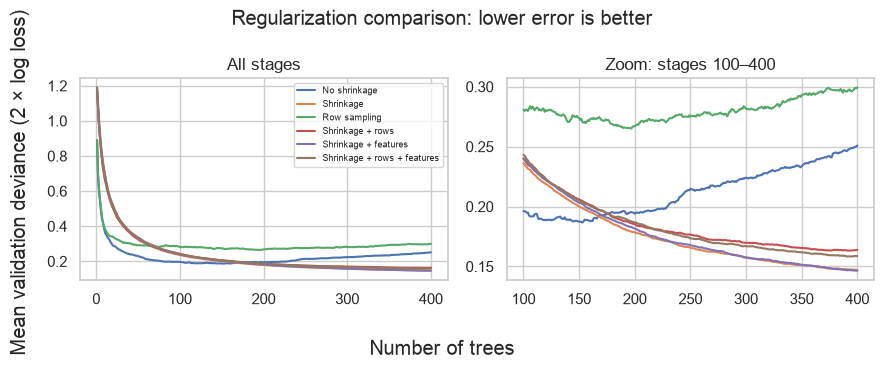

In [262]:
# The zoomed panel makes differences between the later stages easier to see.
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for name in reg_settings:
    rows = reg_summary.loc[reg_summary.setting == name].sort_values('n_estimators')
    for ax, first_stage in zip(axes, [1, 100]):
        shown = rows.loc[rows.n_estimators >= first_stage]
        ax.plot(shown.n_estimators, shown.validation_deviance, label=name)
axes[0].set_title('All stages')
axes[1].set_title('Zoom: stages 100–400')
axes[0].legend(fontsize=6.5)
fig.supxlabel('Number of trees')
fig.supylabel('Mean validation deviance (2 × log loss)')
fig.suptitle('Regularization comparison: lower error is better')
plt.tight_layout()
plt.show()


In [263]:
reg_best = reg_best_by_case.iloc[0]
reg_best_params = dict(reg_tree_params, **reg_settings[reg_best.setting],
                       n_estimators=int(reg_best.n_estimators))
print(f'Best tested case: {reg_best.setting}')
display(pd.Series(reg_best_params, name='Selected parameter value'))
print(f'Mean CV deviance: {reg_best.validation_deviance:.4f}')
print(f'Mean CV accuracy: {reg_best.validation_accuracy:.2%}')
print(f'Fold accuracy standard deviation: {reg_best.std_validation_accuracy:.2%}')


Best tested case: Shrinkage + features


max_leaf_nodes              9
min_samples_leaf           20
min_samples_split           5
max_depth                None
random_state               42
loss                 log_loss
learning_rate             0.2
subsample                 1.0
max_features              0.2
n_estimators              400
Name: Selected parameter value, dtype: object

Mean CV deviance: 0.1465
Mean CV accuracy: 97.33%
Fold accuracy standard deviation: 0.46%


### 35. Check overfitting for the chosen case
Falling fitting error with a sustained rise in validation error suggests
overfitting. A gap alone does not prove it. The shaded band shows one standard
error across folds; the vertical line marks the tree count with lowest mean
validation deviance. This selects a prefix after fitting, not an early exit.


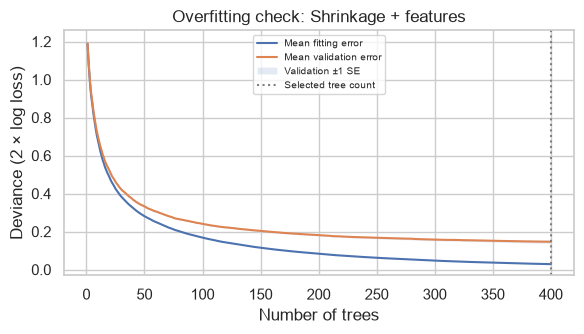

In [264]:
reg_selected_curve = reg_summary.loc[reg_summary.setting == reg_best.setting].sort_values('n_estimators')
reg_curve_se = reg_selected_curve.std_validation_deviance / np.sqrt(len(cv_splits))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(reg_selected_curve.n_estimators, reg_selected_curve.train_deviance, label='Mean fitting error')
ax.plot(reg_selected_curve.n_estimators, reg_selected_curve.validation_deviance, label='Mean validation error')
ax.fill_between(reg_selected_curve.n_estimators, reg_selected_curve.validation_deviance - reg_curve_se,
                reg_selected_curve.validation_deviance + reg_curve_se, alpha=.15, label='Validation ±1 SE')
ax.axvline(reg_best.n_estimators, color='gray', linestyle=':', label='Selected tree count')
ax.set(xlabel='Number of trees', ylabel='Deviance (2 × log loss)', title=f'Overfitting check: {reg_best.setting}')
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()


In [265]:
reg_selected_folds = reg_history.loc[(reg_history.setting == reg_best.setting) &
                                     (reg_history.n_estimators == reg_best.n_estimators)].copy()
reg_selected_folds['accuracy_gap'] = reg_selected_folds.train_accuracy - reg_selected_folds.validation_accuracy
display(reg_selected_folds[['fold', 'train_accuracy', 'validation_accuracy',
                            'validation_phishing_recall', 'accuracy_gap']].round(4))


,fold,train_accuracy,validation_accuracy,validation_phishing_recall,accuracy_gap
1999,1,0.9998,0.9685,0.9665,0.0313
4399,2,0.9997,0.9738,0.9653,0.0258
6799,3,0.9997,0.9777,0.9722,0.0220


### 36. Refit and evaluate the chosen classifier
Use the selected settings on all original training rows. Reuse the same filtered
holdout as the manual model, so the classification metrics describe the same emails.
Predicted probabilities are model estimates; calibration has not been assessed.


In [266]:
reg_model = GradientBoostingClassifier(**reg_best_params)
reg_model.fit(X_train, y_train)
reg_train_probabilities = reg_model.predict_proba(X_train)[:, 1]
reg_test_probabilities = reg_model.predict_proba(gb_X_test)[:, 1]
reg_train_predictions = (reg_train_probabilities >= .5).astype(int)
reg_test_predictions = (reg_test_probabilities >= .5).astype(int)
reg_train_accuracy = np.mean(reg_train_predictions == y_train)
reg_test_accuracy = np.mean(reg_test_predictions == gb_y_test)
print(f'Training accuracy: {reg_train_accuracy:.2%}')
print(f'Holdout accuracy: {reg_test_accuracy:.2%}')
print(f'Holdout deviance: {2 * log_loss(gb_y_test, reg_test_probabilities, labels=[0, 1]):.4f}')
print(classification_report(gb_y_test, reg_test_predictions, labels=[0, 1],
                            target_names=['Safe', 'Phishing'], zero_division=0))


Training accuracy: 99.94%
Holdout accuracy: 97.62%
Holdout deviance: 0.1376
              precision    recall  f1-score   support

        Safe       0.98      0.98      0.98      2159
    Phishing       0.97      0.97      0.97      1240

    accuracy                           0.98      3399
   macro avg       0.97      0.97      0.97      3399
weighted avg       0.98      0.98      0.98      3399



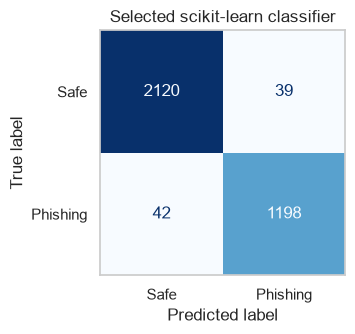

In [267]:
fig, ax = plt.subplots(figsize=(4, 3.5))
ConfusionMatrixDisplay.from_predictions(gb_y_test, reg_test_predictions,
    labels=[0, 1], display_labels=['Safe', 'Phishing'], cmap='Blues', colorbar=False, ax=ax)
ax.grid(False)
ax.set_title('Selected scikit-learn classifier')
plt.tight_layout()
plt.show()


In [268]:
# Compare classification accuracy; the two models use different training losses.
reg_accuracy_comparison = pd.DataFrame({
    'model': ['Manual boosting (previous section)', 'Scikit-learn regularization winner'],
    'training_accuracy': [gb_train_accuracy, reg_train_accuracy],
    'holdout_accuracy': [gb_test_accuracy, reg_test_accuracy],
}).set_index('model')
reg_accuracy_comparison['accuracy_gap'] = (reg_accuracy_comparison.training_accuracy -
                                         reg_accuracy_comparison.holdout_accuracy)
display(reg_accuracy_comparison.round(4))


,training_accuracy,holdout_accuracy,accuracy_gap
model,,,
Manual boosting (previous section),0.9807,0.9568,0.0240
Scikit-learn regularization winner,0.9994,0.9762,0.0232


### 38 Comments on hyperparameter tuning and classification performance

I compared **six regularization cases** using **three grouped folds**, checking every stage from 1 to 400. This evaluates **2,400 case/tree-count combinations** from 18 model fits. I selected the lowest mean validation deviance, following the linked example's error measure.

The best tested case was **Shrinkage + features**:

| Parameter | Selected value |
|---|---|
| Number of trees | 400 |
| Learning rate | 0.2 |
| Fraction of rows used per stage | 1 |
| Candidate feature fraction (`max_features`) | 0.2 (approximately 20% per split) |
| Maximum leaves per tree | 9 |
| Minimum emails per leaf | 20 |

Mean CV deviance was **0.1465** and mean CV accuracy was **97.33%**, with an accuracy standard deviation of **0.46 percentage points** across folds. The no-shrinkage case's best mean CV deviance was **0.1867** at **153 trees**.

On the same **3,399 holdout emails**, accuracy was **97.62%**, phishing precision **96.85%**, recall **96.61%**, and F1 **0.967**. There were **39 false alarms and 42 missed phishing emails**. The previous manual model's holdout accuracy was **95.68%**. This comparison includes a change from squared-error boosting to a log-loss classifier, so any difference cannot be attributed only to regularization.

## 40 Early stopping with grouped validation
In the next step we will add early stopping and use the learning rate of 0.2, sampling, and leaf limits fixed. Grow each of the three fold models by 10 trees at a time with `warm_start=True`. Stop after five checks without an improvement of more than 0.0001, or at 1,000 trees. Five checks allow up to **50 additional trees** while waiting for improvement.

Use the existing grouped folds and fold-specific TF-IDF. Built-in validation splitting is disabled because it does not preserve our email groups. The final model uses the best checkpoint accepted by the tolerance rule, not the last
checkpoint fitted during the patience period. 


In [269]:
es_controls = dict(max_trees=1000, step=10, patience=5, tolerance=0.0001)
es_folds = [make_boosting_fold(*split) for split in cv_splits]
display(pd.Series(es_controls, name='Early-stopping controls'))


max_trees    1000.0000
step           10.0000
patience        5.0000
tolerance       0.0001
Name: Early-stopping controls, dtype: float64

### 41. Stop training when validation progress stalls
The helper keeps the trees already fitted and adds only the next batch. It
returns the selected count, the check history, and the fold models for plotting.
The tolerance defines a meaningful improvement; tiny changes do not reset patience.


In [270]:
def choose_tree_count(params, folds, max_trees=1000, step=10,
                      patience=5, tolerance=0.0001):
    """Stop on stalled mean grouped validation deviance; retain the best checkpoint.

    Each fold is (X_fit, y_fit, X_valid, y_valid). Return the selected tree count,
    a DataFrame of validation checks, and models fitted through the stopping check.
    """
    models = [GradientBoostingClassifier(
        **{**params, 'warm_start': True, 'n_iter_no_change': None}) for _ in folds]
    best_error, best_count, stale_checks = np.inf, 0, 0
    records = []
    for count in range(step, max_trees + 1, step):
        fold_errors = []
        for model, (X_fit, y_fit, X_valid, y_valid) in zip(models, folds):
            model.set_params(n_estimators=count)
            model.fit(X_fit, y_fit)
            fold_errors.append(2 * log_loss(y_valid, model.predict_proba(X_valid), labels=[0, 1]))
        mean_error = np.mean(fold_errors)
        if mean_error < best_error - tolerance:
            best_error, best_count, stale_checks = mean_error, count, 0
        else:
            stale_checks += 1
        records.append({'n_estimators': count, 'validation_deviance': mean_error,
                        'best_tree_count': best_count, 'stale_checks': stale_checks})
        if count % 50 == 0 or stale_checks >= patience:
            print(f'{count} trees: CV deviance={mean_error:.4f}; checks without improvement={stale_checks}')
        if stale_checks >= patience:
            break
    return best_count, pd.DataFrame(records), models


In [271]:
es_best_count, es_checks, es_models = choose_tree_count(reg_best_params, es_folds, **es_controls)
es_last_check = es_checks.iloc[-1]
es_stopped_at = int(es_last_check.n_estimators)
es_stopping_triggered = es_last_check.stale_checks >= es_controls['patience']
print('Stopping reason:', 'Patience exhausted' if es_stopping_triggered else 'Maximum tree count reached')
print(f'Last fitted checkpoint: {es_stopped_at} trees')
print(f'Selected checkpoint: {es_best_count} trees')
display(es_checks.tail(8).round(5))


50 trees: CV deviance=0.3320; checks without improvement=0
100 trees: CV deviance=0.2405; checks without improvement=0
150 trees: CV deviance=0.2031; checks without improvement=0
200 trees: CV deviance=0.1817; checks without improvement=0
250 trees: CV deviance=0.1679; checks without improvement=0
300 trees: CV deviance=0.1575; checks without improvement=0
350 trees: CV deviance=0.1514; checks without improvement=0
400 trees: CV deviance=0.1465; checks without improvement=0
450 trees: CV deviance=0.1437; checks without improvement=0
500 trees: CV deviance=0.1420; checks without improvement=0
550 trees: CV deviance=0.1416; checks without improvement=1
590 trees: CV deviance=0.1421; checks without improvement=5
Stopping reason: Patience exhausted
Last fitted checkpoint: 590 trees
Selected checkpoint: 540 trees


,n_estimators,validation_deviance,best_tree_count,stale_checks
51,520,0.14202,500,2
52,530,0.14191,500,3
53,540,0.14171,540,0
54,550,0.14164,540,1
55,560,0.14227,540,2
56,570,0.14218,540,3
57,580,0.14189,540,4
58,590,0.14211,540,5


### 42. Examine error and accuracy across the folds
Reuse the earlier staged-metrics helper to inspect the fitted paths. This does
not fit more trees. Compare the selected checkpoint with the previous 400-tree
setting on the same folds, and inspect both error and classification performance.


In [272]:
es_fold_results = []
for fold, (model, data) in enumerate(zip(es_models, es_folds), start=1):
    X_fit, y_fit, X_valid, y_valid = data
    fitting = classifier_metrics_by_stage(model, X_fit, y_fit)
    validation = classifier_metrics_by_stage(model, X_valid, y_valid)
    history = fitting.add_prefix('train_').join(validation.add_prefix('validation_'))
    es_fold_results.append(history.reset_index().assign(fold=fold))
es_history = pd.concat(es_fold_results, ignore_index=True)
es_summary = es_history.groupby('n_estimators', as_index=False).agg(
    train_deviance=('train_deviance', 'mean'), validation_deviance=('validation_deviance', 'mean'),
    train_accuracy=('train_accuracy', 'mean'), validation_accuracy=('validation_accuracy', 'mean'),
    std_validation_accuracy=('validation_accuracy', 'std'),
    phishing_recall=('validation_phishing_recall', 'mean'))
es_summary['accuracy_gap'] = es_summary.train_accuracy - es_summary.validation_accuracy
es_selected = es_summary.loc[es_summary.n_estimators == es_best_count].iloc[0]


In [273]:
es_cv_comparison = pd.DataFrame([reg_best, es_selected],
    index=['Previous 400-tree model', 'Early-stopping selection'])
es_cv_columns = ['n_estimators', 'validation_deviance', 'train_accuracy',
                 'validation_accuracy', 'std_validation_accuracy', 'phishing_recall', 'accuracy_gap']
display(es_cv_comparison[es_cv_columns].round(4))


,n_estimators,validation_deviance,train_accuracy,validation_accuracy,std_validation_accuracy,phishing_recall,accuracy_gap
Previous 400-tree model,400.0,0.1465,0.9997,0.9733,0.0046,0.9680,0.0264
Early-stopping selection,540.0,0.1417,0.9998,0.9724,0.0027,0.9697,0.0274


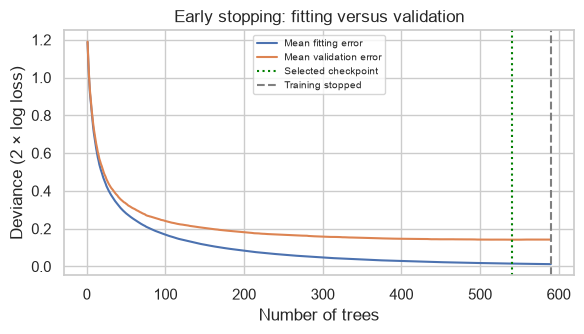

In [274]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(es_summary.n_estimators, es_summary.train_deviance, label='Mean fitting error')
ax.plot(es_summary.n_estimators, es_summary.validation_deviance, label='Mean validation error')
ax.axvline(es_best_count, color='green', linestyle=':', label='Selected checkpoint')
ax.axvline(es_stopped_at, color='gray', linestyle='--', label='Training stopped')
ax.set(xlabel='Number of trees', ylabel='Deviance (2 × log loss)', title='Early stopping: fitting versus validation')
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()


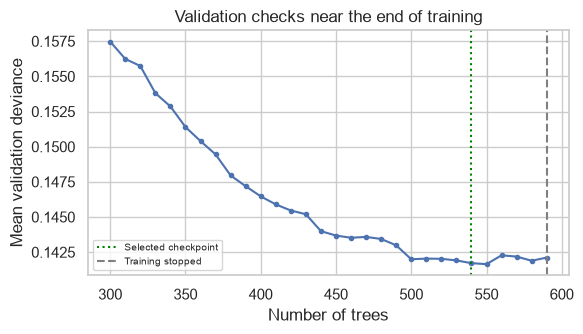

In [275]:
# Zoom in on the final checks so a plateau or rise is visible.
es_recent_checks = es_checks.tail(30)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(es_recent_checks.n_estimators, es_recent_checks.validation_deviance, 'o-', markersize=3)
ax.axvline(es_best_count, color='green', linestyle=':', label='Selected checkpoint')
ax.axvline(es_stopped_at, color='gray', linestyle='--', label='Training stopped')
ax.set(xlabel='Number of trees', ylabel='Mean validation deviance', title='Validation checks near the end of training')
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()


### 43. Refit the selected count and compare the holdout
Refit a fresh classifier on all training rows using the selected count. The
fold models contain the extra trees fitted while waiting through patience;
those extra trees are not used in this final model. Reuse the existing 400-tree
classifier as the baseline and keep the 0.5 classification threshold fixed.


In [276]:
es_params = {**reg_best_params, 'n_estimators': int(es_best_count),
             'warm_start': False, 'n_iter_no_change': None}
es_model = GradientBoostingClassifier(**es_params)
es_model.fit(X_train, y_train)


GradientBoostingClassifier(learning_rate=0.2, max_depth=None, max_features=0.2,
                           max_leaf_nodes=9, min_samples_leaf=20,
                           min_samples_split=5, n_estimators=540,
                           random_state=42)

In [277]:
def compare_email_classifier(model, X_fit, y_fit, X_holdout, y_holdout):
    """Return training/holdout accuracy, phishing metrics, and error counts."""
    fit_probabilities = model.predict_proba(X_fit)[:, 1]
    holdout_probabilities = model.predict_proba(X_holdout)[:, 1]
    predictions = (holdout_probabilities >= .5).astype(int)
    report = classification_report(y_holdout, predictions, labels=[0, 1],
                                   output_dict=True, zero_division=0)
    training_accuracy = np.mean((fit_probabilities >= .5) == y_fit)
    return {'trees': model.n_estimators_, 'training_accuracy': training_accuracy,
            'holdout_accuracy': report['accuracy'], 'accuracy_gap': training_accuracy - report['accuracy'],
            'holdout_deviance': 2 * log_loss(y_holdout, holdout_probabilities, labels=[0, 1]),
            'phishing_precision': report['1']['precision'], 'phishing_recall': report['1']['recall'],
            'phishing_f1': report['1']['f1-score'],
            'false_alarms': int(np.sum((predictions == 1) & (y_holdout == 0))),
            'missed_phishing': int(np.sum((predictions == 0) & (y_holdout == 1)))}


In [278]:
es_baseline_metrics = compare_email_classifier(reg_model, X_train, y_train, gb_X_test, gb_y_test)
es_final_metrics = compare_email_classifier(es_model, X_train, y_train, gb_X_test, gb_y_test)
es_holdout_comparison = pd.DataFrame([es_baseline_metrics, es_final_metrics],
    index=['Previous 400-tree model', 'Early-stopping selection'])
display(es_holdout_comparison[['trees', 'training_accuracy', 'holdout_accuracy',
                              'accuracy_gap', 'holdout_deviance']].round(4))
display(es_holdout_comparison[['phishing_precision', 'phishing_recall', 'phishing_f1',
                              'false_alarms', 'missed_phishing']].round(4))


,trees,training_accuracy,holdout_accuracy,accuracy_gap,holdout_deviance
Previous 400-tree model,400,0.9994,0.9762,0.0232,0.1376
Early-stopping selection,540,0.9998,0.9756,0.0242,0.1261


,phishing_precision,phishing_recall,phishing_f1,false_alarms,missed_phishing
Previous 400-tree model,0.9685,0.9661,0.9673,39,42
Early-stopping selection,0.9677,0.9653,0.9665,40,43


              precision    recall  f1-score   support

        Safe       0.98      0.98      0.98      2159
    Phishing       0.97      0.97      0.97      1240

    accuracy                           0.98      3399
   macro avg       0.97      0.97      0.97      3399
weighted avg       0.98      0.98      0.98      3399



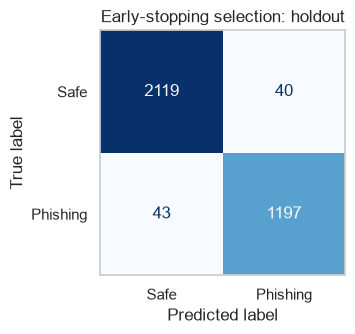

In [279]:
es_predictions = (es_model.predict_proba(gb_X_test)[:, 1] >= .5).astype(int)
print(classification_report(gb_y_test, es_predictions, labels=[0, 1],
                            target_names=['Safe', 'Phishing'], zero_division=0))
fig, ax = plt.subplots(figsize=(4, 3.5))
ConfusionMatrixDisplay.from_predictions(gb_y_test, es_predictions,
    labels=[0, 1], display_labels=['Safe', 'Phishing'], cmap='Blues', colorbar=False, ax=ax)
ax.grid(False)
ax.set_title('Early-stopping selection: holdout')
plt.tight_layout()
plt.show()


### 44 Comments on early stopping and classification performance

Early stopping helps regularization by limiting tree growth when validation
improvement stalls. The selected **540-tree model** lowered validation and holdout
deviance compared with 400 trees, although the accuracy gap widened slightly.



## 50 Tune leaf limits with grouped early stopping
Compare maximum leaf counts **5, 7, 9, and 11**, each with minimum leaf sizes
**20 and 40 emails**. This tests eight combinations in the current
`GradientBoostingClassifier`, rather than carrying a leaf limit over from the
manual squared-error model.

Keep learning rate **0.2**, row fraction **1.0**, and feature fraction **0.2** fixed.
Reuse the three grouped folds and the same stopping controls: add 10 trees per
check, patience 5, tolerance 0.0001, maximum 1,000 trees. The previous **9-leaf / 20-email**
run is reused because it used exactly these settings and folds.

Rank by mean validation deviance. To favor stronger leaf restrictions when scores
are close, consider models within one standard error of the best score and prefer
fewer leaves per tree, then more emails per leaf, then fewer trees. Show the lowest
error and the selected regularized option separately. Holdout labels do not choose either.


In [280]:
leaf_maximums = [5, 7, 9, 11]
leaf_minimums = [20, 40]
leaf_controls = es_controls.copy()
leaf_base_params = es_params.copy()
leaf_previous_key = (leaf_base_params['max_leaf_nodes'], leaf_base_params['min_samples_leaf'])
print('Combinations:', [(leaves, minimum) for leaves in leaf_maximums for minimum in leaf_minimums])
print('Stopping controls:', leaf_controls)


Combinations: [(5, 20), (5, 40), (7, 20), (7, 40), (9, 20), (9, 40), (11, 20), (11, 40)]
Stopping controls: {'max_trees': 1000, 'step': 10, 'patience': 5, 'tolerance': 0.0001}


### 51. Reuse the fitted paths to collect fold metrics
This helper calls the existing staged-prediction helper. It measures error,
accuracy, and phishing recall without fitting additional trees.


In [281]:
def collect_classifier_fold_metrics(models, folds):
    """Combine staged training and validation metrics for fitted fold models."""
    records = []
    for fold, (model, data) in enumerate(zip(models, folds), start=1):
        X_fit, y_fit, X_valid, y_valid = data
        fitting = classifier_metrics_by_stage(model, X_fit, y_fit)
        validation = classifier_metrics_by_stage(model, X_valid, y_valid)
        history = fitting.add_prefix('train_').join(validation.add_prefix('validation_'))
        records.append(history.reset_index().assign(fold=fold))
    return pd.concat(records, ignore_index=True)


### 52. Run the eight combinations
Each combination chooses its own stopping checkpoint. Seven combinations require
new training; the earlier 9-leaf / 20-email run supplies the eighth comparison.
Fitting rows and validation rows remain identical across cases. This cell takes
several minutes on the full dataset.


In [282]:
leaf_runs, leaf_histories, leaf_check_histories = [], [], []
for leaves in leaf_maximums:
    for minimum in leaf_minimums:
        print(f'CASE: maximum leaves={leaves}, minimum emails per leaf={minimum}')
        params = {**leaf_base_params, 'max_leaf_nodes': leaves, 'min_samples_leaf': minimum}
        if (leaves, minimum) == leaf_previous_key:
            count, checks, history = es_best_count, es_checks.copy(), es_history.copy()
            print('Reusing the previous identical grouped run.')
        else:
            count, checks, models = choose_tree_count(params, es_folds, **leaf_controls)
            history = collect_classifier_fold_metrics(models, es_folds)
        leaf_runs.append({'max_leaf_nodes': leaves, 'min_samples_leaf': minimum,
                          'n_estimators': count, 'stopped_at': int(checks.iloc[-1].n_estimators),
                          'patience_triggered': bool(checks.iloc[-1].stale_checks >= leaf_controls['patience'])})
        leaf_histories.append(history.assign(max_leaf_nodes=leaves, min_samples_leaf=minimum))
        leaf_check_histories.append(checks.assign(max_leaf_nodes=leaves, min_samples_leaf=minimum))
        print(f'Finished case: selected {count} trees; fitted through {int(checks.iloc[-1].n_estimators)}')
leaf_history = pd.concat(leaf_histories, ignore_index=True)
leaf_checks = pd.concat(leaf_check_histories, ignore_index=True)


CASE: maximum leaves=5, minimum emails per leaf=20
50 trees: CV deviance=0.4592; checks without improvement=0
100 trees: CV deviance=0.3350; checks without improvement=0
150 trees: CV deviance=0.2796; checks without improvement=0
200 trees: CV deviance=0.2442; checks without improvement=0
250 trees: CV deviance=0.2214; checks without improvement=0
300 trees: CV deviance=0.2057; checks without improvement=0
350 trees: CV deviance=0.1929; checks without improvement=0
400 trees: CV deviance=0.1835; checks without improvement=0
450 trees: CV deviance=0.1760; checks without improvement=0
500 trees: CV deviance=0.1706; checks without improvement=0
550 trees: CV deviance=0.1646; checks without improvement=0
600 trees: CV deviance=0.1605; checks without improvement=0
650 trees: CV deviance=0.1571; checks without improvement=0
700 trees: CV deviance=0.1543; checks without improvement=0
750 trees: CV deviance=0.1531; checks without improvement=0
800 trees: CV deviance=0.1506; checks without impr

In [283]:
leaf_keys = ['max_leaf_nodes', 'min_samples_leaf', 'n_estimators']
leaf_scores = leaf_history.groupby(leaf_keys, as_index=False).agg(
    train_deviance=('train_deviance', 'mean'), validation_deviance=('validation_deviance', 'mean'),
    std_validation_deviance=('validation_deviance', 'std'),
    train_accuracy=('train_accuracy', 'mean'), validation_accuracy=('validation_accuracy', 'mean'),
    std_validation_accuracy=('validation_accuracy', 'std'),
    phishing_recall=('validation_phishing_recall', 'mean'))
leaf_scores['accuracy_gap'] = leaf_scores.train_accuracy - leaf_scores.validation_accuracy
leaf_scores['deviance_se'] = leaf_scores.std_validation_deviance / np.sqrt(len(es_folds))
leaf_results = pd.DataFrame(leaf_runs).merge(leaf_scores, on=leaf_keys).sort_values('validation_deviance')
leaf_columns = leaf_keys + ['validation_deviance', 'validation_accuracy', 'phishing_recall',
                           'accuracy_gap', 'stopped_at', 'patience_triggered']
display(leaf_results[leaf_columns].round(4))


,max_leaf_nodes,min_samples_leaf,n_estimators,validation_deviance,validation_accuracy,phishing_recall,accuracy_gap,stopped_at,patience_triggered
1,5,40,990,0.1380,0.9746,0.9714,0.0251,1000,False
5,9,40,530,0.1384,0.9749,0.9716,0.0248,580,True
6,11,20,460,0.1386,0.9722,0.9689,0.0276,510,True
7,11,40,390,0.1413,0.9723,0.9700,0.0275,440,True
3,7,40,630,0.1413,0.9748,0.9714,0.0248,680,True
4,9,20,540,0.1417,0.9724,0.9697,0.0274,590,True
2,7,20,760,0.1425,0.9727,0.9694,0.0272,810,True
0,5,20,980,0.1463,0.9725,0.9697,0.0272,1000,False


### 53. Select using validation performance and leaf restrictions
The one-standard-error limit is the lowest mean validation deviance plus its
standard error across folds. Among eligible cases, prefer **fewer leaves per tree**,
then **more emails per leaf**, then fewer trees. This is a practical regularization
rule, not proof that models have equal performance. Fewer leaves per tree can still
require more boosting trees, so the overall ensemble is not necessarily smaller.


In [284]:
leaf_best_score = leaf_results.iloc[0]
leaf_error_limit = leaf_best_score.validation_deviance + leaf_best_score.deviance_se
leaf_eligible = leaf_results.loc[leaf_results.validation_deviance <= leaf_error_limit]
leaf_selected = leaf_eligible.sort_values(
    ['max_leaf_nodes', 'min_samples_leaf', 'n_estimators', 'validation_deviance'],
    ascending=[True, False, True, True]).iloc[0]
leaf_previous = leaf_results.loc[(leaf_results.max_leaf_nodes == leaf_previous_key[0]) &
                                 (leaf_results.min_samples_leaf == leaf_previous_key[1])].iloc[0]
leaf_cv_comparison = pd.DataFrame([leaf_previous, leaf_best_score, leaf_selected],
    index=['Previous 9 leaves / 20 emails', 'Lowest CV error', 'Selected regularized model'])
display(leaf_cv_comparison[leaf_keys + ['validation_deviance', 'train_accuracy',
    'validation_accuracy', 'phishing_recall', 'accuracy_gap']].round(4))
print(f'One-standard-error deviance limit: {leaf_error_limit:.4f}')


,max_leaf_nodes,min_samples_leaf,n_estimators,validation_deviance,train_accuracy,validation_accuracy,phishing_recall,accuracy_gap
Previous 9 leaves / 20 emails,9,20,540,0.1417,0.9998,0.9724,0.9697,0.0274
Lowest CV error,5,40,990,0.1380,0.9997,0.9746,0.9714,0.0251
Selected regularized model,5,40,990,0.1380,0.9997,0.9746,0.9714,0.0251


One-standard-error deviance limit: 0.1471


### 54. Inspect tuning performance and overfitting
Each point below uses that combination's own stopping checkpoint. Error bars
show one standard error across folds. Judge the accuracy gap together with
validation performance and phishing recall; a smaller gap alone can also result
from underfitting.


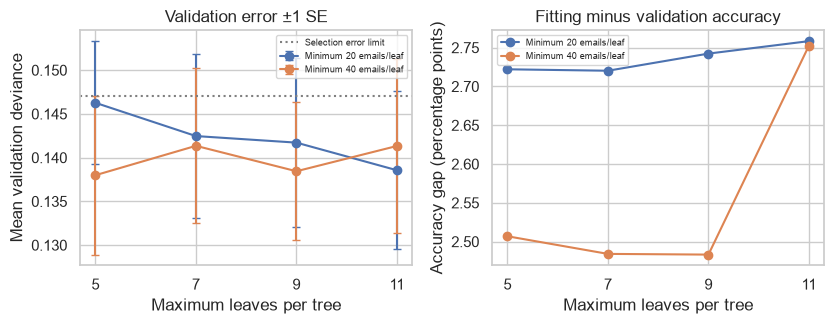

In [285]:
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.4))
for minimum, rows in leaf_results.groupby('min_samples_leaf'):
    rows = rows.sort_values('max_leaf_nodes')
    axes[0].errorbar(rows.max_leaf_nodes, rows.validation_deviance, yerr=rows.deviance_se,
                     marker='o', capsize=3, label=f'Minimum {minimum} emails/leaf')
    axes[1].plot(rows.max_leaf_nodes, 100 * rows.accuracy_gap, 'o-', label=f'Minimum {minimum} emails/leaf')
axes[0].axhline(leaf_error_limit, color='gray', linestyle=':', label='Selection error limit')
axes[0].set(ylabel='Mean validation deviance', title='Validation error ±1 SE')
axes[1].set(ylabel='Accuracy gap (percentage points)', title='Fitting minus validation accuracy')
for ax in axes:
    ax.set(xlabel='Maximum leaves per tree', xticks=leaf_maximums)
    ax.legend(fontsize=6.5)
plt.tight_layout()
plt.show()


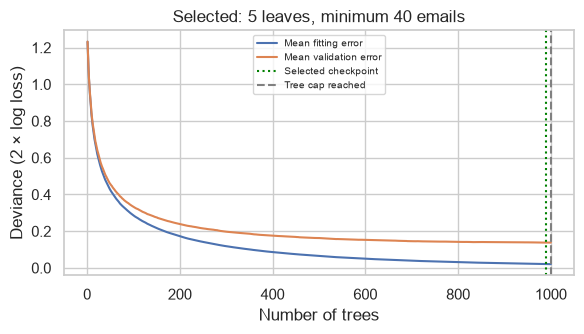

In [286]:
leaf_selected_curve = leaf_scores.loc[
    (leaf_scores.max_leaf_nodes == leaf_selected.max_leaf_nodes) &
    (leaf_scores.min_samples_leaf == leaf_selected.min_samples_leaf)].sort_values('n_estimators')
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(leaf_selected_curve.n_estimators, leaf_selected_curve.train_deviance, label='Mean fitting error')
ax.plot(leaf_selected_curve.n_estimators, leaf_selected_curve.validation_deviance, label='Mean validation error')
ax.axvline(leaf_selected.n_estimators, color='green', linestyle=':', label='Selected checkpoint')
if leaf_selected.stopped_at != leaf_selected.n_estimators:
    ax.axvline(leaf_selected.stopped_at, color='gray', linestyle='--',
               label='Patience stop' if leaf_selected.patience_triggered else 'Tree cap reached')
ax.set(xlabel='Number of trees', ylabel='Deviance (2 × log loss)',
       title=f'Selected: {int(leaf_selected.max_leaf_nodes)} leaves, minimum {int(leaf_selected.min_samples_leaf)} emails')
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()


### Conclussion on Leaf limits tweaking

Across eight combinations and three grouped folds, **5 maximum leaves, 40 minimum
emails per leaf, and 990 trees** gave the lowest mean validation deviance. Compared
with **9 leaves / 20 emails / 540 trees**, deviance fell **0.1417 → 0.1380**,
validation accuracy rose **97.24% → 97.46%**, and the fitting–validation accuracy
gap narrowed **2.74 → 2.51 percentage points**.

These modest gains support tuning **leaf limits and minimum leaf size jointly
with tree count**. This run reached the **1,000-tree cap**, giving us a reason
to extend the tree-count search later.


## 60 Ray Tune and Optuna search
Search **50 configurations**, with learning rates restricted to **0.1–0.3**.
Explicit starting trials test **0.1, 0.2, and 0.3**. Optuna's TPE sampler proposes
configurations; Ray Tune runs up to four trials concurrently and saves their results.
This is a bounded search, not a guarantee of a global optimum.

We reserve one grouped portion of the original training data for an **audit**
after model selection. Three inner grouped folds select parameters and tree counts
using only the remaining development rows. The existing holdout is evaluated last.
This audit is unseen by this search, although these emails participated in earlier
notebook experiments; it is not a new external dataset or full nested CV.

References: [Ray + Optuna](https://docs.ray.io/en/latest/tune/examples/optuna_example.html),
[TPE](https://optuna.readthedocs.io/en/v4.4.0/reference/samplers/generated/optuna.samplers.TPESampler.html),
[nested validation](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html).


In [304]:
# If needed in a new environment: %pip install "ray[tune]==2.60.0" "optuna==4.4.0"
import ray
from ray import tune
from ray.tune.search.optuna import OptunaSearch
from optuna.samplers import TPESampler

rt_trials = 50
rt_controls = dict(max_trees=1500, step=25, patience=4, tolerance=0.0001, min_trees=200)
rt_output = Path('artifacts/week9_ray_tune').resolve()
rt_output.mkdir(parents=True, exist_ok=True)
rt_run_name = 'phishing_tpe_' + pd.Timestamp.now().strftime('%Y%m%d_%H%M%S')
print('Ray version:', ray.__version__)
display(pd.Series(rt_controls, name='Grouped early-stopping controls'))


Ray version: 2.60.0


max_trees    1500.0000
step           25.0000
patience        4.0000
tolerance       0.0001
min_trees     200.0000
Name: Grouped early-stopping controls, dtype: float64

### 61. Reserve audit rows and fix fold preprocessing
Reuse original text retained in `train_df`; no dataset reload is needed.
The earlier notebook applied its 99th-percentile length cap before splitting.
Here the cap and TF-IDF vocabulary/IDF are learned **only from fitting rows**.
Recompute the nine count features after applying each fold's cap.
Earlier notebook variables and results remain available for comparison.


In [305]:
rt_pool = train_df[['text', TARGET_COLUMN, 'group_id', 'content_hash']].copy()
rt_pool['word_text'] = rt_pool['text'].map(clean_email_text)  # Restore uncapped words.
rt_outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=2718)
rt_dev_rows, rt_audit_rows = next(rt_outer.split(
    rt_pool['text'], rt_pool[TARGET_COLUMN], rt_pool['group_id']))
rt_dev = rt_pool.iloc[rt_dev_rows].reset_index(drop=True)
rt_audit = rt_pool.iloc[rt_audit_rows].reset_index(drop=True)
assert set(rt_dev.group_id).isdisjoint(rt_audit.group_id)
rt_inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
rt_splits = list(rt_inner.split(rt_dev['text'], rt_dev[TARGET_COLUMN], rt_dev.group_id))
display(pd.Series({'Development rows': len(rt_dev), 'Reserved audit rows': len(rt_audit),
                   'Original holdout rows': len(test_df)}, name='Rows before text-match filtering'))


Development rows         11404
Reserved audit rows       2705
Original holdout rows     3402
Name: Rows before text-match filtering, dtype: int64

In [306]:
def make_tuning_fold(fitting, validation):
    """Fit the length cap and TF-IDF on fitting rows; return matrices and metadata.

    Inputs contain uncapped word_text, original text, labels, and group_id.
    Remove validation texts matching capped fitting text. Return the usual
    (X_fit, y_fit, X_valid, y_valid) tuple plus the fitted preprocessing details.
    """
    assert set(fitting.group_id).isdisjoint(validation.group_id)
    fitting, validation = fitting.copy(), validation.copy()
    cutoff = int(np.ceil(fitting.word_text.str.len().quantile(.99)))
    fitting['word_text'] = fitting.word_text.str.slice(stop=cutoff)
    validation['word_text'] = validation.word_text.str.slice(stop=cutoff)
    keep = ~validation.word_text.isin(fitting.word_text)
    validation = validation.loc[keep]
    fit_counts, _ = extract_count_features(fitting)
    valid_counts, _ = extract_count_features(validation)
    vectorizer = TfidfVectorizer(**tfidf_vectorizer.get_params())
    X_fit = sparse.hstack([vectorizer.fit_transform(fitting.word_text), fit_counts],
                         format='csr', dtype=np.float32)
    X_valid = sparse.hstack([vectorizer.transform(validation.word_text), valid_counts],
                           format='csr', dtype=np.float32)
    data = (X_fit, fitting[TARGET_COLUMN].to_numpy(), X_valid, validation[TARGET_COLUMN].to_numpy())
    details = {'cutoff': cutoff, 'vectorizer': vectorizer, 'validation_mask': keep,
               'fit_rows': len(fitting), 'validation_rows': len(validation),
               'excluded_matches': int((~keep).sum())}
    assert set(fitting.word_text).isdisjoint(validation.word_text)
    return data, details


In [307]:
# These fold matrices are prepared once and shared across all 50 trials.
rt_folds, rt_fold_details = [], []
for fit_rows, valid_rows in rt_splits:
    data, details = make_tuning_fold(rt_dev.iloc[fit_rows], rt_dev.iloc[valid_rows])
    rt_folds.append(data)
    rt_fold_details.append(details)
display(pd.DataFrame([{k: d[k] for k in ['cutoff', 'fit_rows', 'validation_rows', 'excluded_matches']}
                      for d in rt_fold_details], index=['Fold 1', 'Fold 2', 'Fold 3']))


,cutoff,fit_rows,validation_rows,excluded_matches
Fold 1,12862,7689,3714,1
Fold 2,13369,7497,3904,3
Fold 3,12986,7622,3778,4


### 62. Define the search space

Learning rate has a **continuous, non-logarithmic search range of 0.1–0.3**.
The explicit starting trials include 0.1, 0.2, and 0.3. Optuna uses random
sampling during startup, then TPE uses completed trial results to guide later
proposals; it does not sample uniformly throughout all 50 trials.

Depth ranges from **2 to 5**. The leaf ceiling ranges from **3 to
`min(15, 2 ** depth)`**, avoiding limits above the maximum leaves possible at
that depth. Minimum leaf sizes are **20, 40, 60, 80, or 120**.
`split_multiplier × min_samples_leaf` sets the split threshold: multiplier
**2** adds no restriction beyond requiring two valid leaves; **4** and **8** are stronger.

Row fraction ranges from **0.6 to 1.0** and candidate feature fraction from
**0.1 to 1.0**. `ccp_alpha` tests **0, 0.000001, 0.00001, 0.0001, and 0.001**;
zero leaves cost-complexity pruning disabled.

Reference: [Optuna TPE sampling and startup behavior](https://optuna.readthedocs.io/en/v4.4.0/reference/samplers/generated/optuna.samplers.TPESampler.html).


In [308]:
def tuning_search_space(trial):
    """Suggest one configuration, with leaf limits consistent with tree depth."""
    trial.suggest_float('learning_rate', 0.1, 0.3)
    depth = trial.suggest_int('max_depth', 2, 5)
    trial.suggest_int('max_leaf_nodes', 3, min(15, 2 ** depth))
    trial.suggest_categorical('min_samples_leaf', [20, 40, 60, 80, 120])
    trial.suggest_categorical('split_multiplier', [2, 4, 8])
    trial.suggest_float('subsample', 0.6, 1.0)
    trial.suggest_float('max_features', 0.1, 1.0)
    trial.suggest_categorical('ccp_alpha', [0.0, 0.000001, 0.00001, 0.0001, 0.001])


def tuning_model_params(config):
    """Translate a search configuration into GradientBoostingClassifier settings."""
    params = dict(config)
    params['min_samples_split'] = params.pop('split_multiplier') * params['min_samples_leaf']
    return dict(params, random_state=42, loss='log_loss', n_iter_no_change=None)


In [309]:
# Include the old best tree shape at each reference learning rate.
rt_reference = dict(max_depth=4, max_leaf_nodes=5, min_samples_leaf=40,
    split_multiplier=2, subsample=1.0, max_features=0.2, ccp_alpha=0.0)
rt_starting_points = [dict(rt_reference, learning_rate=rate) for rate in [0.1, 0.2, 0.3]]
rt_starting_points.append(dict(rt_reference, learning_rate=0.2, max_depth=3, max_leaf_nodes=7))
display(pd.DataFrame(rt_starting_points))


,max_depth,max_leaf_nodes,min_samples_leaf,split_multiplier,subsample,max_features,ccp_alpha,learning_rate
0,4,5,40,2,1.0,0.2,0.0,0.1
1,4,5,40,2,1.0,0.2,0.0,0.2
2,4,5,40,2,1.0,0.2,0.0,0.3
3,3,7,40,2,1.0,0.2,0.0,0.2


### 63. Score trials and choose the tree count

Each trial fits three grouped-fold models with warm starts, adding **25 trees**
at a time. It records the checkpoint with the **lowest mean validation deviance
(2 × log loss)**, along with its fold standard error, accuracy, recall, and
fitting–validation accuracy gap.

The patience counter resets only when loss improves by **more than 0.0001**
relative to the last accepted patience reference. After at least **200 evaluated
trees**, **four consecutive checks** without such improvement stop the trial;
otherwise fitting can reach the **1,500-tree cap**. The selected lowest-loss
checkpoint can be earlier than 200 trees and can include improvements smaller
than the patience tolerance.

This uses our grouped folds instead of the classifier's internal random split.
ASHA is not used: every configuration gets the same within-trial stopping rule.
Refit the chosen tree count because the stopping models include extra trees
used to check patience.


In [310]:
def grouped_tuning_trial(config, folds, controls):
    """Report grouped validation metrics to Ray, retaining the best tree count."""
    models = [GradientBoostingClassifier(**tuning_model_params(config),
              warm_start=True, n_estimators=controls['step']) for _ in folds]
    best_loss, patience_loss, stale = np.inf, np.inf, 0
    for count in range(controls['step'], controls['max_trees'] + 1, controls['step']):
        measurements = []
        for model, (X_fit, y_fit, X_valid, y_valid) in zip(models, folds):
            model.set_params(n_estimators=count)
            model.fit(X_fit, y_fit)
            fit_prob = model.predict_proba(X_fit)
            valid_prob = model.predict_proba(X_valid)
            valid_pred = valid_prob[:, 1] >= .5
            measurements.append([
                2 * log_loss(y_valid, valid_prob, labels=[0, 1]),
                2 * log_loss(y_fit, fit_prob, labels=[0, 1]),
                np.mean((fit_prob[:, 1] >= .5) == y_fit),
                np.mean(valid_pred == y_valid), np.mean(valid_pred[y_valid == 1])])
        values = np.asarray(measurements)
        loss, train_loss, train_acc, valid_acc, recall = values.mean(axis=0)
        if loss < best_loss:
            best_loss = loss
            best = dict(cv_deviance=float(loss), deviance_se=float(values[:, 0].std(ddof=1) / np.sqrt(len(folds))),
                selected_trees=count, train_deviance=float(train_loss), train_accuracy=float(train_acc),
                validation_accuracy=float(valid_acc), phishing_recall=float(recall),
                accuracy_gap=float(train_acc - valid_acc))
        if loss < patience_loss - controls['tolerance']:
            patience_loss, stale = loss, 0
        else:
            stale += 1
        stop = count >= controls['min_trees'] and stale >= controls['patience']
        tune.report(dict(best, trees_evaluated=count, current_validation_deviance=float(loss),
                         stale_checks=stale, patience_triggered=bool(stop)))
        if stop:
            break


In [311]:
rt_started_ray = not ray.is_initialized()
if rt_started_ray:
    ray.init(num_cpus=4, include_dashboard=False, log_to_driver=False,
             object_store_memory=1_000_000_000)
rt_search = OptunaSearch(space=tuning_search_space, metric='cv_deviance', mode='min',
    sampler=TPESampler(seed=42), points_to_evaluate=rt_starting_points)
rt_trainable = tune.with_parameters(grouped_tuning_trial, folds=rt_folds, controls=rt_controls)
rt_tuner = tune.Tuner(tune.with_resources(rt_trainable, {'cpu': 1}),
    tune_config=tune.TuneConfig(search_alg=rt_search, num_samples=rt_trials, max_concurrent_trials=4),
    run_config=tune.RunConfig(name=rt_run_name, storage_path=str(rt_output), verbose=0))
rt_results = rt_tuner.fit()
print('Experiment directory:', rt_results.experiment_path)
print('Completed configurations:', len(rt_results))


2026-11-22 16:52:38,324	INFO tune.py:1007 -- Wrote the latest version of all result files and experiment state to '/Users/debasishhalder/projects/BU-DX799/artifacts/week9_ray_tune/phishing_tpe_20261122_163031' in 0.0186s.


Experiment directory: /Users/debasishhalder/projects/BU-DX799/artifacts/week9_ray_tune/phishing_tpe_20261122_163031
Completed configurations: 50


### 64. Select using inner validation only

Identify the trial with the lowest mean deviance, then apply a
**one-standard-error heuristic**. An eligible alternative must have:

- Mean deviance no greater than the best mean plus that trial's estimated standard error (`fold standard deviation / sqrt(3)`).
- Mean phishing recall **no more than 0.5 percentage points below** the lowest-loss trial's recall; higher recall is allowed.

Among eligible trials, prefer lower depth, fewer maximum leaves, larger minimum
leaf size, then fewer trees; lower deviance breaks any remaining tie. This
depth-first preference does not guarantee a smaller ensemble on every measure.
The rule is applied before audit or holdout evaluation. Three-fold standard
errors are a practical selection heuristic, not a confidence guarantee.


In [312]:
assert all(result.error is None for result in rt_results), 'Inspect failed trials before selection.'
rt_records = []
for result in rt_results:
    row = dict(result.config, **{k: result.metrics[k] for k in ['cv_deviance', 'deviance_se',
        'selected_trees', 'train_accuracy', 'validation_accuracy', 'phishing_recall',
        'accuracy_gap', 'trees_evaluated', 'patience_triggered']})
    row['trial_id'] = result.metrics['trial_id']
    rt_records.append(row)
rt_table = pd.DataFrame(rt_records).sort_values('cv_deviance').reset_index(drop=True)
rt_best = rt_table.iloc[0]
rt_limit = rt_best.cv_deviance + rt_best.deviance_se
rt_eligible = rt_table.loc[(rt_table.cv_deviance <= rt_limit) &
    (rt_table.phishing_recall >= rt_best.phishing_recall - .005)]
rt_selected = rt_eligible.sort_values(
    ['max_depth', 'max_leaf_nodes', 'min_samples_leaf', 'selected_trees', 'cv_deviance'],
    ascending=[True, True, False, True, True]).iloc[0]
rt_selected_result = next(r for r in rt_results if r.metrics['trial_id'] == rt_selected.trial_id)
rt_selected_params = dict(tuning_model_params(rt_selected_result.config),
    n_estimators=int(rt_selected.selected_trees), warm_start=False)
display(rt_table.head(10).round(4))
display(pd.DataFrame([rt_best, rt_selected], index=['Lowest validation loss', 'Selected shallower model']).round(4))
display(pd.Series(rt_selected_params, name='Selected classifier parameters'))
rt_table.to_csv(rt_output / (rt_run_name + '_trials.csv'), index=False)
pd.Series(rt_selected_params).to_json(rt_output / (rt_run_name + '_selected_params.json'), indent=2)
if rt_started_ray:
    ray.shutdown()


,learning_rate,max_depth,max_leaf_nodes,min_samples_leaf,split_multiplier,subsample,max_features,ccp_alpha,cv_deviance,deviance_se,selected_trees,train_accuracy,validation_accuracy,phishing_recall,accuracy_gap,trees_evaluated,patience_triggered,trial_id
0,0.2000,4,5,40,2,1.0000,0.2000,0.0,0.1458,0.0053,975,0.9999,0.9726,0.9683,0.0273,1075,True,bae6a317
1,0.2836,4,15,40,2,0.9712,0.1937,0.0,0.1473,0.0052,625,0.9999,0.9734,0.9706,0.0265,725,True,b8a6f7a2
2,0.2000,3,7,40,2,1.0000,0.2000,0.0,0.1477,0.0050,1100,0.9996,0.9728,0.9676,0.0268,1150,True,c95a9053
3,0.1022,5,8,40,2,0.9786,0.6408,0.0,0.1478,0.0057,1275,1.0000,0.9726,0.9671,0.0274,1375,True,6baacad8
4,0.3000,4,5,40,2,1.0000,0.2000,0.0,0.1481,0.0049,575,0.9996,0.9718,0.9671,0.0279,675,True,fc6a2047
5,0.1000,4,5,40,2,1.0000,0.2000,0.0,0.1485,0.0042,1500,0.9994,0.9728,0.9666,0.0266,1500,False,c2170cbb
6,0.2533,4,8,40,2,0.9748,0.1869,0.0,0.1491,0.0048,725,0.9999,0.9714,0.9667,0.0285,825,True,7d400f4f
7,0.2884,4,15,40,2,0.9688,0.2146,0.0,0.1491,0.0072,600,0.9999,0.9714,0.9654,0.0284,700,True,175ff9db
8,0.2916,4,15,40,2,0.9878,0.1955,0.0,0.1491,0.0060,575,0.9997,0.9724,0.9647,0.0273,675,True,4dce7a38
9,0.2970,4,6,40,2,0.9911,0.2352,0.0,0.1500,0.0062,600,0.9999,0.9728,0.9677,0.0272,700,True,fdeaac47


,learning_rate,max_depth,max_leaf_nodes,min_samples_leaf,split_multiplier,subsample,max_features,ccp_alpha,cv_deviance,deviance_se,selected_trees,train_accuracy,validation_accuracy,phishing_recall,accuracy_gap,trees_evaluated,patience_triggered,trial_id
Lowest validation loss,0.2,4,5,40,2,1.0,0.2,0.0,0.1458,0.0053,975,0.9999,0.9726,0.9683,0.0273,1075,True,bae6a317
Selected shallower model,0.2,3,7,40,2,1.0,0.2,0.0,0.1477,0.0050,1100,0.9996,0.9728,0.9676,0.0268,1150,True,c95a9053


learning_rate             0.2
max_depth                   3
max_leaf_nodes              7
min_samples_leaf           40
subsample                 1.0
max_features              0.2
ccp_alpha                 0.0
min_samples_split          80
random_state               42
loss                 log_loss
n_iter_no_change         None
n_estimators             1100
warm_start              False
Name: Selected classifier parameters, dtype: object

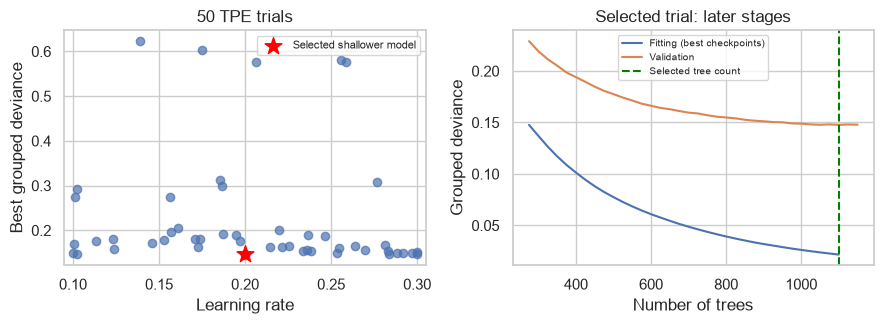

In [313]:
# Plot all trials and the selected trial's actual validation trajectory.
rt_progress = rt_selected_result.metrics_dataframe.sort_values('trees_evaluated')
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].scatter(rt_table.learning_rate, rt_table.cv_deviance, alpha=.7)
axes[0].scatter(rt_selected.learning_rate, rt_selected.cv_deviance,
                marker='*', s=160, color='red', label='Selected shallower model')
axes[0].set(xlabel='Learning rate', ylabel='Best grouped deviance', title='50 TPE trials', xlim=(.095, .305))
axes[0].legend(fontsize=8)
rt_curve_start = max(25, int(rt_selected.selected_trees / 4))
rt_late_progress = rt_progress.loc[rt_progress.trees_evaluated >= rt_curve_start]
rt_improving = rt_progress.drop_duplicates('selected_trees')
rt_improving = rt_improving.loc[rt_improving.selected_trees >= rt_curve_start]
axes[1].plot(rt_improving.selected_trees, rt_improving.train_deviance,
             label='Fitting (best checkpoints)')
axes[1].plot(rt_late_progress.trees_evaluated, rt_late_progress.current_validation_deviance,
             label='Validation')
axes[1].axvline(rt_selected.selected_trees, color='green', linestyle='--', label='Selected tree count')
axes[1].set(xlabel='Number of trees', ylabel='Grouped deviance', title='Selected trial: later stages')
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()


### 65. Audit the frozen selection
The audit is evaluated **after** all parameters and the tree count are frozen.
Fit the selected model and the previous 990-tree configuration on the same
development rows using the new preprocessing. The baseline is rerun because
changing preprocessing and validation partitions makes old scores non-comparable.
Audit scores are for assessment; do not switch parameters after viewing them.


In [314]:
rt_audit_data, rt_audit_details = make_tuning_fold(rt_dev, rt_audit)
rt_X_dev, rt_y_dev, rt_X_audit, rt_y_audit = rt_audit_data
rt_baseline_params = leaf_selected_params.copy()  # Previous 5-leaf / 990-tree model.
rt_audit_models, rt_audit_rows_metrics = {}, []
for name, params in [('Previous 990-tree model', rt_baseline_params),
                     ('Ray/Optuna selected model', rt_selected_params)]:
    model = GradientBoostingClassifier(**params).fit(rt_X_dev, rt_y_dev)
    rt_audit_models[name] = model
    rt_audit_rows_metrics.append(compare_email_classifier(model, rt_X_dev, rt_y_dev, rt_X_audit, rt_y_audit))
rt_audit_comparison = pd.DataFrame(rt_audit_rows_metrics, index=rt_audit_models).rename(columns={
    'holdout_accuracy': 'audit_accuracy', 'holdout_deviance': 'audit_deviance'})
display(rt_audit_comparison.round(4))
print('Audit rows evaluated:', len(rt_y_audit))


,trees,training_accuracy,audit_accuracy,accuracy_gap,audit_deviance,phishing_precision,phishing_recall,phishing_f1,false_alarms,missed_phishing
Previous 990-tree model,990,0.9996,0.9697,0.0299,0.1389,0.9523,0.9674,0.9598,49,33
Ray/Optuna selected model,1100,0.9994,0.9715,0.0279,0.1424,0.9578,0.9664,0.9621,43,34


Audit rows evaluated: 2705


### 66. Refit on all original training rows and evaluate the holdout
Keep the frozen selected parameters and tree count. Learn preprocessing from
all original training rows, then apply it to the existing holdout. These holdout
emails have been inspected in prior experiments, so this remains a development
comparison, not proof of performance on new incoming email.


In [315]:
rt_holdout_pool = test_df[['text', TARGET_COLUMN, 'group_id', 'content_hash']].copy()
rt_holdout_pool['word_text'] = rt_holdout_pool['text'].map(clean_email_text)
rt_final_data, rt_final_preprocessing = make_tuning_fold(rt_pool, rt_holdout_pool)
rt_X_train, rt_y_train, rt_X_test, rt_y_test = rt_final_data
rt_final_models, rt_final_rows = {}, []
for name, params in [('Previous 990-tree model', rt_baseline_params),
                     ('Ray/Optuna selected model', rt_selected_params)]:
    model = GradientBoostingClassifier(**params).fit(rt_X_train, rt_y_train)
    rt_final_models[name] = model
    rt_final_rows.append(compare_email_classifier(model, rt_X_train, rt_y_train, rt_X_test, rt_y_test))
rt_final_comparison = pd.DataFrame(rt_final_rows, index=rt_final_models)
rt_model = rt_final_models['Ray/Optuna selected model']
display(rt_final_comparison.round(4))
print('Holdout rows evaluated:', len(rt_y_test))
rt_audit_comparison.to_csv(rt_output / (rt_run_name + '_audit.csv'))
rt_final_comparison.to_csv(rt_output / (rt_run_name + '_holdout.csv'))


,trees,training_accuracy,holdout_accuracy,accuracy_gap,holdout_deviance,phishing_precision,phishing_recall,phishing_f1,false_alarms,missed_phishing
Previous 990-tree model,990,0.9994,0.9750,0.0244,0.1254,0.9684,0.9629,0.9656,39,46
Ray/Optuna selected model,1100,0.9992,0.9776,0.0216,0.1243,0.9709,0.9677,0.9693,36,40


Holdout rows evaluated: 3399


              precision    recall  f1-score   support

        Safe     0.9815    0.9833    0.9824      2159
    Phishing     0.9709    0.9677    0.9693      1240

    accuracy                         0.9776      3399
   macro avg     0.9762    0.9755    0.9759      3399
weighted avg     0.9776    0.9776    0.9776      3399



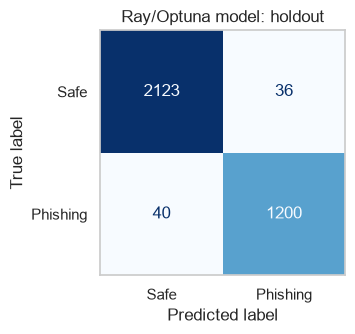

In [316]:
rt_predictions = (rt_model.predict_proba(rt_X_test)[:, 1] >= .5).astype(int)
print(classification_report(rt_y_test, rt_predictions, labels=[0, 1],
    target_names=['Safe', 'Phishing'], digits=4, zero_division=0))
fig, ax = plt.subplots(figsize=(4, 3.5))
ConfusionMatrixDisplay.from_predictions(rt_y_test, rt_predictions, labels=[0, 1],
    display_labels=['Safe', 'Phishing'], cmap='Blues', colorbar=False, ax=ax)
ax.set_title('Ray/Optuna model: holdout')
ax.grid(False)
plt.tight_layout()
plt.show()


In [317]:
# Confirm how the selected restrictions affected the actual fitted trees.
rt_tree_details = pd.DataFrame([{'depth': tree.get_depth(), 'leaves': tree.get_n_leaves(),
    'smallest_leaf': tree.tree_.n_node_samples[tree.tree_.children_left == -1].min()}
    for tree in rt_model.estimators_.ravel()])
display(rt_tree_details.agg(['min', 'mean', 'max']).round(2))
display(rt_final_comparison[['training_accuracy', 'holdout_accuracy', 'accuracy_gap',
    'phishing_recall', 'missed_phishing']].round(4))


,depth,leaves,smallest_leaf
min,3.0,4.00,40.00
mean,3.0,5.19,43.77
max,3.0,7.00,208.00


,training_accuracy,holdout_accuracy,accuracy_gap,phishing_recall,missed_phishing
Previous 990-tree model,0.9994,0.9750,0.0244,0.9629,46
Ray/Optuna selected model,0.9992,0.9776,0.0216,0.9677,40


### 67 Comments on hyperparameter tuning and classification performance

I completed **50 Ray Tune trials** using Optuna's TPE sampler. Learning rates
were restricted to **0.1–0.3**, with explicit starting trials at **0.1, 0.2, and
0.3**. The search also varied depth, leaves, minimum leaf size, split threshold,
row sampling, feature sampling, and pruning. Each trial chose its tree count
using three inner grouped folds and early stopping, up to 1,500 trees.
**42 trials** stopped through patience and
**8 trials** reached the tree cap; these two groups did not overlap in this run.

The lowest inner-validation deviance was **0.1458**, at **975 trees**, depth
**4**, and **5 maximum leaves** (learning rate **0.2**, minimum leaf size **40**).
The predefined
one-standard-error/recall rule selected a shallower candidate with deviance
**0.1477**, mean validation accuracy
**97.28%**, phishing recall
**96.76%**, and a fitting–validation accuracy gap of
**2.68 percentage points**. The eligibility loss limit was
**0.1512**. This is the selected configuration within the tested
space and selection rule, not a guaranteed global optimum. Both the lowest-loss
configuration and the selected shallower configuration were among the explicit
starting cases; their tree counts were chosen by the grouped validation checks.

| Parameter | Selected value |
|---|---:|
| `n_estimators` | 1100 |
| `learning_rate` | 0.2 |
| `max_depth` | 3 |
| `max_leaf_nodes` | 7 |
| `min_samples_leaf` | 40 |
| `min_samples_split` | 80 |
| `subsample` | 1 |
| `max_features` | 0.2 |
| `ccp_alpha` | 0 |

The selection rule prioritizes lower depth. This model permits more leaves and
uses more boosting stages than the lowest-loss trial, so it is not uniformly
smaller on every measure of complexity. Validation scores determine eligibility; the later audit assesses
that tradeoff without changing the selection. With 40 emails per leaf, a split needs at least
80 emails anyway; the selected split threshold of 80 adds no extra restriction.

I froze these parameters and the tree count before evaluating the reserved audit.
Both models were refitted on the same development rows with fold-safe preprocessing.
The audit contains **2,705 emails** after matching-text filtering.

| Measure | Previous 990-tree settings | Selected Ray/Optuna settings |
|---|---:|---:|
| Training accuracy | 99.96% | 99.94% |
| Audit accuracy | 96.97% | 97.15% |
| Audit deviance | 0.1389 | 0.1424 |
| Phishing precision | 95.23% | 95.78% |
| Phishing recall | 96.74% | 96.64% |
| Phishing F1 | 0.9598 | 0.9621 |
| Missed phishing emails | 33 | 34 |
| False alarms | 49 | 43 |
| Training–audit accuracy gap (pp) | 2.99 | 2.79 |

The audit results are mixed: selected-model accuracy is higher and the
training–audit gap is smaller, but deviance is worse and phishing recall is
slightly lower. It produces **six fewer false alarms and one additional missed
phishing email**. I did not change the selected parameters after viewing the audit.

I then refitted both configurations on all **14,109 original training
emails** and evaluated the same **3,399 filtered holdout emails**:

| Measure | Previous 990-tree settings | Selected Ray/Optuna settings |
|---|---:|---:|
| Training accuracy | 99.94% | 99.92% |
| Holdout accuracy | 97.50% | 97.76% |
| Holdout deviance | 0.1254 | 0.1243 |
| Phishing precision | 96.84% | 97.09% |
| Phishing recall | 96.29% | 96.77% |
| Phishing F1 | 0.9656 | 0.9693 |
| Missed phishing emails | 46 | 40 |
| False alarms | 39 | 36 |
| Training–holdout accuracy gap (pp) | 2.44 | 2.16 |

These baseline scores were recomputed with the corrected preprocessing. They
should be compared with the selected model in this table, rather than older
notebook scores produced using a corpus-wide length cap.

### 68 Actions I took to avoid overfitting and how I assessed whether they worked

- Reserved **2,705 emails from the original training set** for evaluation after
  hyperparameter selection. Used the remaining **11,404 training emails** for
  hyperparameter tuning with **three-fold grouped cross-validation**.
- Learned the text-length cutoff and TF-IDF separately inside each fitting fold,
  and recomputed count features after truncation. The final cutoff was learned
  only from the full training partition. Original notebook data was preserved.
- Kept normalized-text groups apart and excluded matching prepared text across
  fitting/evaluation partitions. Grouping catches these matches, not all paraphrases.
- Used explicit tree restrictions, shrinkage, row/feature sampling, and pruning
  in the search. The final model's actual maximum depth is
  **3**, its maximum leaf count is
  **7**, and its smallest leaf contains
  **40 sampled fitting emails**.
- Stopped when mean grouped validation loss stalled and refitted the selected
  checkpoint. A smaller fitting gap alone was not the optimization target.
- Used a one-standard-error heuristic plus a recall guard to prefer a shallower
  candidate with validation loss close to the best. Three-fold standard errors are approximate, not formal
  confidence intervals, and parallel TPE runs can propose different trials even
  with the same seed. The trial configurations and scores are saved for inspection.

The audit was unused by **this search**, but its emails appeared in earlier notebook
experiments. The holdout has also been viewed repeatedly. This is a single reserved
audit split, not a full nested-CV estimate or new external validation. Consequently,
these measurements assess the tradeoff but cannot prove that overfitting is absent.
